# Análise integrada das Etapas 1 a 7

Este notebook reúne as análises finais do QuestionInsight. Ele combina o recorte de usuários e questões produzido pelas Etapas 2 e 3, as métricas comportamentais calculadas na Etapa 4 e os misconceptions detectados pelo parser MC³ da Etapa 5.

O objetivo é produzir evidências estatísticas sobre a frequência dos misconceptions, sua associação com métricas de execução, sua distribuição entre grupos demográficos e seu comportamento no nível de cada episódio estudante–questão. Os arquivos gerados são derivados dessas fontes e não substituem os índices e resultados das etapas anteriores.

In [1]:
# ============================================================
# CONFIGURAÇÕES GLOBAIS DO NOTEBOOK
# ============================================================
from pathlib import Path
import json
import os
import numpy as np

# Diretórios: localizar a raiz da Etapa 5 independentemente do cwd do Jupyter.
# Todas as entradas são lidas dos caminhos locais do clone. O notebook não baixa
# arquivos de dados por URL nem altera a organização das etapas.

_candidatos_etapa5 = [Path.cwd(), Path.cwd() / "Etapa_5", Path.cwd().parent, Path.cwd().parent / "Etapa_5"]
_raizes_etapa5 = []
for _candidato in _candidatos_etapa5:
    _base = _candidato.resolve()
    if _base not in _raizes_etapa5:
        _raizes_etapa5.append(_base)
ETAPA5_DIR = next(
    (_base for _base in _raizes_etapa5
     if (_base / "3_Analise_Integrada_Misconceptions_Metricas.ipynb").is_file()
     or (_base / "output").is_dir()),
    None,
)
if ETAPA5_DIR is None:
    _procurados = "\n".join(f"  - {_base / 'output'}" for _base in _raizes_etapa5)
    raise FileNotFoundError(
        "Não foi possível localizar a pasta Etapa_5. "
        f"Pastas verificadas:\n{_procurados}"
    )
PROJECT_ROOT = ETAPA5_DIR.parent
OUTPUT_DIR = ETAPA5_DIR / "output"
DATASETS_DIR = PROJECT_ROOT / "DataSets"
RESULTS_DIR = OUTPUT_DIR / "resultados"
FIGURES_DIR = RESULTS_DIR / "figuras"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Arquivos de entrada e referências das etapas anteriores.
MODULOS_PATH = OUTPUT_DIR / "mapeamento_provas_questoes.json"
QUESTIONS_PATH = OUTPUT_DIR / "dataset_analise_questoes.csv"
MISCONCEPTIONS_PATH = OUTPUT_DIR / "misconceptions_detalhado_por_usuario.csv"
REFERENCES_PATH = PROJECT_ROOT / "Etapa_2" / "output" / "referencias_processamento.json"
INDEX_PATH = PROJECT_ROOT / "Etapa_3" / "output" / "indice_usuarios.json"
EXECUTIONS_PATH = PROJECT_ROOT / "Etapa_4" / "codebench-analytics-full" / "output" / "metrics" / "executions_by_student.csv"
ACTIONS_PATH = PROJECT_ROOT / "Etapa_4" / "codebench-analytics-full" / "output" / "metrics" / "actions_by_student.csv"
# Falhar com uma mensagem clara se o clone local estiver incompleto; não há fallback remoto.
ENTRADAS_LOCAIS = {
    "mapeamento_provas_questoes.json": MODULOS_PATH,
    "dataset_analise_questoes.csv": QUESTIONS_PATH,
    "misconceptions_detalhado_por_usuario.csv": MISCONCEPTIONS_PATH,
    "Etapa_2/output/referencias_processamento.json": REFERENCES_PATH,
    "Etapa_3/output/indice_usuarios.json": INDEX_PATH,
    "Etapa_4/codebench-analytics-full/output/metrics/executions_by_student.csv": EXECUTIONS_PATH,
    "Etapa_4/codebench-analytics-full/output/metrics/actions_by_student.csv": ACTIONS_PATH,
}
for _nome_entrada, _caminho_entrada in ENTRADAS_LOCAIS.items():
    if not _caminho_entrada.is_file():
        raise FileNotFoundError(
            f"Arquivo obrigatório não encontrado no caminho local esperado: {_caminho_entrada} "
            f"(entrada: {_nome_entrada}). Confirme que as etapas anteriores e seus dados estão no clone."
        )
USUARIOS_PATH = REFERENCES_PATH
USER_DATA_PATH = REFERENCES_PATH
OUTPUT_PATH = RESULTS_DIR / "metricas_execucao_por_estudante_questao.csv"
METRICAS_INDIVIDUAIS_PATH = RESULTS_DIR / "metricas_individuais_por_estudante.csv"
# Filtros da análise de questões e PC³.
MIN_QUESTAO_RESPOSTAS = 16
# Parâmetros editoriais usados no texto metodológico do artigo.
# O tamanho dos dados é calculado automaticamente a partir da pasta DataSets.
NUMERO_TURMAS = None  # calculado dinamicamente no manifesto da Etapa 2
PC3_MIN_OCCURRENCES = 50
TOP_N_PC3 = None  # None = todos acima de PC3_MIN_OCCURRENCES; ou um inteiro, como 10.
MIN_CORRELATION_OBSERVATIONS = 5
TOP_MISCONCEPTIONS = None  # None = todos os PC³ que passam PC3_MIN_OCCURRENCES; inteiro = limita os mais frequentes
ALPHA = 0.05  # nível de significância após ajuste de múltiplos testes

# Mapeamento completo dos códigos PC³ presentes no CSV.
PC3_MAP = {code: code for code in (
    'A2', 'A3', 'A4', 'A5', 'B4', 'B6', 'B8', 'B9', 'B10', 'B11', 'B12',
    'C1', 'C2', 'C3', 'C4', 'C8', 'D4', 'E1', 'E2', 'G4', 'G5', 'H1'
)}
PC3_COLUNAS_BASE = list(PC3_MAP)

# Tradução das métricas usadas nas correlações e nos relatórios.
traducao_metricas = {
    'taxa_acerto': 'taxa de acerto', 'num_submissoes': 'submissões',
    'taxa_aceitacao': 'taxa de aceitação', 'num_testes': 'testes',
    'num_consultas': 'consultas', 'num_erros_lgcs': 'erros lógicos',
    'num_errors_stx': 'erros sintaxe', 'num_erros': 'erros totais',
    'num_eventos': 'eventos totais', 'num_eventos_del': 'eventos deleção',
    'tempo_implementacao': 'tempo implementação',
    'qtd_alteracoes_codigo': 'alterações código', 'discriminacao': 'discriminação',
}
METRICAS_POSITIVAS = {'taxa_acerto', 'taxa_aceitacao', 'discriminacao'}
METRICAS_DECIMAIS = {'taxa_acerto', 'taxa_aceitacao', 'discriminacao'}
PADRAO_NOTA = r"[-+]?\d+(?:[.,]\d+)?"


def interpretar_rho(rho):
    """Classifica a força da correlação de Spearman para os relatórios."""
    if rho is None:
        return 'sem correlação'
    valor = abs(float(rho))
    if valor >= 0.70:
        return 'forte'
    if valor >= 0.50:
        return 'moderada'
    if valor >= 0.30:
        return 'fraca'
    return 'muito fraca ou nula'


def benjamini_hochberg(p_values):
    """Retorna p-valores ajustados pelo procedimento de Benjamini-Hochberg."""
    p = np.asarray(p_values, dtype=float)
    adjusted = np.full(p.shape, np.nan, dtype=float)
    valid = np.isfinite(p)
    if not np.any(valid):
        return adjusted
    values = np.clip(p[valid], 0.0, 1.0)
    order = np.argsort(values)
    ordered = values[order]
    m = len(ordered)
    ranks = np.arange(1, m + 1, dtype=float)
    corrected = ordered * m / ranks
    corrected = np.minimum.accumulate(corrected[::-1])[::-1]
    corrected = np.clip(corrected, 0.0, 1.0)
    restored = np.empty_like(corrected)
    restored[order] = corrected
    adjusted[valid] = restored
    return adjusted


## 1. Configuração, fontes e critérios de inclusão

A célula seguinte localiza a raiz do clone local, cria `Etapa_5/output/resultados/` e lê as entradas nos caminhos relativos do próprio repositório: `Etapa_5/output/` para os arquivos principais, `Etapa_2/output/`, `Etapa_3/output/` e `Etapa_4/codebench-analytics-full/output/metrics/` para os dados das etapas anteriores. O notebook não baixa esses arquivos por URL; se algum caminho estiver ausente, a execução informa qual arquivo local precisa ser restaurado.

O filtro padrão exige pelo menos 16 respostas por questão (`MIN_QUESTAO_RESPOSTAS = 16`). A seleção de PC³ utiliza o catálogo completo definido em `PC3_MAP`, aplica `PC3_MIN_OCCURRENCES` e, quando configurados, respeita `TOP_N_PC3` ou `TOP_MISCONCEPTIONS`. Não há uma lista fixa de apenas B4, B8 e B9 para as tabelas; esses códigos recebem regras específicas de elegibilidade somente nas análises em que isso foi definido. As correlações exigem pelo menos cinco observações e usam `ALPHA = 0,05` como referência de significância.

In [2]:
from pathlib import Path
import json
import csv

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


def carregar_estrutura_completa():
    with MODULOS_PATH.open('r', encoding='utf-8') as f:
        return json.load(f)


def contar_questoes_totais(estrutura):
    """Questões únicas da base geral de assessments mantida pela Etapa 2."""
    questoes = set()
    for provas in estrutura.get('mapeamento_provas', {}).values():
        for prova_data in provas.values():
            for turma_info in prova_data.values():
                info = turma_info.get('info', {})
                for questoes_lista in info.get('exercises', {}).values():
                    questoes.update(str(q) for q in questoes_lista)
    return len(questoes)


def contar_turmas_referencias(data, ids_usuarios=None):
    """Conta escopos/turmas unicos registrados no manifesto da Etapa 2.

    A Etapa 2 registra cada raiz de usuario como um caminho relativo, normalmente
    no formato ``ano-semestre/turma/users/usuario``. A turma e identificada pelos
    dois primeiros componentes do caminho (periodo, id da turma), evitando contar
    usuarios, assessments ou questoes como turmas.
    """
    escopos = set()
    ids_usuarios = None if ids_usuarios is None else {str(x) for x in ids_usuarios}
    for usuario in data.get('users', []):
        if ids_usuarios is not None and str(usuario.get('id')) not in ids_usuarios:
            continue
        for raiz in usuario.get('roots', []) or []:
            partes = [str(p) for p in Path(str(raiz)).parts if str(p) not in ('', '.')]
            # Formato: dataset/periodo/turma/users/aluno.
            # A turma é periodo + ID da pasta imediatamente antes de users.
            if len(partes) >= 3:
                escopos.add((partes[1], partes[2]))
        # Compatibilidade com manifestos que registram o escopo diretamente.
        for chave in ('scope', 'class_scope', 'turma', 'class_name'):
            valor = usuario.get(chave)
            if valor not in (None, ''):
                escopos.add((str(valor),))
    if not escopos:
        for assessment in data.get('assessments', []):
            for chave in ('scope', 'class_scope', 'turma', 'class_name'):
                valor = assessment.get(chave)
                if valor not in (None, ''):
                    escopos.add((str(valor),))
    return len(escopos)

def _primeiro_valor(registro, chaves, padrao=None):
    for chave in chaves:
        valor = registro.get(chave)
        if valor not in (None, ''):
            return valor
    return padrao


def construir_mapa_auditoria_amostra(data, questoes_filtradas, estudantes_filtrados):
    """Constrói um mapa auditável da amostra final filtrada.

    O mapa preserva caminhos absolutos, associa usuários às turmas, vincula
    assessments às questões e registra os códigos por questão/assessment. Ele
    não altera os manifestos originais.
    """
    questoes_ids = {id_questao(row) for row in questoes_filtradas if id_questao(row)}
    usuarios_filtrados = {str(x) for x in estudantes_filtrados}
    assessments = {}
    for item in data.get('assessments', []):
        aid = str(_primeiro_valor(item, ('id', 'assessment_id', 'assessment'), ''))
        if not aid:
            continue
        qids = {str(q) for q in item.get('question_ids', item.get('questions', []))}
        assessments[aid] = {
            'assessment_id': aid,
            'titulo': _primeiro_valor(item, ('title', 'assessment_title', 'name'), ''),
            'tipo': str(_primeiro_valor(item, ('type', 'assessment_type'), '')).lower(),
            'grupo_tp': _primeiro_valor(item, ('grupo_tp', 'tp_group', 'group', 'tag', 'label'), None),
            'questoes': sorted(qids & questoes_ids, key=str),
            'questoes_manifesto': sorted(qids, key=str),
        }
    turma_map = {}
    for user in data.get('users', []):
        uid = str(user.get('id', ''))
        if uid not in usuarios_filtrados:
            continue
        for raiz in user.get('roots', []) or []:
            caminho = (Path(data['_source_root']) / str(raiz)).resolve()
            partes = [str(x) for x in Path(str(raiz)).parts if str(x) not in ('', '.')]
            # Formato esperado: dataset/periodo/turma/users/aluno.
            # Exemplo: cb_dataset_2016_1_v1.81/2016-1/111/users/1082
            if len(partes) < 3:
                continue
            periodo = partes[1]
            id_turma = partes[2]
            turma_id = f'{periodo}/{id_turma}'
            caminho_turma = caminho.parents[1] if len(caminho.parents) > 1 else caminho
            registro = turma_map.setdefault(turma_id, {
                'turma_id': turma_id,
                'periodo': periodo,
                'id_turma': id_turma,
                'caminho_absoluto': str(caminho_turma),
                'alunos': {},
                'assessments': {},
                'questoes': {},
                'codigos': 0,
            })
            registro['alunos'].setdefault(uid, {'id': uid, 'caminho_absoluto': str(caminho)})
            for item in user.get('files', {}).get('codes', []) or []:
                rel = str(item.get('path', ''))
                caminho_codigo = (Path(data['_source_root']) / rel).resolve()
                nome = caminho_codigo.stem
                partes_nome = nome.split('_')
                aid = str(_primeiro_valor(item, ('assessment_id', 'assessment'), partes_nome[0] if partes_nome else ''))
                qid = str(_primeiro_valor(item, ('question_id', 'question', 'questao'), partes_nome[1] if len(partes_nome) > 1 else ''))
                if qid not in questoes_ids or aid not in assessments:
                    continue
                if assessments[aid].get('tipo') not in ('exam', ''):
                    continue
                registro['codigos'] += 1
                registro['assessments'].setdefault(aid, {
                    **{k: v for k, v in assessments[aid].items() if k not in ('questoes', 'questoes_manifesto')},
                    'grupo_tp': assessments[aid].get('grupo_tp'),
                    'questoes': {},
                })
                qreg = registro['assessments'][aid]['questoes'].setdefault(qid, {'questao': qid, 'codigos': 0, 'arquivos': []})
                qreg['codigos'] += 1
                qreg['arquivos'].append(str(caminho_codigo))
                registro['questoes'].setdefault(qid, {'questao': qid, 'assessments': [], 'codigos': 0})['codigos'] += 1
                if aid not in registro['questoes'][qid]['assessments']:
                    registro['questoes'][qid]['assessments'].append(aid)
    for turma in turma_map.values():
        turma['alunos'] = sorted(turma['alunos'].values(), key=lambda x: x['id'])
        turma['assessments'] = sorted(turma['assessments'].values(), key=lambda x: x['assessment_id'])
        turma['questoes'] = sorted(turma['questoes'].values(), key=lambda x: x['questao'])
    por_questao = {}
    for turma in turma_map.values():
        for q in turma['questoes']:
            item = por_questao.setdefault(q['questao'], {'questao': q['questao'], 'assessments': [], 'turmas': [], 'codigos': 0})
            item['codigos'] += q['codigos']
            item['turmas'].append(turma['turma_id'])
            for aid in q['assessments']:
                if aid not in item['assessments']:
                    item['assessments'].append(aid)
    questoes_verificadas = []
    por_tp = {}
    for qid in sorted(questoes_ids, key=str):
        refs = [a for a in assessments.values() if qid in a['questoes'] and a.get('tipo') in ('exam', '')]
        questoes_verificadas.append({
            'questao': qid,
            'encontrada_em_assessments_exam': bool(refs),
            'assessments': [{
                'assessment_id': a['assessment_id'],
                'titulo': a['titulo'],
                'grupo_tp': a['grupo_tp'],
                'tipo': a['tipo'],
            } for a in refs],
        })
        for a in refs:
            chave = a['grupo_tp'] or 'sem_tag_tp'
            por_tp.setdefault(chave, {'grupo_tp': chave, 'assessments': [], 'questoes': []})
            if a['assessment_id'] not in por_tp[chave]['assessments']:
                por_tp[chave]['assessments'].append(a['assessment_id'])
            if qid not in por_tp[chave]['questoes']:
                por_tp[chave]['questoes'].append(qid)
    return {
        'criterio': 'questões com 16 ou mais respostas; assessments exam mantidos pela Etapa 2',
        'questoes_filtradas': sorted(questoes_ids, key=str),
        'quantidade_questoes_filtradas': len(questoes_ids),
        'quantidade_alunos_filtrados': len(usuarios_filtrados),
        'turmas': sorted(turma_map.values(), key=lambda x: x['turma_id']),
        'quantidade_turmas': len(turma_map),
        'questoes_verificadas': questoes_verificadas,
        'questoes_sem_assessment_exam': [q['questao'] for q in questoes_verificadas if not q['encontrada_em_assessments_exam']],
        'assessments_por_grupo_tp': sorted(por_tp.values(), key=lambda x: x['grupo_tp']),
        'questoes_mapeadas': sorted(por_questao.values(), key=lambda x: x['questao']),
        'quantidade_codigos_mapeados': sum(x['codigos'] for x in por_questao.values()),
        'observacao': 'Cada caminho foi convertido para absoluto com Path.resolve(); nenhum arquivo original foi alterado.',
    }


def carregar_base_geral_exam():
    """Conta a base geral diretamente do manifesto filtrado da Etapa 2."""
    if not REFERENCES_PATH.exists():
        return set(), set(), 0
    data = json.loads(REFERENCES_PATH.read_text(encoding='utf-8'))
    assessments = [a for a in data.get('assessments', [])
                   if str(a.get('type', '')).strip().lower() == 'exam']
    questoes = {str(q) for a in assessments for q in a.get('question_ids', [])}
    estudantes = {str(u.get('id')) for u in data.get('users', []) if u.get('id') is not None}
    codigos = sum(len(u.get('files', {}).get('codes', [])) for u in data.get('users', []))
    return questoes, estudantes, codigos


def carregar_datasets_analise():
    """Carrega as tabelas da Etapa 5 e normaliza a coluna de respostas."""
    questoes = []
    estudantes = set()
    if QUESTIONS_PATH.exists():
        with QUESTIONS_PATH.open('r', encoding='utf-8') as f:
            questoes = list(csv.DictReader(f))
    if MISCONCEPTIONS_PATH.exists():
        with MISCONCEPTIONS_PATH.open('r', encoding='utf-8') as f:
            for row in csv.DictReader(f):
                if row.get('usuario'):
                    estudantes.add(str(row['usuario']))
    return questoes, estudantes


def valor_respostas(row):
    for coluna in ('respostas', 'total_responses', 'num_respostas'):
        valor = row.get(coluna)
        if valor not in (None, ''):
            try:
                return int(float(valor))
            except (TypeError, ValueError):
                return 0
    return 0


def id_questao(row):
    return str(row.get('question') or row.get('questao') or row.get('id') or '')


def contar_estudantes_filtrados(questoes_filtradas):
    ids_questoes = {id_questao(row) for row in questoes_filtradas}
    estudantes = set()
    if MISCONCEPTIONS_PATH.exists():
        with MISCONCEPTIONS_PATH.open('r', encoding='utf-8') as f:
            for row in csv.DictReader(f):
                if id_questao(row) in ids_questoes and row.get('usuario'):
                    estudantes.add(str(row['usuario']))
    return estudantes


def main():
    print("=" * 70)
    print("LEVANTAMENTO DE INFORMAÇÕES — BASE GERAL E FILTRO 16+")
    print("=" * 70)
    print("\n PERÍODO DO LEVANTAMENTO:")
    print("   • Ano/Semestre Inicial: 2016/1")
    print("   • Ano/Semestre Final: 2024/1")
    print("   • Exclusões: 2020-ERE, 2020/1, 2020/2")
    print("   • Assessments: somente os assessments mantidos pela Etapa 2 (exam/TP)")

    try:
        estrutura = carregar_estrutura_completa()
        questoes_estrutura = contar_questoes_totais(estrutura)
    except FileNotFoundError:
        print(f"\n Arquivo não encontrado: {MODULOS_PATH}")
        questoes_estrutura = 0

    questoes_gerais_set, estudantes_gerais, codigos_gerais = carregar_base_geral_exam()
    manifesto_referencias = json.loads(REFERENCES_PATH.read_text(encoding='utf-8')) if REFERENCES_PATH.exists() else {}
    turmas_gerais = contar_turmas_referencias(manifesto_referencias)
    if turmas_gerais == 0 and NUMERO_TURMAS is not None:
        turmas_gerais = int(NUMERO_TURMAS)
    print(f"   • Turmas/escopos únicos calculados no manifesto: {turmas_gerais}")
    if not questoes_gerais_set:
        # Compatibilidade com execuções antigas sem o manifesto da Etapa 2.
        questoes_gerais_set = set(str(q) for q in range(questoes_estrutura))
    questoes, estudantes_csv = carregar_datasets_analise()
    questoes_filtradas = [row for row in questoes if valor_respostas(row) >= MIN_QUESTAO_RESPOSTAS]
    estudantes_filtrados = contar_estudantes_filtrados(questoes_filtradas)
    if not estudantes_gerais:
        estudantes_gerais = estudantes_csv
    if not codigos_gerais:
        codigos_gerais = sum(valor_respostas(row) for row in questoes)
    codigos_filtrados = sum(valor_respostas(row) for row in questoes_filtradas)
    turmas_filtradas = contar_turmas_referencias(manifesto_referencias, estudantes_filtrados)
    # Resolve a raiz física aqui, antes da chamada de main(), pois a função
    # carregar_referencias é definida posteriormente no notebook.
    manifesto_auditoria = dict(manifesto_referencias)
    raiz_manifesto = Path(manifesto_auditoria.get('source_root', '.'))
    if not raiz_manifesto.is_absolute():
        raiz_manifesto = (REFERENCES_PATH.parent / raiz_manifesto).resolve()
    manifesto_auditoria['_source_root'] = str(raiz_manifesto)
    mapa_auditoria_amostra = construir_mapa_auditoria_amostra(
        manifesto_auditoria, questoes_filtradas, estudantes_filtrados
    )
    mapa_auditoria_path = RESULTS_DIR / 'amostra_artigo_mapa_auditoria.json'
    mapa_auditoria_path.write_text(
        json.dumps(mapa_auditoria_amostra, ensure_ascii=False, indent=2), encoding='utf-8'
    )
    print(f"Mapa de auditoria da amostra salvo em: {mapa_auditoria_path}")

    print("\n" + "=" * 70)
    print("DADOS GERAIS — assessments/questões de exam mantidos pela Etapa 2")
    print("=" * 70)
    print(f"   • Questões únicas na base geral (exam): {len(questoes_gerais_set)}")
    print(f"   • Estudantes na base geral: {len(estudantes_gerais)}")
    print(f"   • Códigos analisados na base geral: {codigos_gerais}")
    print(f"   • Turmas na base geral: {turmas_gerais}")

    print("\n" + "=" * 70)
    print("DADOS FILTRADOS — questões com 16 ou mais estudantes")
    print("=" * 70)
    print(f"   • Questões filtradas (16+): {len(questoes_filtradas)}")
    print(f"   • Estudantes filtrados: {len(estudantes_filtrados)}")
    print(f"   • Códigos analisados filtrados: {codigos_filtrados}")
    print(f"   • Turmas filtradas: {turmas_filtradas}")
    print("\n   Observação: estudantes e códigos filtrados são recalculados somente para as questões 16+.")

    # Persiste o contexto amostral usado no artigo, separando base geral e filtro 16+.
    contexto_levantamento = {
        "periodo": {
            "ano_semestre_inicial": "2016/1",
            "ano_semestre_final": "2024/1",
            "exclusoes": ["2020-ERE", "2020/1", "2020/2"]
        },
        "criterios": {
            "assessments": "somente assessments mantidos pela Etapa 2 (exam/TP)",
            "tipo_assessment": "exam",
            "minimo_respostas_por_questao": MIN_QUESTAO_RESPOSTAS
        },
        "base_geral": {
            "questoes_unicas": int(len(questoes_gerais_set)),
            "estudantes": int(len(estudantes_gerais)),
            "codigos_analisados": int(codigos_gerais),
            "turmas": int(turmas_gerais)
        },
        "base_filtrada": {
            "questoes_com_minimo_de_respostas": int(len(questoes_filtradas)),
            "estudantes": int(len(estudantes_filtrados)),
            "codigos_analisados": int(codigos_filtrados),
            "turmas": int(turmas_filtradas)
        },
        "observacao": "Estudantes e códigos filtrados são recalculados somente para questões com o mínimo de respostas definido."
    }
    # Calcula o tamanho total real da pasta DataSets, em GB decimais.
    def calcular_tamanho_pasta_gb(caminho):
        caminho = Path(caminho)
        total_bytes = sum(arquivo.stat().st_size for arquivo in caminho.rglob('*')
                          if arquivo.is_file()) if caminho.exists() else 0
        return total_bytes / 1_000_000_000, total_bytes

    datasets_gb, datasets_bytes = calcular_tamanho_pasta_gb(DATASETS_DIR)
    # Lista bruta de valores usada para montar o texto do artigo.
    amostra_bruta = {
        "dados_totais_gb": round(float(datasets_gb), 2),
        "dados_totais_bytes": int(datasets_bytes),
        # O artigo descreve a amostra final: somente questões com 16+ respostas.
        "questoes_resolvidas": int(len(questoes_filtradas)),
        "estudantes_distintos": int(len(estudantes_filtrados)),
        "codigos_produzidos": int(codigos_filtrados),
        "turmas": int(mapa_auditoria_amostra["quantidade_turmas"]),
        "ambiente": "ambiente controlado de laboratório",
        "supervisao": "sob supervisão de um docente ou de um monitor",
        "criterio_assessments": f"assessments mantidos pela Etapa 2 (exam/TP), questões com {MIN_QUESTAO_RESPOSTAS}+ respostas",
        "periodo": "2016/1 a 2024/1",
        "exclusoes": ["2020-ERE", "2020/1", "2020/2"]
    }
    def formatar_inteiro_artigo(valor):
        """Formata milhares com ponto sem alterar a pontuação da frase."""
        return f"{int(valor):,}".replace(",", ".")

    texto_amostra_artigo = (
        f"A amostra final compreendeu {amostra_bruta['dados_totais_gb']:g} gigabytes de dados totais, "
        f"com {formatar_inteiro_artigo(amostra_bruta['questoes_resolvidas'])} questões resolvidas por "
        f"{formatar_inteiro_artigo(amostra_bruta['estudantes_distintos'])} estudantes distintos, que produziram um total de "
        f"{formatar_inteiro_artigo(amostra_bruta['codigos_produzidos'])} códigos em {amostra_bruta['ambiente']}, "
        f"sob supervisão de um docente ou de um monitor, sendo estes distribuídos em "
        f"{formatar_inteiro_artigo(amostra_bruta['turmas'])} turmas."
    )
    amostra_bruta['texto_artigo'] = texto_amostra_artigo
    amostra_bruta_json = RESULTS_DIR / "amostra_artigo_bruta.json"
    amostra_artigo_txt = RESULTS_DIR / "amostra_artigo_texto.txt"
    amostra_bruta_json.write_text(json.dumps(amostra_bruta, ensure_ascii=False, indent=2), encoding='utf-8')
    amostra_artigo_txt.write_text(texto_amostra_artigo + "\n", encoding='utf-8')
    print(f"Lista bruta da amostra salva em: {amostra_bruta_json}")
    print(f"Texto pronto para o artigo salvo em: {amostra_artigo_txt}")

    contexto_levantamento["amostra_artigo_bruta"] = amostra_bruta

    contexto_json = RESULTS_DIR / "levantamento_informacoes.json"
    contexto_txt = RESULTS_DIR / "levantamento_informacoes.txt"
    contexto_json.write_text(json.dumps(contexto_levantamento, ensure_ascii=False, indent=2), encoding="utf-8")
    linhas_contexto = [
        "LEVANTAMENTO DE INFORMAÇÕES — BASE GERAL E FILTRO 16+",
        "",
        "PERÍODO DO LEVANTAMENTO:",
        "  • Ano/Semestre Inicial: 2016/1",
        "  • Ano/Semestre Final: 2024/1",
        "  • Exclusões: 2020-ERE, 2020/1, 2020/2",
        "  • Assessments: somente os assessments mantidos pela Etapa 2 (exam/TP)",
        "",
        f"  • Tamanho total da pasta DataSets: {datasets_gb:.2f} GB ({datasets_bytes:,} bytes)".replace(',', '.'),
        "DADOS GERAIS — assessments/questões de exam mantidos pela Etapa 2",
        f"  • Questões únicas na base geral (exam): {len(questoes_gerais_set)}",
        f"  • Estudantes na base geral: {len(estudantes_gerais)}",
        f"  • Códigos analisados na base geral: {codigos_gerais}",
        f"  • Turmas na base geral: {turmas_gerais}",
        "",
        f"DADOS FILTRADOS — questões com {MIN_QUESTAO_RESPOSTAS} ou mais estudantes",
        f"  • Questões filtradas ({MIN_QUESTAO_RESPOSTAS}+): {len(questoes_filtradas)}",
        f"  • Estudantes filtrados: {len(estudantes_filtrados)}",
        f"  • Códigos analisados filtrados: {codigos_filtrados}",
        f"  • Turmas filtradas: {turmas_filtradas}",
        "",
        "Observação: estudantes e códigos filtrados são recalculados somente para as questões filtradas."
    ]
    contexto_txt.write_text("\n".join(linhas_contexto) + "\n", encoding="utf-8")
    print(f"\nContexto amostral salvo em: {contexto_json}")
    print(f"Resumo legível salvo em: {contexto_txt}")
    print("=" * 70)

if __name__ == "__main__":
    main()

from pathlib import Path


def carregar_referencias(path):
    references_path = Path(path).resolve()
    data = json.loads(references_path.read_text(encoding='utf-8'))
    source_root = Path(data['source_root'])
    if not source_root.is_absolute():
        source_root = (references_path.parent / source_root).resolve()
    data['_source_root'] = str(source_root)
    data['_references_path'] = str(references_path)
    return data


def iterar_arquivos_usuario(data, user_id, kind, suffix=None):
    source_root = Path(data['_source_root'])
    for record in data.get('users', []):
        if str(record.get('id')) != str(user_id):
            continue
        for item in record.get('files', {}).get(kind, []):
            path = source_root / item['path']
            if path.is_file() and (suffix is None or path.name.endswith(suffix)):
                yield path



LEVANTAMENTO DE INFORMAÇÕES — BASE GERAL E FILTRO 16+

 PERÍODO DO LEVANTAMENTO:
   • Ano/Semestre Inicial: 2016/1
   • Ano/Semestre Final: 2024/1
   • Exclusões: 2020-ERE, 2020/1, 2020/2
   • Assessments: somente os assessments mantidos pela Etapa 2 (exam/TP)


   • Turmas/escopos únicos calculados no manifesto: 112


Mapa de auditoria da amostra salvo em: /tmp/execucao/execucao/extracted/QuestionInsight/Etapa_5/output/resultados/amostra_artigo_mapa_auditoria.json

DADOS GERAIS — assessments/questões de exam mantidos pela Etapa 2
   • Questões únicas na base geral (exam): 1187
   • Estudantes na base geral: 2944
   • Códigos analisados na base geral: 30974
   • Turmas na base geral: 112

DADOS FILTRADOS — questões com 16 ou mais estudantes
   • Questões filtradas (16+): 617
   • Estudantes filtrados: 2595
   • Códigos analisados filtrados: 20780
   • Turmas filtradas: 112

   Observação: estudantes e códigos filtrados são recalculados somente para as questões 16+.
Lista bruta da amostra salva em: /tmp/execucao/execucao/extracted/QuestionInsight/Etapa_5/output/resultados/amostra_artigo_bruta.json
Texto pronto para o artigo salvo em: /tmp/execucao/execucao/extracted/QuestionInsight/Etapa_5/output/resultados/amostra_artigo_texto.txt

Contexto amostral salvo em: /tmp/execucao/execucao/extracted/Question

## 2. Caracterização da amostra

Esta análise descreve a população antes dos testes de associação. Ela conta questões únicas, assessments, turmas, estudantes catalogados e estudantes que permanecem após os filtros. Também constrói um mapa de auditoria que relaciona turma, usuário, assessment, questão e caminho físico dos códigos.

Os resultados de contexto e amostra são gravados em `output/resultados/`, incluindo `amostra_artigo_bruta.json`, `amostra_artigo_texto.txt`, `levantamento_informacoes.json`, `levantamento_informacoes.txt` e `amostra_artigo_mapa_auditoria.json`. Esses arquivos permitem conferir a origem das contagens apresentadas no relatório.

INICIANDO ANÁLISE DE PC³s
⚠️ PC³s vazios removidos da análise de correlação: C1, B6, B12, A4, A5, B10, C2, C3, C4, G5, D4, E2
ℹ️ Analisando todos os 10 PC³s com ocorrências.

📊 Gerando gráfico de frequências de PC³s...


findfont: Failed to find font weight bold for Abyssinica SIL, now using 400.


findfont: Failed to find font weight bold for Lohit Devanagari, now using 400.


findfont: Failed to find font weight bold for Lohit Tamil, now using 400.


findfont: Failed to find font weight bold for Lohit Gujarati, now using 400.


Figura vetorial salva: /tmp/execucao/execucao/extracted/QuestionInsight/Etapa_5/output/resultados/figuras/frequencia_pc3.pdf


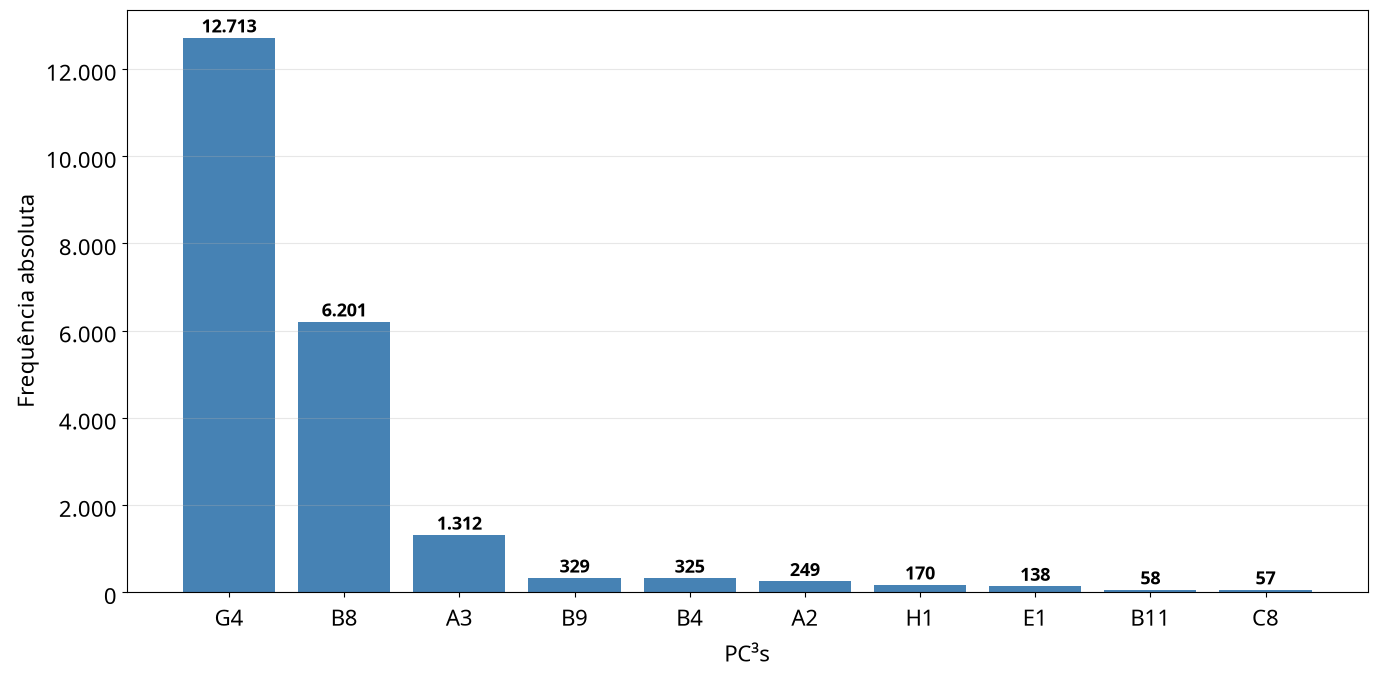


📊 Gerando gráfico de misconception por questão...
⚠️ Coluna 'misconception' não encontrada no dataset.

🔥 Gerando mapa de calor de correlações entre PC³s...


Figura vetorial salva: /tmp/execucao/execucao/extracted/QuestionInsight/Etapa_5/output/resultados/figuras/4_PC3/correlacao_pc3.pdf


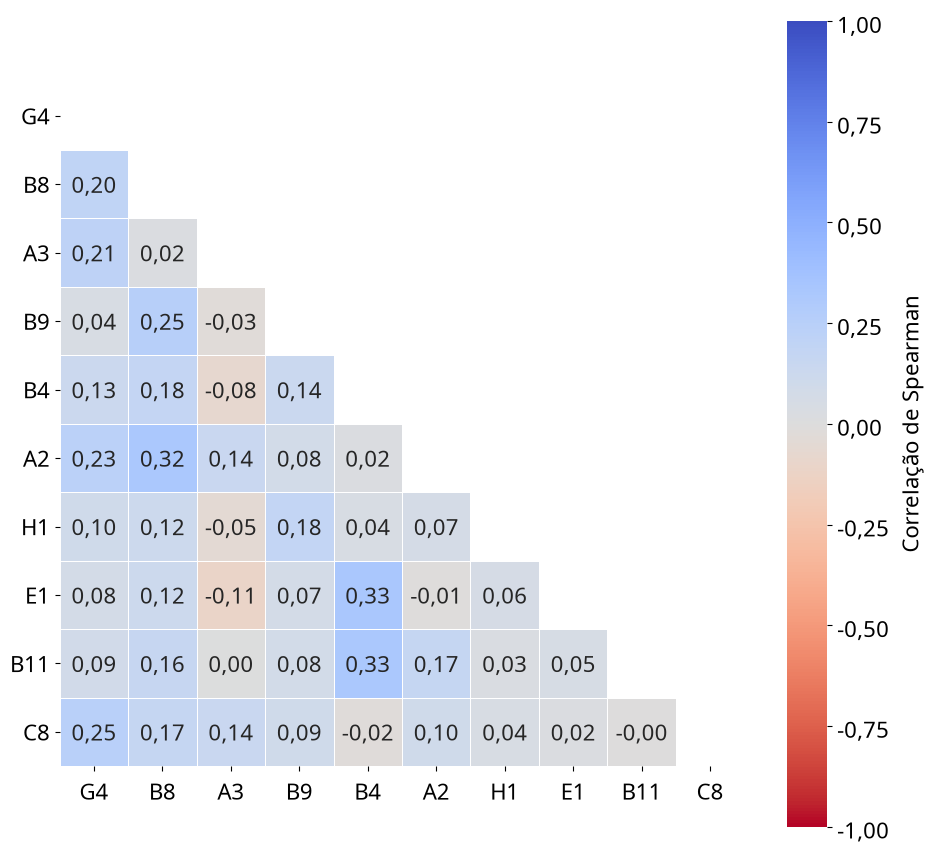


✓ Matriz de correlação gerada com sucesso!


,G4,B8,A3,B9,B4,A2,H1,E1,B11,C8
G4,1.000000,0.196673,0.213137,0.039876,0.125360,0.227800,0.101032,0.077244,0.092395,0.249688
B8,0.196673,1.000000,0.017545,0.251023,0.176568,0.322296,0.118554,0.122472,0.163783,0.168239
A3,0.213137,0.017545,1.000000,-0.029732,-0.075756,0.143486,-0.048564,-0.113345,0.004133,0.140896
B9,0.039876,0.251023,-0.029732,1.000000,0.136259,0.082803,0.179937,0.073566,0.084165,0.094687
B4,0.125360,0.176568,-0.075756,0.136259,1.000000,0.022143,0.040694,0.329332,0.325674,-0.016305
A2,0.227800,0.322296,0.143486,0.082803,0.022143,1.000000,0.069500,-0.014538,0.165167,0.099504
H1,0.101032,0.118554,-0.048564,0.179937,0.040694,0.069500,1.000000,0.060115,0.025977,0.041922
E1,0.077244,0.122472,-0.113345,0.073566,0.329332,-0.014538,0.060115,1.000000,0.052056,0.015641
B11,0.092395,0.163783,0.004133,0.084165,0.325674,0.165167,0.025977,0.052056,1.000000,-0.004635
C8,0.249688,0.168239,0.140896,0.094687,-0.016305,0.099504,0.041922,0.015641,-0.004635,1.000000


In [3]:
from pathlib import Path
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


def salvar_figura_pdf(fig, nome_arquivo):
    """Salva uma figura no formato PDF vetorial sem rasterizar o desenho."""
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    destino = FIGURES_DIR / nome_arquivo
    destino.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(destino, format="pdf", bbox_inches="tight", pad_inches=0.15)
    print(f"Figura vetorial salva: {destino}")
    return destino



import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
import numpy as np
import locale

# Configurar locale para formatação brasileira
try:
    locale.setlocale(locale.LC_ALL, 'pt_BR.UTF-8')
except:
    pass

# --- CONFIGURAÇÕES GERAIS ---

# Configurações de fonte global
plt.rcParams['font.size'] = 14
plt.rcParams['axes.titlesize'] = 18
plt.rcParams['axes.labelsize'] = 16
plt.rcParams['xtick.labelsize'] = 16
plt.rcParams['ytick.labelsize'] = 16

# Mapeamento de Colunas para Nomes Legíveis

# Lista base (será filtrada dinamicamente)

def formatar_numero(valor):
    """Formata número com separador de milhares (.) e decimais com vírgula"""
    if valor >= 1000:
        return f"{int(valor):,}".replace(',', '.')
    return str(int(valor))

def formatar_decimal(valor):
    """Formata decimal com vírgula"""
    return f"{valor:.2f}".replace('.', ',')

def carregar_dados():
    """Carrega os dados do CSV e trata colunas inexistentes"""
    try:
        df = pd.read_csv(QUESTIONS_PATH)
        # Garante que todas as colunas de interesse existam no DF (preenche com 0 se faltar)
        for col in PC3_COLUNAS_BASE:
            if col not in df.columns:
                df[col] = 0
        return df
    except FileNotFoundError:
        print(f"❌ Erro: Arquivo '{QUESTIONS_PATH}' não encontrado.")
        return None

def obter_colunas_ordenadas(df, top_n=TOP_N_PC3):
    """
    1. Calcula a frequência total.
    2. Remove colunas zeradas (ex: A4, H1).
    3. Ordena do mais frequente para o menos frequente.
    4. Retorna a lista de colunas cortada pelo top_n.
    """
    totais = {}
    
    # Calcula totais
    for col in PC3_COLUNAS_BASE:
        soma = df[col].sum()
        totais[col] = soma

    # Filtra quem tem 0 ocorrências (Remove A4 e H1 automaticamente se estiverem vazios)
    totais_ativos = {k: v for k, v in totais.items() if v >= PC3_MIN_OCCURRENCES}
    
    # Identifica quem foi removido
    removidos = set(PC3_COLUNAS_BASE) - set(totais_ativos.keys())
    if removidos:
        nomes_removidos = [PC3_MAP[c] for c in removidos]
        print(f"⚠️ PC³s vazios removidos da análise de correlação: {', '.join(nomes_removidos)}")

    # Ordena dicionário por valor (decrescente)
    ordenados = sorted(totais_ativos.items(), key=lambda x: x[1], reverse=True)
    
    # Pega apenas as chaves (nomes das colunas)
    colunas_ordenadas = [item[0] for item in ordenados]
    
    # Aplica o corte top_n se solicitado
    if top_n and top_n < len(colunas_ordenadas):
        print(f"ℹ️ Selecionando os Top {top_n} PC³s mais frequentes.")
        colunas_ordenadas = colunas_ordenadas[:top_n]
    else:
        print(f"ℹ️ Analisando todos os {len(colunas_ordenadas)} PC³s com ocorrências.")
        
    return colunas_ordenadas, totais

def plotar_frequencia(totais, colunas_ordenadas):
    """Plota gráfico de barras seguindo a ordem definida"""
    
    nomes = [PC3_MAP[col] for col in colunas_ordenadas]
    valores = [totais[col] for col in colunas_ordenadas]
    
    fig, ax = plt.subplots(figsize=(14, 7))
    bars = ax.bar(nomes, valores, color='steelblue')
    
    # Adiciona valores no topo com formatação brasileira
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                formatar_numero(height),
                ha='center', va='bottom', fontsize=13, fontweight='bold')
    
    ax.set_xlabel('PC³s', fontsize=16)
    ax.set_ylabel('Frequência absoluta', fontsize=16)
    #ax.set_title('PC³s mais frequentes', fontsize=18, fontweight='bold')
    plt.xticks(rotation=0, ha='center')  # Nomes retos e centralizados
    
    # Formata eixo Y com separador de milhares
    from matplotlib.ticker import FuncFormatter
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, p: formatar_numero(x)))
    
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    salvar_figura_pdf(plt.gcf(), "frequencia_pc3.pdf")
    plt.show()

def plotar_misconception(df, colunas_ordenadas):
    """Plota gráfico de misconception por questão (em azul)"""
    
    # Verifica se a coluna 'misconception' existe
    if 'misconception' not in df.columns:
        print("⚠️ Coluna 'misconception' não encontrada no dataset.")
        return
    
    # Agrupa por questão e soma misconceptions
    if 'questao' in df.columns:
        misc_por_questao = df.groupby('questao')['misconception'].sum().sort_values(ascending=False)
    elif 'id' in df.columns:
        misc_por_questao = df.groupby('id')['misconception'].sum().sort_values(ascending=False)
    else:
        print("⚠️ Coluna 'questao' ou 'id' não encontrada.")
        return
    
    # Limita aos top 15 para melhor visualização
    top_questoes = misc_por_questao.head(15)
    
    fig, ax = plt.subplots(figsize=(14, 7))
    bars = ax.bar(range(len(top_questoes)), top_questoes.values, color='steelblue')
    
    # Adiciona valores no topo
    for i, (bar, val) in enumerate(zip(bars, top_questoes.values)):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                formatar_numero(val),
                ha='center', va='bottom', fontsize=13, fontweight='bold')
    
    ax.set_xlabel('questão', fontsize=16)
    ax.set_ylabel('frequência de misconception', fontsize=16)
    ax.set_title('misconception por questão', fontsize=18, fontweight='bold')
    ax.set_xticks(range(len(top_questoes)))
    plt.xticks(range(len(top_questoes)), top_questoes.index, rotation=0, ha='center')
    
    # Formata eixo Y com separador de milhares
    from matplotlib.ticker import FuncFormatter
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, p: formatar_numero(x)))
    
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    salvar_figura_pdf(plt.gcf(), "misconception_por_questao.pdf")
    plt.show()

def calcular_e_plotar_correlacao(df, colunas_ordenadas):
    """
    Calcula correlação apenas para as colunas selecionadas e ordenadas.
    """
    # Filtra apenas questões relevantes (respostas >= 16, se coluna existir)
    if 'respostas' in df.columns:
        df_corr = df[df['respostas'] >= MIN_QUESTAO_RESPOSTAS].copy()
    else:
        df_corr = df.copy()

    # Seleciona subconjunto de dados JÁ ORDENADO por frequência
    df_subset = df_corr[colunas_ordenadas]
    
    # Renomeia para nomes curtos (C1, B4...) para o gráfico ficar bonito
    df_subset.columns = [PC3_MAP[col] for col in colunas_ordenadas]
    
    # Calcula Spearman
    corr_df = df_subset.corr(method='spearman')
    
    # Plotagem com fonte maior
    fig, ax = plt.subplots(figsize=(9.6645, 8.7782))
    
    # Máscara para triângulo superior
    mask = np.triu(np.ones_like(corr_df, dtype=bool))
    
    # Cria anotações formatadas com vírgula
    annot_data = corr_df.map(lambda x: formatar_decimal(x))
    
    # MUDANÇA: inverte o colormap - agora azul é positivo e vermelho é negativo
    heatmap = sns.heatmap(
        corr_df,
        mask=mask,
        annot=annot_data,
        fmt='',
        cmap='coolwarm_r',  # INVERTIDO: adiciona _r para reverter as cores
        center=0,
        vmin=-1,
        vmax=1,
        square=True,
        linewidths=0.5,
        cbar_kws={'label': 'Correlação de Spearman'},
        ax=ax,
        annot_kws={'fontsize': 16}
    )
    
    # Formata a barra de cores com vírgula nos decimais
    from matplotlib.ticker import FuncFormatter
    colorbar = heatmap.collections[0].colorbar
    colorbar.ax.yaxis.set_major_formatter(FuncFormatter(lambda x, p: formatar_decimal(x)))
    
    #ax.set_title('matriz de correlação de PC³s (ordenada por frequência)',              fontsize=18, fontweight='bold', pad=20)
    
    # Ajusta labels para ficarem retos e centralizados
    plt.xticks(rotation=0, ha='center')
    plt.yticks(rotation=0, va='center')
    
    plt.tight_layout()
    salvar_figura_pdf(plt.gcf(), "4_PC3/correlacao_pc3.pdf")
    plt.show()
    
    return corr_df

def gerar_relatorio(top_n=TOP_N_PC3):
    """
    Função Principal de Controle.
    
    Parâmetros:
      top_n (int ou None): Número de PC³s a analisar. 
                           Ex: 10 para os top 10, None para todos.
    """
    print("=" * 60)
    print("INICIANDO ANÁLISE DE PC³s")
    print("=" * 60)
    
    df = carregar_dados()
    if df is None: return

    # 1. Processamento e Ordenação
    colunas_finais, totais_brutos = obter_colunas_ordenadas(df, top_n=top_n)
    
    if not colunas_finais:
        print("Nenhum dado encontrado para gerar relatórios.")
        return

    # 2. Plotar Frequências de PC³s (Barras)
    print("\n📊 Gerando gráfico de frequências de PC³s...")
    plotar_frequencia(totais_brutos, colunas_finais)
    
    # 3. Plotar Misconception por Questão (Barras Azuis)
    print("\n📊 Gerando gráfico de misconception por questão...")
    plotar_misconception(df, colunas_finais)
    
    # 4. Correlação (Heatmap)
    print("\n🔥 Gerando mapa de calor de correlações entre PC³s...")
    corr_df = calcular_e_plotar_correlacao(df, colunas_finais)
    
    # 5. Exibir informação
    print("\n✓ Matriz de correlação gerada com sucesso!")
    print("=" * 60)
    
    return corr_df


# VERSÃO NOTEBOOK - Chama a função diretamente
gerar_relatorio(top_n=TOP_N_PC3)  # top_n para a quantidade de PC³s a analisar

## 3. Frequência e distribuição dos misconceptions MC³

Esta seção usa `misconceptions_detalhado_por_usuario.csv` para contar os PC³ detectados e calcular sua prevalência. A unidade de análise é o par estudante–questão, portanto um mesmo estudante pode contribuir com várias observações.

Os PC³ considerados são definidos pelo catálogo global e pelos filtros configurados na seção 1. A célula produz tabelas e figuras vetoriais em `output/resultados/figuras/`. Frequência é uma medida de ocorrência; ela não deve ser interpretada isoladamente como dificuldade ou como efeito causal.

ANÁLISE DAS MÉTRICAS DE DIFICULDADE

1. Carregando dados...
   Total de questões no arquivo: 617

2. Métricas de dificuldade identificadas: 13
   MD1: taxa_acerto → taxa de acerto
   MD2: num_submissoes → submissões
   MD3: taxa_aceitacao → taxa de aceitação
   MD4: num_testes → testes
   MD5: num_consultas → consultas
   MD6: num_erros_lgcs → erros lógicos
   MD7: num_errors_stx → erros sintaxe
   MD8: num_erros → erros totais
   MD9: num_eventos → eventos totais
   MD10: num_eventos_del → eventos deleção
   MD11: tempo_implementacao → tempo implementação
   MD12: qtd_alteracoes_codigo → alterações código
   MD13: discriminacao → discriminação

3. Filtrando questões com 16 ou mais respostas...
   Questões com 16+ respostas: 617
   Questões excluídas: 0

4. Calculando estatísticas descritivas...

TABELA: Medidas de tendência central e dispersão das métricas de dificuldade
Questões com 16 ou mais respostas
            Métrica   n Média Desvio-padrão   Min Mediana   Max
     taxa de acer

Figura vetorial salva: /tmp/execucao/execucao/extracted/QuestionInsight/Etapa_5/output/resultados/figuras/metricas_dificuldade_padrao.pdf


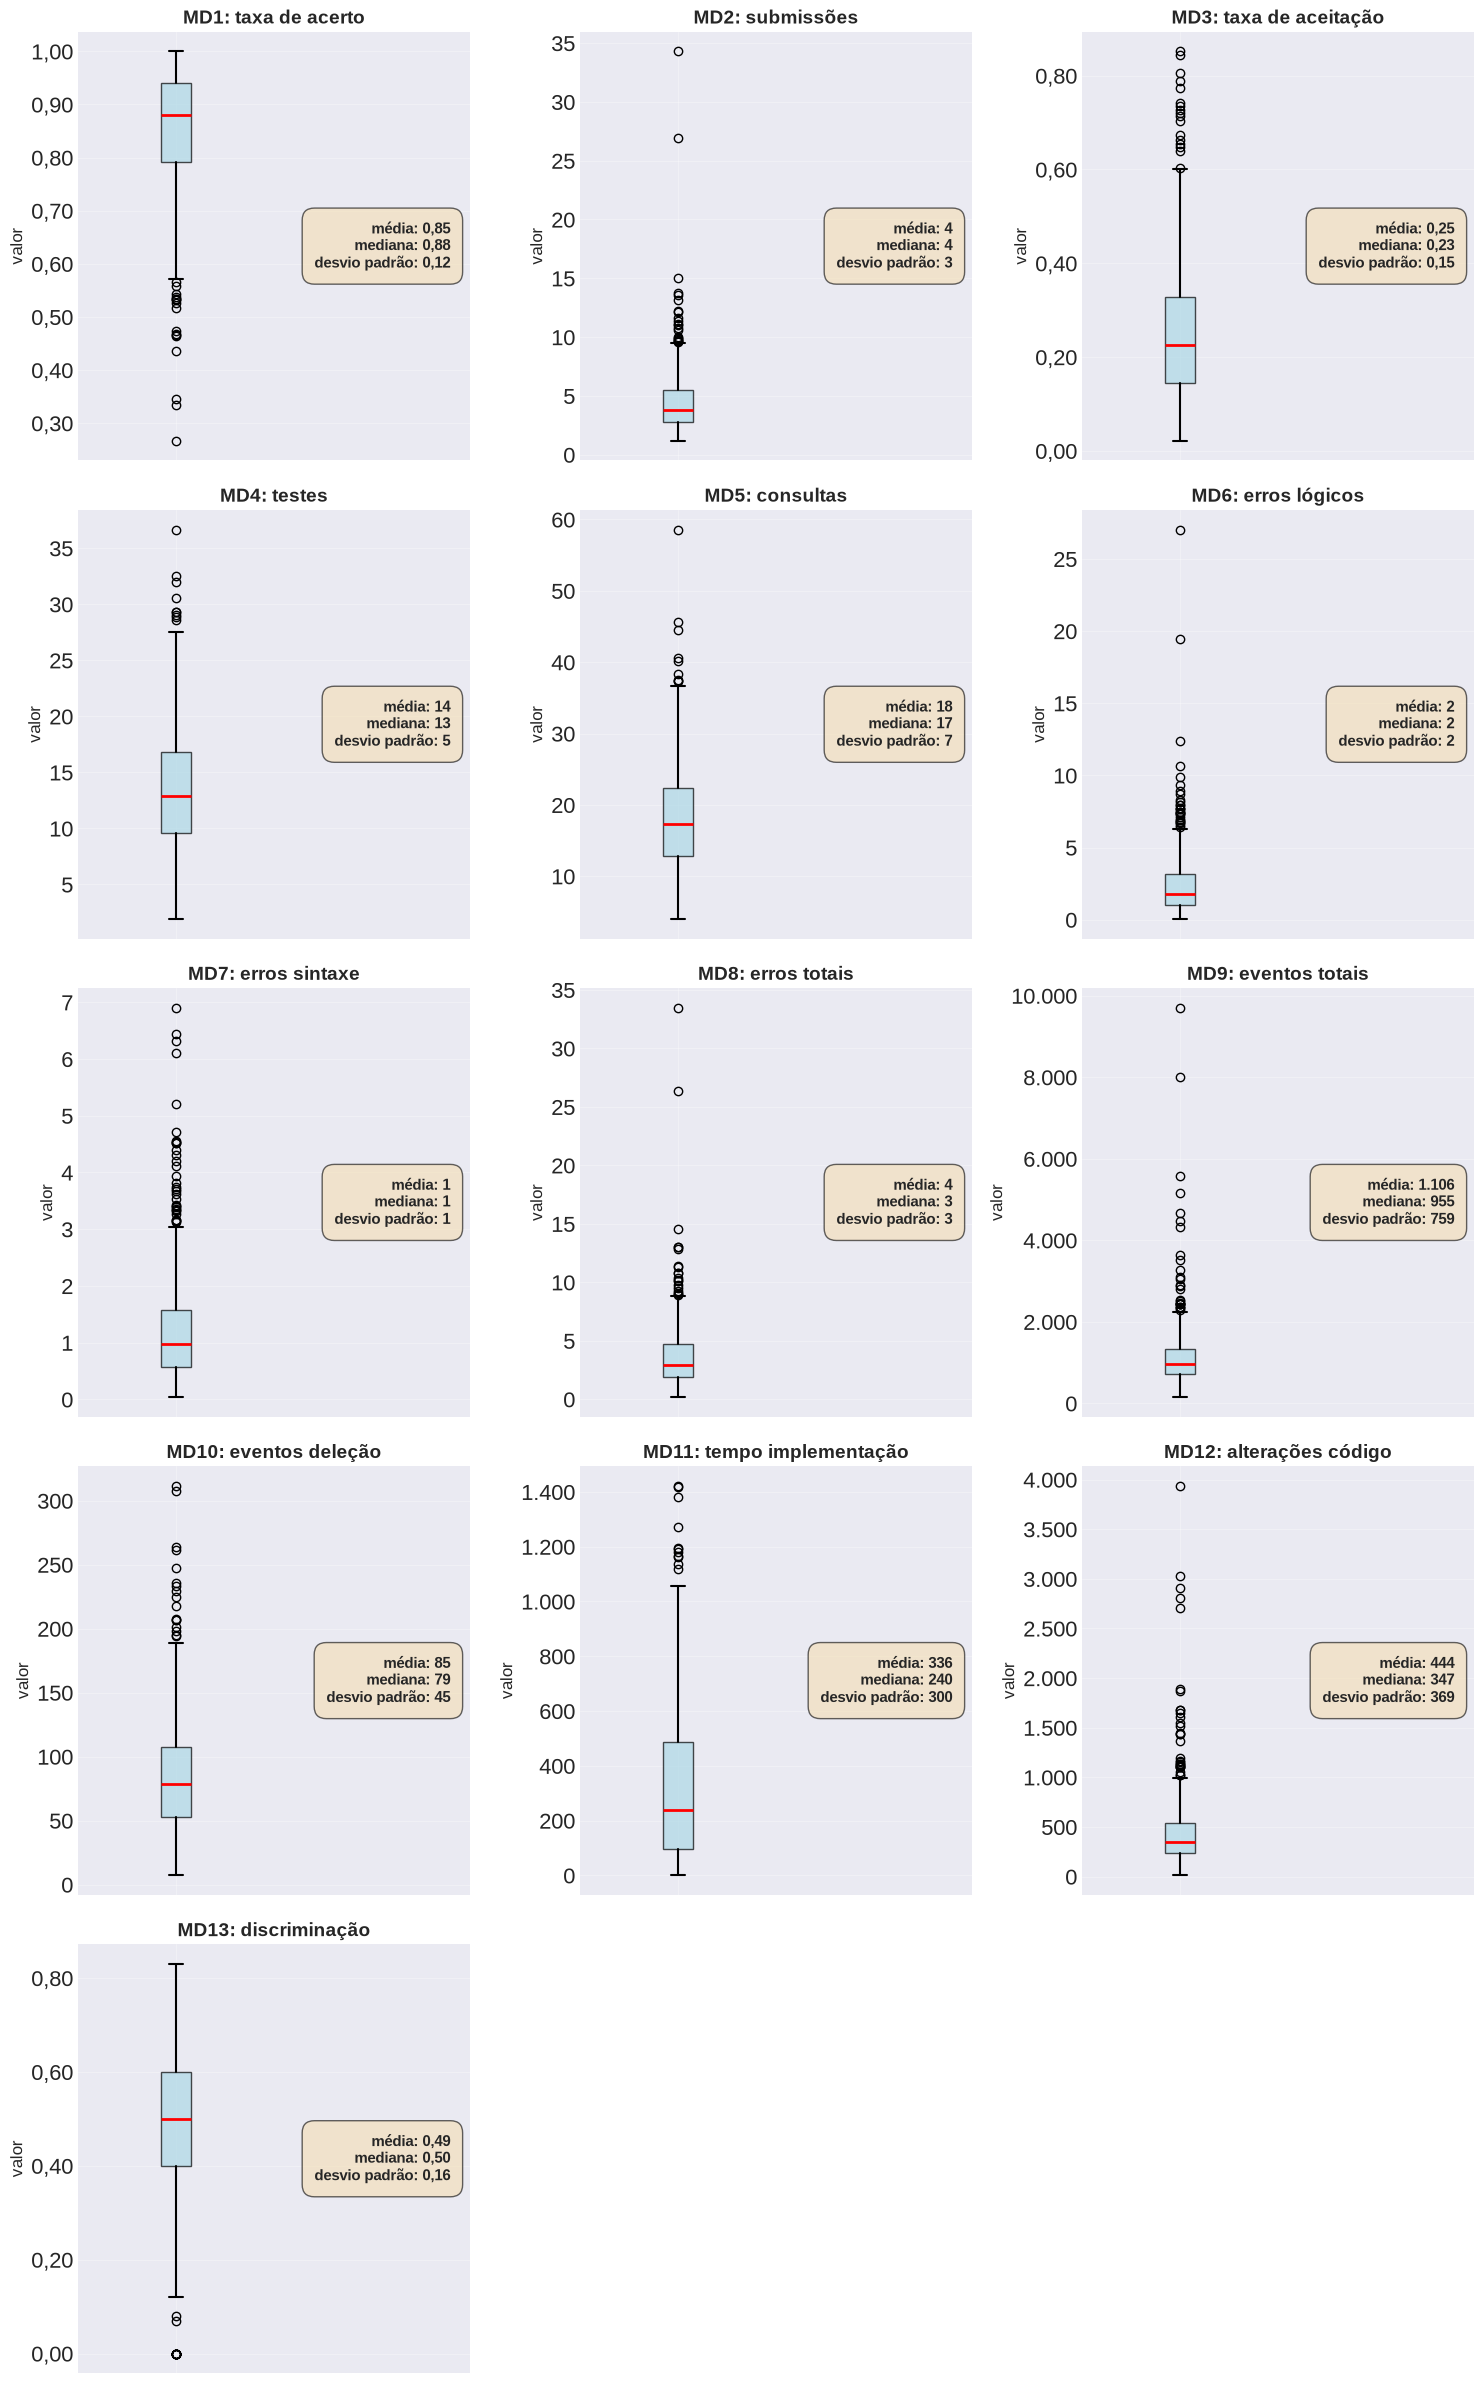

✓ Boxplots com dados originais exibidos

5b. Gerando boxplots com z-score (dados normalizados, mesma escala)...
   Escala global do eixo Y: [-5,60, 12,14]


Figura vetorial salva: /tmp/execucao/execucao/extracted/QuestionInsight/Etapa_5/output/resultados/figuras/metricas_dificuldade_zscore.pdf


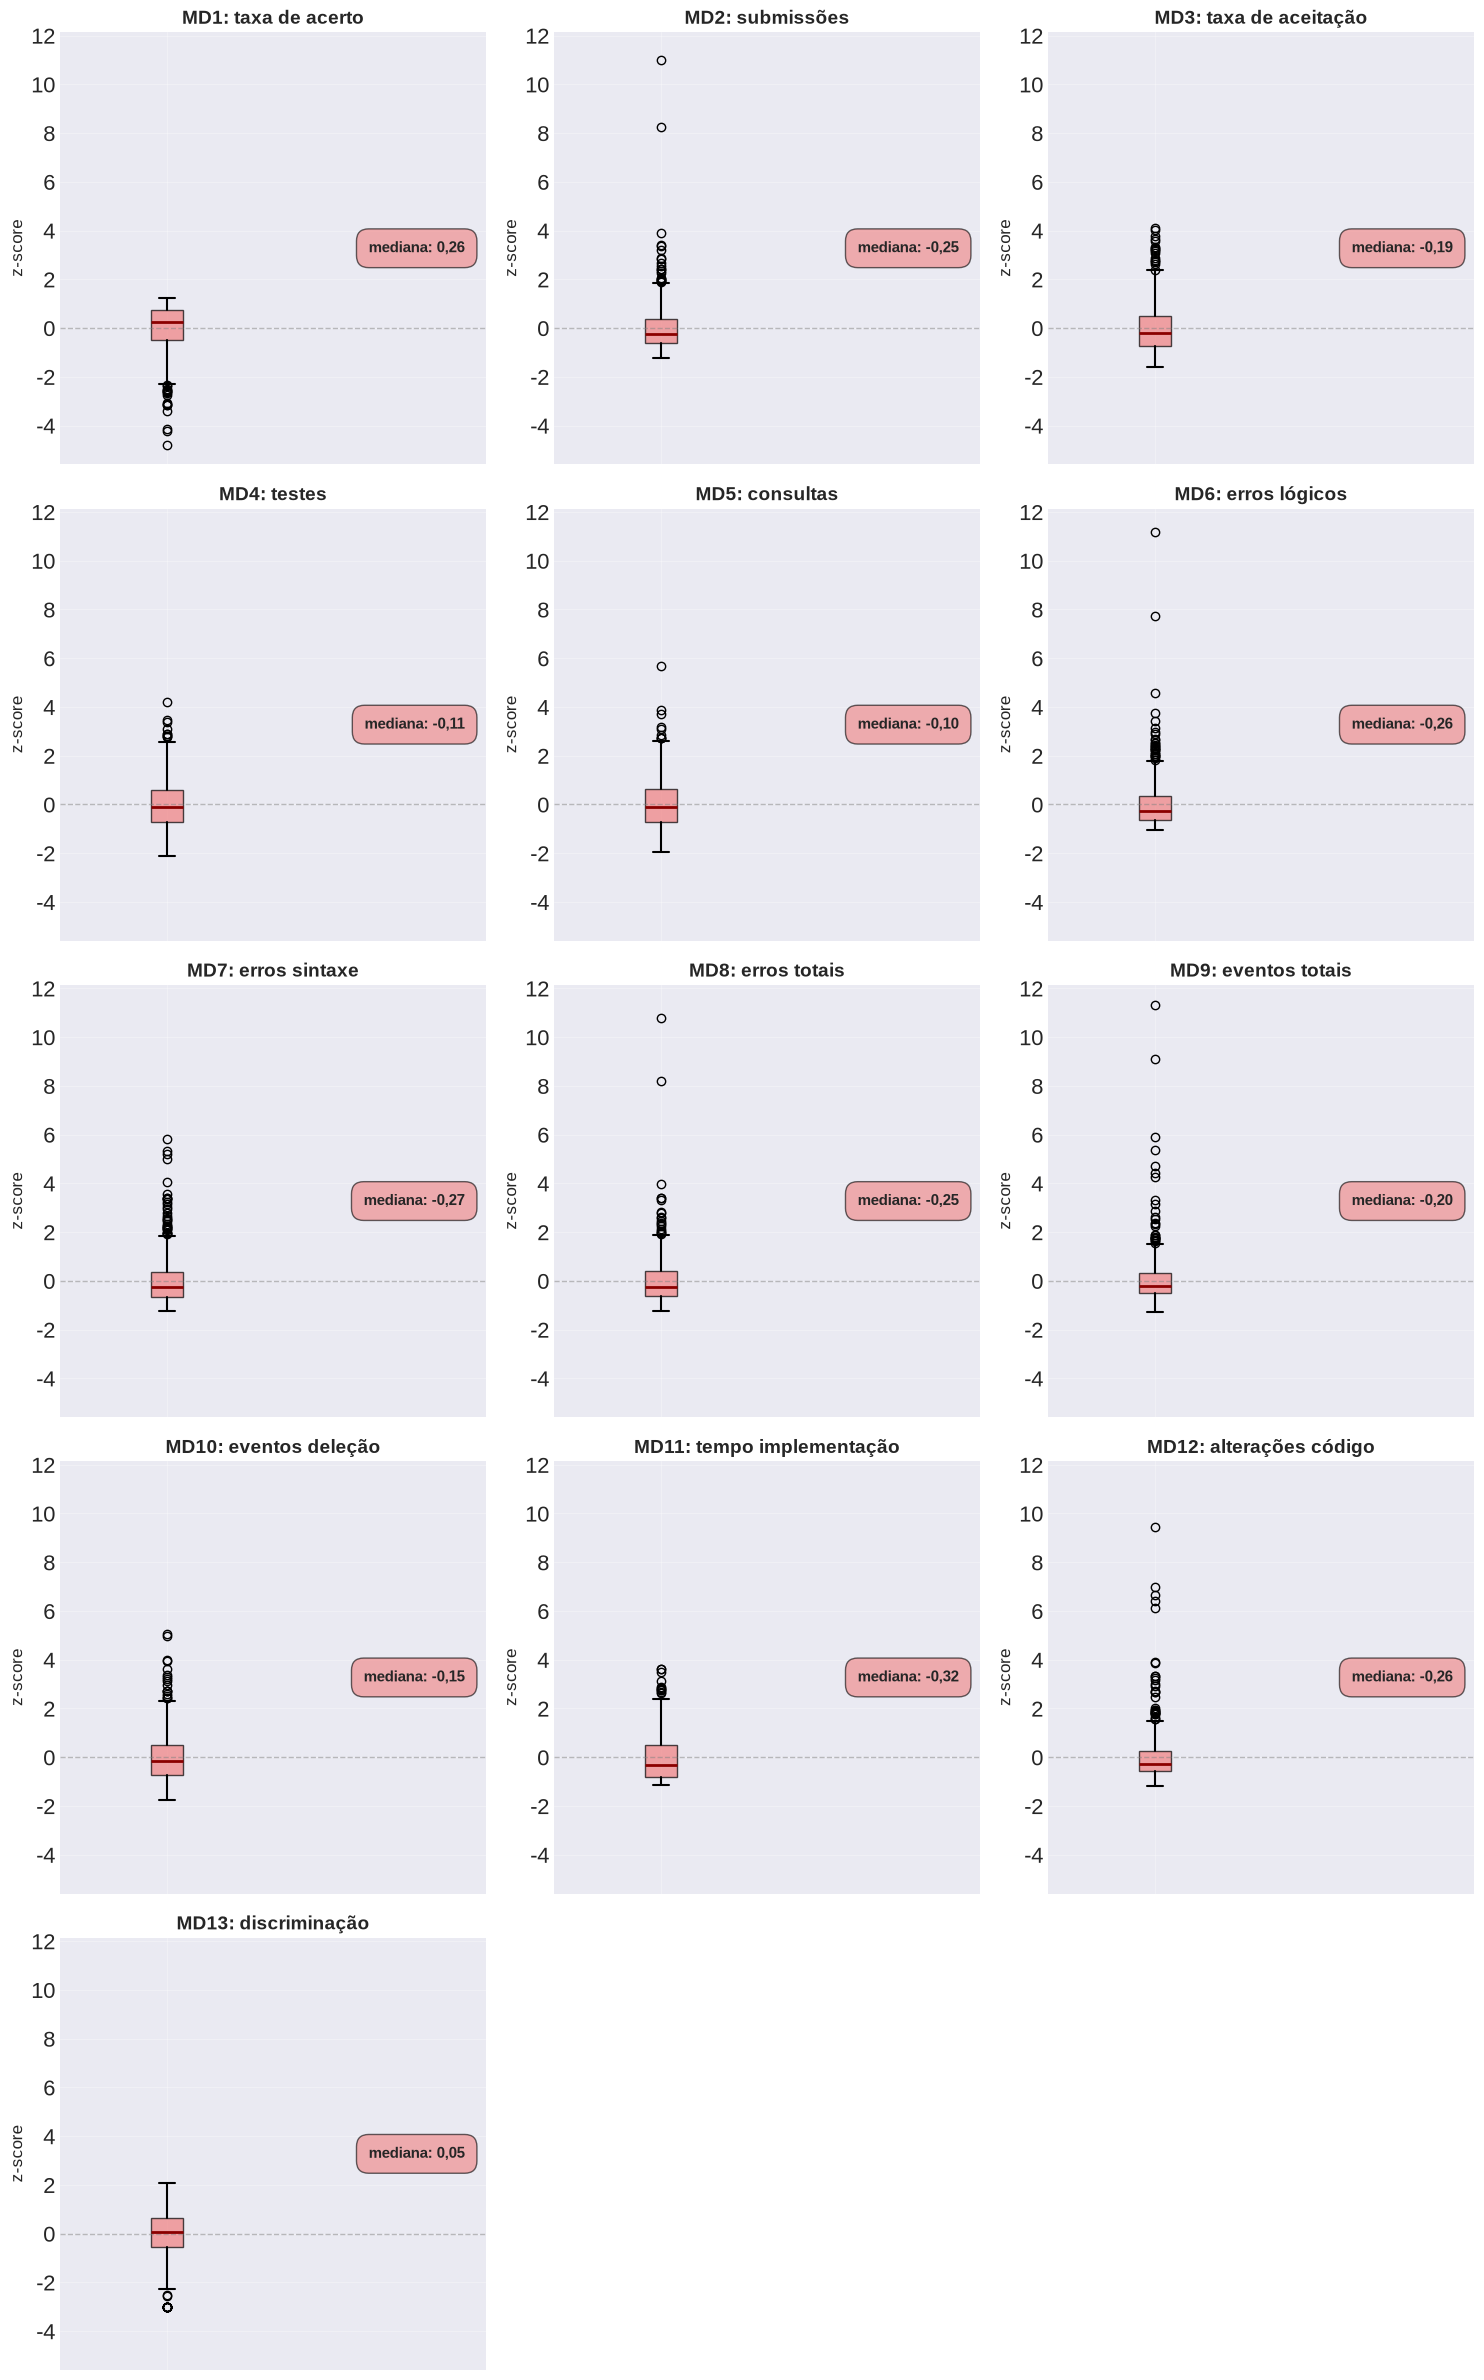

✓ Boxplots com z-score exibidos (escala unificada)

6. Calculando correlação de Spearman entre métricas...

MATRIZ DE CORRELAÇÃO DE SPEARMAN (forma de escada - TEXTO)

Métrica                    taxa de acer    submissões  taxa de acei        testes     consultas  erros lógico  erros sintax  erros totais  eventos tota  eventos dele  tempo implem  alterações c  discriminaçã
---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
taxa de acerto                     1,00                                                                                                                                                                        
submissões                        -0,56          1,00                                                                                                                                                          


Figura vetorial salva: /tmp/execucao/execucao/extracted/QuestionInsight/Etapa_5/output/resultados/figuras/correlacao_metricas_dificuldade.pdf


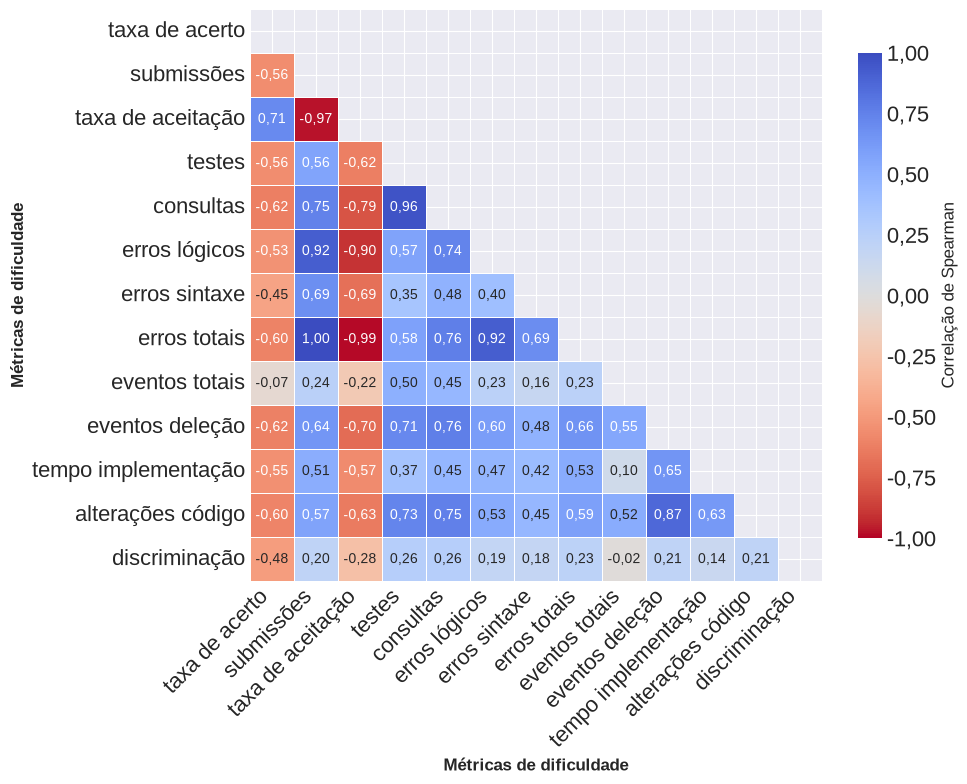

✓ Heatmap exibido

8. Análise de correlações fortes...

PARES DE MÉTRICAS COM CORRELAÇÃO FORTE (|ρ| > 0,7)
        Métrica 1         Métrica 2     ρ
taxa de aceitação    taxa de acerto  0,71
taxa de aceitação        submissões -0,97
        consultas        submissões  0,75
        consultas taxa de aceitação -0,79
        consultas            testes  0,96
    erros lógicos        submissões  0,92
    erros lógicos taxa de aceitação -0,90
    erros lógicos         consultas  0,74
     erros totais        submissões  1,00
     erros totais taxa de aceitação -0,99
     erros totais         consultas  0,76
     erros totais     erros lógicos  0,92
  eventos deleção            testes  0,71
  eventos deleção         consultas  0,76
alterações código            testes  0,73
alterações código         consultas  0,75
alterações código   eventos deleção  0,87

PARES DE MÉTRICAS COM CORRELAÇÃO MODERADA (0,5 < |ρ| ≤ 0,7)
          Métrica 1           Métrica 2     ρ
         submissões      taxa 

In [4]:
from pathlib import Path
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# Configurações

# Configurações de fonte global
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

# Mapeamento de Colunas para Nomes Legíveis

# ============================================================================
# MAPEAMENTO DAS MÉTRICAS DE DIFICULDADE
# Colunas reais do CSV → nomes legíveis
# 'dificuldade' é ignorada conforme instrução
# ============================================================================
# M1:  taxa_acerto           = num_correct / num_students_interactions
# M2:  num_submissoes        = num_submissions / num_students_interactions
# M3:  taxa_aceitacao        = num_correct / num_submissions
# M4:  num_testes            = num_tests / num_students_interactions
# M5:  num_consultas         = (num_submissions + num_tests) / num_students_interactions
# M6:  num_erros_lgcs        = num_logic_errors / num_students_interactions
# M7:  num_errors_stx        = num_syntax_errors / num_students_interactions
# M8:  num_erros             = num_errors / num_students_interactions
# M9:  num_eventos           = num_events / num_students_interactions
# M10: num_eventos_del       = num_deletes / num_students_interactions
# M11: tempo_implementacao   = code_time / num_correct
# M12: qtd_alteracoes_codigo = amount_of_change / num_students_interactions
# M13: discriminacao         (fórmula própria - já calculada)


# Métricas onde valores menores = questão mais difícil (positivas invertidas)
# Usadas apenas para referência semântica

# Métricas com casas decimais (as demais são exibidas como inteiros)

def formatar_numero(valor):
    """Formata número com separador de milhares (.) e sem decimais"""
    if pd.isna(valor):
        return 'N/A'
    try:
        v = float(valor)
        if v >= 1000 or v <= -1000:
            return f"{int(round(v)):,}".replace(',', '.')
        return str(int(round(v)))
    except:
        return 'N/A'

def formatar_decimal(valor, casas=3):
    """Formata decimal com vírgula como separador"""
    if pd.isna(valor):
        return 'N/A'
    try:
        formato = f"{{:.{casas}f}}"
        return formato.format(float(valor)).replace('.', ',')
    except:
        return 'N/A'

def formatar_metrica(valor, nome_coluna, casas=2):
    """Formata valor de acordo com o tipo da métrica"""
    if pd.isna(valor):
        return 'N/A'
    if nome_coluna in METRICAS_DECIMAIS:
        return formatar_decimal(valor, casas)
    else:
        return formatar_numero(valor)

# Configuração de estilo para gráficos
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("=" * 80)
print("ANÁLISE DAS MÉTRICAS DE DIFICULDADE")
print("=" * 80)

# 1. CARREGAR DADOS
print("\n1. Carregando dados...")
df = pd.read_csv(QUESTIONS_PATH)
print(f"   Total de questões no arquivo: {formatar_numero(len(df))}")

# 2. IDENTIFICAR MÉTRICAS DE DIFICULDADE DISPONÍVEIS NO CSV
# Apenas as colunas que existem no arquivo E estão no dicionário de tradução
difficulty_metrics = [col for col in traducao_metricas.keys() if col in df.columns]

print(f"\n2. Métricas de dificuldade identificadas: {len(difficulty_metrics)}")
for i, metric in enumerate(difficulty_metrics, 1):
    print(f"   MD{i}: {metric} → {traducao_metricas[metric]}")

# 3. FILTRAR QUESTÕES COM 16+ RESPOSTAS
print("\n3. Filtrando questões com 16 ou mais respostas...")
if 'respostas' not in df.columns:
    raise ValueError("A base precisa conter a coluna 'respostas' para aplicar o filtro mínimo de respostas.")
df['respostas'] = pd.to_numeric(df['respostas'], errors='coerce')
df_filtered = df[df['respostas'] >= MIN_QUESTAO_RESPOSTAS].copy()
pc3_columns = [col for col in list(PC3_MAP.keys()) if col in df.columns]
print(f"   Questões com 16+ respostas: {formatar_numero(len(df_filtered))}")
print(f"   Questões excluídas: {formatar_numero(len(df) - len(df_filtered))}")

# Converter métricas para numérico
for metric in difficulty_metrics:
    df_filtered[metric] = pd.to_numeric(df_filtered[metric], errors='coerce')

# 4. CALCULAR ESTATÍSTICAS DESCRITIVAS
print("\n4. Calculando estatísticas descritivas...")
print("\n" + "=" * 80)
print("TABELA: Medidas de tendência central e dispersão das métricas de dificuldade")
print("Questões com 16 ou mais respostas")
print("=" * 80)

stats_list = []
valid_metrics = []

for metric in difficulty_metrics:
    values = df_filtered[metric].dropna()
    if len(values) > 0:
        stats = {
            'Métrica': traducao_metricas.get(metric, metric),
            'n': formatar_numero(len(values)),
            'Média': formatar_metrica(values.mean(), metric, casas=3),
            'Desvio-padrão': formatar_metrica(values.std(), metric, casas=3),
            'Min': formatar_metrica(values.min(), metric, casas=3),
            'Mediana': formatar_metrica(values.median(), metric, casas=3),
            'Max': formatar_metrica(values.max(), metric, casas=3),
        }
        stats_list.append(stats)
        valid_metrics.append(metric)
    else:
        print(f"   ⚠️  Métrica '{metric}' sem valores válidos. Ignorando.")

stats_df = pd.DataFrame(stats_list)
print(stats_df.to_string(index=False))

difficulty_metrics = valid_metrics

# 5. PLOTAR BOXPLOTS - DADOS ORIGINAIS
print("\n5. Gerando boxplots com dados originais...")

n_metrics = len(difficulty_metrics)
n_cols = 3
n_rows = int(np.ceil(n_metrics / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4.8 * n_rows))
plt.subplots_adjust(top=0.92, hspace=0.6, bottom=0.08)

if n_rows == 1:
    axes = axes.reshape(1, -1)
axes_flat = axes.flatten()

for idx, metric in enumerate(difficulty_metrics):
    ax = axes_flat[idx]
    data = df_filtered[metric].dropna()

    # Vertical é a orientação padrão e compatível com versões antigas do Matplotlib.
    bp = ax.boxplot([data], patch_artist=True,
                    boxprops=dict(facecolor='lightblue', alpha=0.7),
                    medianprops=dict(color='red', linewidth=2),
                    whiskerprops=dict(linewidth=1.5),
                    capprops=dict(linewidth=1.5))

    ax.set_xlim(0.5, 2.5)
    ax.set_title(f'MD{idx+1}: {traducao_metricas.get(metric, metric)}', fontweight='bold')
    ax.set_ylabel('valor')
    ax.set_xticklabels([''])
    ax.grid(True, alpha=0.3)

    # Formatar eixo Y de acordo com o tipo da métrica
    if metric in METRICAS_DECIMAIS:
        ax.yaxis.set_major_formatter(FuncFormatter(lambda x, p: formatar_decimal(x, 2)))
    else:
        ax.yaxis.set_major_formatter(FuncFormatter(lambda x, p: formatar_numero(x)))

    # Texto com estatísticas
    media_fmt   = formatar_metrica(data.mean(),   metric, casas=2)
    mediana_fmt = formatar_metrica(data.median(), metric, casas=2)
    std_fmt     = formatar_metrica(data.std(),    metric, casas=2)
    stats_text = f'média: {media_fmt}\nmediana: {mediana_fmt}\ndesvio padrão: {std_fmt}'

    ax.text(0.95, 0.5, stats_text, transform=ax.transAxes,
            verticalalignment='center', horizontalalignment='right',
            bbox=dict(boxstyle='round,pad=0.8', facecolor='wheat', alpha=0.6),
            fontsize=11, fontweight='bold')

for idx in range(n_metrics, len(axes_flat)):
    fig.delaxes(axes_flat[idx])

plt.tight_layout()
salvar_figura_pdf(fig, "metricas_dificuldade_padrao.pdf")
plt.show()
print("✓ Boxplots com dados originais exibidos")

# 5b. PLOTAR BOXPLOTS - Z-SCORE (MESMA ESCALA NO EIXO Y)
print("\n5b. Gerando boxplots com z-score (dados normalizados, mesma escala)...")

# Calcular todos os z-scores primeiro para determinar escala global
all_zscores = []
zscores_por_metrica = {}
for metric in difficulty_metrics:
    data = df_filtered[metric].dropna()
    std = data.std()
    z = (data - data.mean()) / std if std != 0 else data * 0
    zscores_por_metrica[metric] = z
    all_zscores.append(z)

# Determinar min e max globais com margem de 5%
z_global_min = min(z.min() for z in all_zscores)
z_global_max = max(z.max() for z in all_zscores)
margem = (z_global_max - z_global_min) * 0.05
y_min = z_global_min - margem
y_max = z_global_max + margem

print(f"   Escala global do eixo Y: [{formatar_decimal(y_min, 2)}, {formatar_decimal(y_max, 2)}]")

fig2, axes2 = plt.subplots(n_rows, n_cols, figsize=(15, 4.8 * n_rows))
plt.subplots_adjust(top=0.92, hspace=0.6, bottom=0.08)

if n_rows == 1:
    axes2 = axes2.reshape(1, -1)
axes2_flat = axes2.flatten()

def format_zscore(x, p):
    return str(int(x)) if x == int(x) else formatar_decimal(x, 1)

for idx, metric in enumerate(difficulty_metrics):
    ax = axes2_flat[idx]
    z_score = zscores_por_metrica[metric]

    # Vertical é a orientação padrão; compatível com versões antigas do Matplotlib.
    bp = ax.boxplot([z_score], patch_artist=True,
                    boxprops=dict(facecolor='lightcoral', alpha=0.7),
                    medianprops=dict(color='darkred', linewidth=2),
                    whiskerprops=dict(linewidth=1.5),
                    capprops=dict(linewidth=1.5))

    ax.set_xlim(0.5, 2.5)
    ax.set_ylim(y_min, y_max)   # ← mesma escala em todos os subplots
    ax.set_title(f'MD{idx+1}: {traducao_metricas.get(metric, metric)}', fontweight='bold')
    ax.set_ylabel('z-score')
    ax.set_xticklabels([''])
    ax.grid(True, alpha=0.3)
    ax.yaxis.set_major_formatter(FuncFormatter(format_zscore))
    ax.axhline(y=0, color='gray', linestyle='--', linewidth=1, alpha=0.5)

    stats_text = f'mediana: {formatar_decimal(z_score.median(), 2)}'
    ax.text(0.95, 0.5, stats_text, transform=ax.transAxes,
            verticalalignment='center', horizontalalignment='right',
            bbox=dict(boxstyle='round,pad=0.8', facecolor='lightcoral', alpha=0.6),
            fontsize=11, fontweight='bold')

for idx in range(n_metrics, len(axes2_flat)):
    fig2.delaxes(axes2_flat[idx])

plt.tight_layout()
salvar_figura_pdf(fig2, "metricas_dificuldade_zscore.pdf")
plt.show()
print("✓ Boxplots com z-score exibidos (escala unificada)")

# 6. CORRELAÇÃO DE SPEARMAN
print("\n6. Calculando correlação de Spearman entre métricas...")

df_metrics = df_filtered[difficulty_metrics].copy()
corr_df = df_metrics.corr(method='spearman')
corr_matrix = corr_df.values
n_metrics = len(difficulty_metrics)
translated_metrics = [traducao_metricas.get(m, m) for m in difficulty_metrics]

# 7. MATRIZ EM ESCADA (TEXTO)
print("\n" + "=" * 80)
print("MATRIZ DE CORRELAÇÃO DE SPEARMAN (forma de escada - TEXTO)")
print("=" * 80)
print()

header = f"{'Métrica':<25}"
for metric in translated_metrics:
    header += f"{metric[:12]:>14}"
print(header)
print("-" * (25 + 14 * n_metrics))

for i, metric_i in enumerate(translated_metrics):
    line = f"{metric_i:<25}"
    for j in range(n_metrics):
        if j <= i:
            val = corr_matrix[i, j]
            line += f"{formatar_decimal(val, 2) if not np.isnan(val) else 'N/A':>14}"
        else:
            line += f"{'':>14}"
    print(line)

# 8. HEATMAP TRIANGULAR
print("\n7. Gerando heatmap da matriz de correlação...")

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
annot_data = corr_df.map(lambda x: formatar_decimal(x, 2))

fig, ax = plt.subplots(figsize=(9.91, 8.25))
heatmap = sns.heatmap(corr_df,
            mask=mask,
            annot=annot_data,
            fmt='',
            cmap='coolwarm_r',
            center=0,
            square=True,
            linewidths=0.5,
            cbar_kws={"shrink": 0.8, "label": "Correlação de Spearman"},
            xticklabels=translated_metrics,
            yticklabels=translated_metrics,
            vmin=-1, vmax=1,
            ax=ax,
            annot_kws={'fontsize': 10})

colorbar = heatmap.collections[0].colorbar
colorbar.ax.yaxis.set_major_formatter(FuncFormatter(lambda x, p: formatar_decimal(x, 2)))

ax.set_xlabel('Métricas de dificuldade', fontsize=12, fontweight='bold')
ax.set_ylabel('Métricas de dificuldade', fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
salvar_figura_pdf(plt.gcf(), "correlacao_metricas_dificuldade.pdf")
plt.show()
print("✓ Heatmap exibido")

# 9. CORRELAÇÕES FORTES
print("\n8. Análise de correlações fortes...")
print("\n" + "=" * 80)
print("PARES DE MÉTRICAS COM CORRELAÇÃO FORTE (|ρ| > 0,7)")
print("=" * 80)

strong_corr = []
for i in range(n_metrics):
    for j in range(i):
        val = corr_matrix[i, j]
        if not np.isnan(val) and abs(val) > 0.7:
            strong_corr.append({
                'Métrica 1': traducao_metricas.get(difficulty_metrics[i], difficulty_metrics[i]),
                'Métrica 2': traducao_metricas.get(difficulty_metrics[j], difficulty_metrics[j]),
                'ρ': formatar_decimal(val, 2),
            })

if strong_corr:
    print(pd.DataFrame(strong_corr).to_string(index=False))
else:
    print("Nenhuma correlação forte encontrada (|ρ| > 0,7)")

# 10. CORRELAÇÕES MODERADAS
print("\n" + "=" * 80)
print("PARES DE MÉTRICAS COM CORRELAÇÃO MODERADA (0,5 < |ρ| ≤ 0,7)")
print("=" * 80)

moderate_corr = []
for i in range(n_metrics):
    for j in range(i):
        val = corr_matrix[i, j]
        if not np.isnan(val) and 0.5 < abs(val) <= 0.7:
            moderate_corr.append({
                'Métrica 1': traducao_metricas.get(difficulty_metrics[i], difficulty_metrics[i]),
                'Métrica 2': traducao_metricas.get(difficulty_metrics[j], difficulty_metrics[j]),
                'ρ': formatar_decimal(val, 2),
            })

if moderate_corr:
    print(pd.DataFrame(moderate_corr).to_string(index=False))
else:
    print("Nenhuma correlação moderada encontrada")

# 11. RESUMO FINAL
print("\n" + "=" * 80)
print("RESUMO DA ANÁLISE")
print("=" * 80)
print(f"✓ Total de questões analisadas: {formatar_numero(len(df_filtered))}")
print(f"✓ Número de métricas de dificuldade válidas: {len(difficulty_metrics)}")
print(f"✓ Métricas analisadas:")
for i, metric in enumerate(difficulty_metrics, 1):
    print(f"   MD{i}: {metric} → {traducao_metricas[metric]}")
print(f"\n⚠️  Métrica 'dificuldade' ignorada conforme configuração.")
print("\n" + "=" * 80)
print("ANÁLISE CONCLUÍDA COM SUCESSO!")
print("=" * 80)

## 4. Métricas de dificuldade e correlação com PC³

Esta seção relaciona os misconceptions às métricas comportamentais da Etapa 4. São consideradas taxa de acerto, submissões, taxa de aceitação, testes, consultas, erros lógicos, erros de sintaxe, erros totais, eventos, deleções, tempo de implementação, alterações de código e discriminação.

As métricas são associadas às questões e comparadas com os indicadores dos PC³ selecionados pelos filtros globais. A coluna `dificuldade` não é usada como substituta dessas métricas comportamentais. As estatísticas só são calculadas quando há observações suficientes, e os resultados são salvos em `output/resultados/`.



💡 USO: analisar_correlacao_pc3_metricas(top_n=TOP_N_PC3)
   - top_n=10   : após o filtro, limita aos 10 mais frequentes
   - top_n=None : analisa todos os PC³ com o mínimo de ocorrências


ANÁLISE DE CORRELAÇÃO: PC³ vs MÉTRICAS DE DIFICULDADE

1. Carregando dados...
   Total de questões no arquivo: 617

2. Filtrando questões com 16+ respostas...
   Questões com 16+ respostas: 617
   Questões excluídas: 0

3. Identificando PC³ ativos...
   ⚠️ PC³ removidos (sem ocorrências): C2, C4, E2
   ✓ PC³ ativos totais: 19

4. Identificando métricas de dificuldade válidas...
   ✓ Métricas válidas para análise: 13
     MD1: taxa_acerto → taxa de acerto
     MD2: num_submissoes → submissões
     MD3: taxa_aceitacao → taxa de aceitação
     MD4: num_testes → testes
     MD5: num_consultas → consultas
     MD6: num_erros_lgcs → erros lógicos
     MD7: num_errors_stx → erros sintaxe
     MD8: num_erros → erros totais
     MD9: num_eventos → eventos totais
     MD10: num_eventos_del → eventos deleção


Figura vetorial salva: /tmp/execucao/execucao/extracted/QuestionInsight/Etapa_5/output/resultados/figuras/4_PC3/correlacao_metricas_dificuldade_pc3.pdf


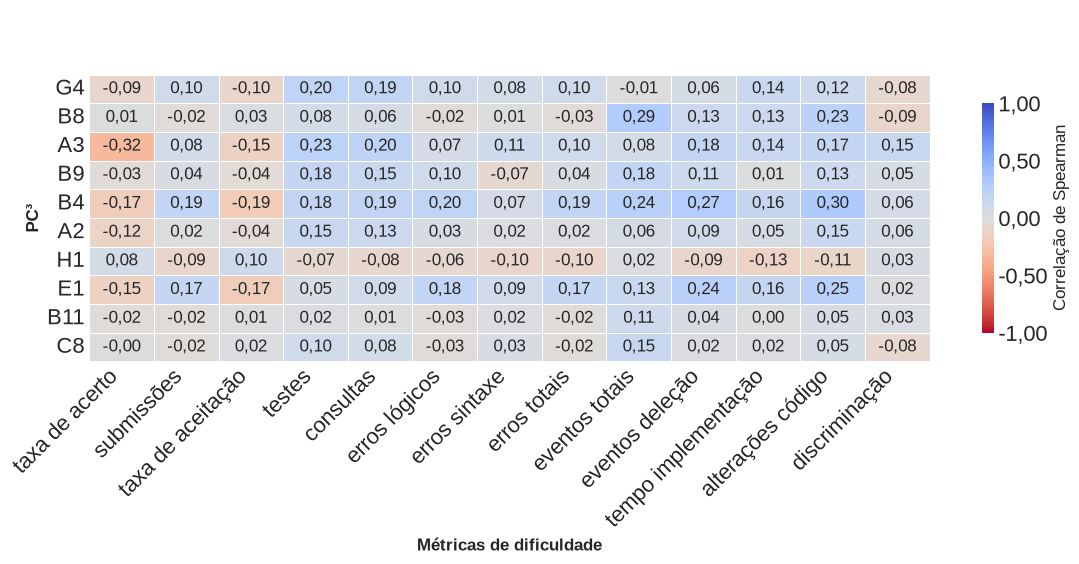

✓ Heatmap exibido

8. Analisando correlações PC³ ↔ Métricas...

CORRELAÇÕES FORTES ENTRE PC³ E MÉTRICAS (|ρ| > 0,7)
Nenhuma correlação forte encontrada entre PC³ e Métricas.

CORRELAÇÕES MODERADAS ENTRE PC³ E MÉTRICAS (0,5 < |ρ| ≤ 0,7)
Nenhuma correlação moderada encontrada.

RESUMO DA ANÁLISE
✓ Total de questões analisadas: 617
✓ PC³ analisados: 10 (Todos)
✓ Métricas de dificuldade analisadas: 13
✓ Dimensão da matriz: 10 PC³ × 13 Métricas
✓ Correlações fortes  (|ρ| > 0,7): 0
✓ Correlações moderadas (0,5 < |ρ| ≤ 0,7): 0

⚠️  Métrica 'dificuldade' ignorada conforme configuração.

ANÁLISE CONCLUÍDA COM SUCESSO!


In [5]:
from pathlib import Path
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# Configurações

# Mapeamento de Colunas PC³

# ============================================================================
# MAPEAMENTO DAS MÉTRICAS DE DIFICULDADE
# Colunas reais do CSV → nomes legíveis
# 'dificuldade' é ignorada intencionalmente
# M1:  taxa_acerto           = num_correct / num_students_interactions
# M2:  num_submissoes        = num_submissions / num_students_interactions
# M3:  taxa_aceitacao        = num_correct / num_submissions
# M4:  num_testes            = num_tests / num_students_interactions
# M5:  num_consultas         = (num_submissions + num_tests) / num_students_interactions
# M6:  num_erros_lgcs        = num_logic_errors / num_students_interactions
# M7:  num_errors_stx        = num_syntax_errors / num_students_interactions
# M8:  num_erros             = num_errors / num_students_interactions
# M9:  num_eventos           = num_events / num_students_interactions
# M10: num_eventos_del       = num_deletes / num_students_interactions
# M11: tempo_implementacao   = code_time / num_correct
# M12: qtd_alteracoes_codigo = amount_of_change / num_students_interactions
# M13: discriminacao         (fórmula própria - já calculada)
# ============================================================================

def formatar_decimal(valor, casas=2):
    """Formata decimal com vírgula"""
    if pd.isna(valor) or np.isnan(valor):
        return 'N/A'
    formato = f"{{:.{casas}f}}"
    return formato.format(valor).replace('.', ',')

# Configuração de estilo
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

def analisar_correlacao_pc3_metricas(top_n=TOP_N_PC3):
    """
    Analisa correlação entre PC³ e Métricas de Dificuldade

    Parâmetros:
        top_n (int): Número de PC³ mais frequentes a analisar. Default: 10
                     Use None para analisar todos os PC³ ativos.
    """

    print("=" * 80)
    print("ANÁLISE DE CORRELAÇÃO: PC³ vs MÉTRICAS DE DIFICULDADE")
    print("=" * 80)

    # 1. CARREGAR DADOS
    print("\n1. Carregando dados...")
    df = pd.read_csv(QUESTIONS_PATH)
    print(f"   Total de questões no arquivo: {len(df)}")

    # 2. FILTRAR QUESTÕES COM 16+ RESPOSTAS
    print("\n2. Filtrando questões com 16+ respostas...")
    if 'respostas' not in df.columns:
        raise ValueError("A base precisa conter a coluna 'respostas' para aplicar o filtro mínimo de respostas.")
    df['respostas'] = pd.to_numeric(df['respostas'], errors='coerce')
    df_filtered = df[df['respostas'] >= MIN_QUESTAO_RESPOSTAS].copy()
    pc3_columns = [col for col in list(PC3_MAP.keys()) if col in df.columns]
    print(f"   Questões com 16+ respostas: {len(df_filtered)}")
    print(f"   Questões excluídas: {len(df) - len(df_filtered)}")

    # 3. IDENTIFICAR COLUNAS PC³ ATIVAS (não vazias)
    print("\n3. Identificando PC³ ativos...")
    pc3_active = []
    pc3_removed = []

    for col in pc3_columns:
        if df_filtered[col].sum() > 0:
            pc3_active.append(col)
        else:
            pc3_removed.append(PC3_MAP[col])

    if pc3_removed:
        print(f"   ⚠️ PC³ removidos (sem ocorrências): {', '.join(pc3_removed)}")
    print(f"   ✓ PC³ ativos totais: {len(pc3_active)}")

    # 4. IDENTIFICAR MÉTRICAS DE DIFICULDADE DISPONÍVEIS NO CSV
    print("\n4. Identificando métricas de dificuldade válidas...")
    difficulty_metrics = []

    for metric in traducao_metricas.keys():
        if metric in df_filtered.columns:
            try:
                df_filtered[metric] = pd.to_numeric(df_filtered[metric], errors='coerce')
                if df_filtered[metric].dropna().shape[0] > 0:
                    difficulty_metrics.append(metric)
            except:
                pass
        else:
            print(f"   ⚠️ Coluna '{metric}' não encontrada no CSV. Ignorando.")

    print(f"   ✓ Métricas válidas para análise: {len(difficulty_metrics)}")
    for i, m in enumerate(difficulty_metrics, 1):
        print(f"     MD{i}: {m} → {traducao_metricas[m]}")

    # 5. ORDENAR PC³ POR FREQUÊNCIA E APLICAR TOP_N
    print("\n5. Ordenando PC³ por frequência...")
    pc3_totals = {col: df_filtered[col].sum() for col in pc3_active}
    pc3_sorted = sorted(pc3_totals.items(), key=lambda x: x[1], reverse=True)
    pc3_sorted = [(col, total) for col, total in pc3_sorted
                  if total >= PC3_MIN_OCCURRENCES]
    print(f"   PC³ com {PC3_MIN_OCCURRENCES} ou mais ocorrências: {len(pc3_sorted)}")

    if top_n is not None and top_n < len(pc3_sorted):
        pc3_sorted = pc3_sorted[:top_n]
        print(f"   ℹ️ Selecionando os Top {top_n} PC³ mais frequentes")
    else:
        print(f"   ℹ️ Analisando todos os {len(pc3_sorted)} PC³ ativos")

    pc3_ordered = [col for col, _ in pc3_sorted]

    print("   Ordem (decrescente por frequência):")
    display_limit = min(10, len(pc3_ordered))
    for i, col in enumerate(pc3_ordered[:display_limit], 1):
        print(f"      {i}. {PC3_MAP[col]}: {int(pc3_totals[col])} ocorrências")
    if len(pc3_ordered) > display_limit:
        print(f"      ... e mais {len(pc3_ordered) - display_limit} PC³")

    # 6. CALCULAR CORRELAÇÃO ENTRE PC³ E MÉTRICAS
    print("\n6. Calculando correlação de Spearman (PC³ vs Métricas)...")

    n_pc3 = len(pc3_ordered)
    n_metrics = len(difficulty_metrics)

    corr_cross = np.zeros((n_pc3, n_metrics))

    for i, pc3_col in enumerate(pc3_ordered):
        for j, metric_col in enumerate(difficulty_metrics):
            valid_mask = df_filtered[pc3_col].notna() & df_filtered[metric_col].notna()
            if valid_mask.sum() > 1:
                corr_val = df_filtered.loc[valid_mask, [pc3_col, metric_col]].corr(method='spearman').iloc[0, 1]
                corr_cross[i, j] = corr_val
            else:
                corr_cross[i, j] = np.nan

    pc3_names = [PC3_MAP[col] for col in pc3_ordered]
    metric_names = [traducao_metricas[m] for m in difficulty_metrics]

    # 7. EXIBIR MATRIZ (TEXTO)
    print("\n" + "=" * 80)
    print("MATRIZ DE CORRELAÇÃO: PC³ (linhas) vs MÉTRICAS (colunas)")
    print("=" * 80)
    print()

    header = f"{'PC³':<20}"
    for name in metric_names:
        header += f"{name[:12]:>14}"
    print(header)
    print("-" * (20 + 14 * n_metrics))

    for i, pc3_name in enumerate(pc3_names):
        line = f"{pc3_name:<20}"
        for j in range(n_metrics):
            val = corr_cross[i, j]
            line += f"{'N/A':>14}" if np.isnan(val) else f"{formatar_decimal(val, 2):>14}"
        print(line)

    # 8. HEATMAP COMPLETO
    print("\n7. Gerando heatmap...")

    plt.figure(figsize=(n_metrics * 0.9, max(5.8, n_pc3 * 0.5)))

    corr_df = pd.DataFrame(corr_cross, index=pc3_names, columns=metric_names)
    annot_data = corr_df.map(lambda x: formatar_decimal(x, 2))

    sns.heatmap(corr_df,
                annot=annot_data,
                fmt='',
                cmap='coolwarm_r',
                center=0,
                vmin=-1,
                vmax=1,
                linewidths=0.5,
                cbar_kws={"shrink": 0.8, "label": "Correlação de Spearman"})

    plt.title('\n', fontsize=14, fontweight='bold', pad=20)
    plt.xlabel('Métricas de dificuldade', fontsize=12, fontweight='bold')
    plt.ylabel('PC³', fontsize=12, fontweight='bold')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)

    ax = plt.gca()
    colorbar = ax.collections[0].colorbar
    colorbar.ax.yaxis.set_major_formatter(FuncFormatter(lambda x, p: formatar_decimal(x, 2)))

    plt.tight_layout()
    salvar_figura_pdf(plt.gcf(), "4_PC3/correlacao_metricas_dificuldade_pc3.pdf")
    plt.show()
    print("✓ Heatmap exibido")

    # 9. CORRELAÇÕES FORTES
    print("\n8. Analisando correlações PC³ ↔ Métricas...")
    print("\n" + "=" * 80)
    print("CORRELAÇÕES FORTES ENTRE PC³ E MÉTRICAS (|ρ| > 0,7)")
    print("=" * 80)

    strong_cross = []
    for i in range(n_pc3):
        for j in range(n_metrics):
            val = corr_cross[i, j]
            if not np.isnan(val) and abs(val) > 0.7:
                strong_cross.append({
                    'PC³': pc3_names[i],
                    'Métrica': metric_names[j],
                    'ρ': formatar_decimal(val, 2)
                })

    if strong_cross:
        print(pd.DataFrame(strong_cross).to_string(index=False))
    else:
        print("Nenhuma correlação forte encontrada entre PC³ e Métricas.")

    # 10. CORRELAÇÕES MODERADAS
    print("\n" + "=" * 80)
    print("CORRELAÇÕES MODERADAS ENTRE PC³ E MÉTRICAS (0,5 < |ρ| ≤ 0,7)")
    print("=" * 80)

    moderate_cross = []
    for i in range(n_pc3):
        for j in range(n_metrics):
            val = corr_cross[i, j]
            if not np.isnan(val) and 0.5 < abs(val) <= 0.7:
                moderate_cross.append({
                    'PC³': pc3_names[i],
                    'Métrica': metric_names[j],
                    'ρ': formatar_decimal(val, 2)
                })

    if moderate_cross:
        print(pd.DataFrame(moderate_cross).to_string(index=False))
    else:
        print("Nenhuma correlação moderada encontrada.")

    # 11. RESUMO FINAL
    print("\n" + "=" * 80)
    print("RESUMO DA ANÁLISE")
    print("=" * 80)
    print(f"✓ Total de questões analisadas: {len(df_filtered)}")
    print(f"✓ PC³ analisados: {n_pc3} {'(Top ' + str(top_n) + ')' if top_n else '(Todos)'}")
    print(f"✓ Métricas de dificuldade analisadas: {n_metrics}")
    print(f"✓ Dimensão da matriz: {n_pc3} PC³ × {n_metrics} Métricas")
    print(f"✓ Correlações fortes  (|ρ| > 0,7): {len(strong_cross)}")
    print(f"✓ Correlações moderadas (0,5 < |ρ| ≤ 0,7): {len(moderate_cross)}")
    print(f"\n⚠️  Métrica 'dificuldade' ignorada conforme configuração.")
    print("\n" + "=" * 80)
    print("ANÁLISE CONCLUÍDA COM SUCESSO!")
    print("=" * 80)


# EXECUTAR ANÁLISE
print("\n")
print("💡 USO: analisar_correlacao_pc3_metricas(top_n=TOP_N_PC3)")
print("   - top_n=10   : após o filtro, limita aos 10 mais frequentes")
print("   - top_n=None : analisa todos os PC³ com o mínimo de ocorrências")
print("=" * 80)
print("\n")

analisar_correlacao_pc3_metricas(top_n=TOP_N_PC3)

### 4.1. Pipeline integrada de métricas, componentes e modelos PC³
A análise descritiva, a redução exploratória das métricas, os diagnósticos de fatorabilidade e a validação da QP5/QP6 são executados neste notebook. Não há dependência de scripts Python auxiliares para produzir os resultados finais. A análise é associativa, não causal.

A QP5 é ajustada mais adiante por GLMM Bernoulli-logit Bayesiano variacional (`statsmodels.BinomialBayesMixedGLM`), com seis preditores transformados por `log1p` e padronizados pelo desvio-padrão amostral, além de interceptos aleatórios cruzados por estudante e questão. A QP6 é calculada no nível do estudante e inclui uma sensibilidade à oportunidade de observação com `log(número de episódios)`, erros HC3 e ajuste Benjamini–Hochberg global.

In [6]:
import json, os, re, shutil, subprocess, tempfile
from types import SimpleNamespace
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2, kurtosis, skew, spearmanr

PIPELINE_METRICAS = [
    ('MD1', 'taxa_acerto', 'Taxa de acerto', 'taxa_acerto'),
    ('MD2', 'num_submissoes', 'Submissões', 'num_submissoes'),
    ('MD3', 'taxa_aceitacao', 'Taxa de aceitação', 'taxa_aceitacao'),
    ('MD4', 'num_testes', 'Testes', 'num_testes'),
    ('MD6', 'num_erros_lgcs', 'Erros lógicos', 'num_erros_lgcs'),
    ('MD7', 'num_errors_stx', 'Erros de sintaxe', 'num_errors_stx'),
    ('MD9', 'num_eventos_del', 'Eventos de deleção', 'num_eventos_del'),
    ('MD11', 'tempo_implementacao', 'Tempo de implementação', 'tempo_implementacao'),
    ('MD12', 'qtd_alteracoes_codigo', 'Alterações no código', 'qtd_alteracoes_codigo'),
]
def pipeline_ptxt(p):
    """Formata p-valor em português e não confunde ausência com significância."""
    if not np.isfinite(p):
        return 'indisponível'
    return '<0,001' if p < .001 else f'{p:.3f}'.replace('.', ',')

def pipeline_corr_stats(x):
    """Calcula matrizes de rho de Spearman e p-valor bruto para colunas numéricas."""
    rho, p = spearmanr(x.to_numpy(float), axis=0)
    return (
        pd.DataFrame(rho, index=x.columns, columns=x.columns),
        pd.DataFrame(p, index=x.columns, columns=x.columns),
    )

def pipeline_vif_table(x):
    """Calcula VIF por métrica a partir da matriz de correlação, para diagnosticar colinearidade."""
    r = x.corr().to_numpy()
    inv = np.linalg.pinv(r, rcond=1e-12)
    return pd.Series(np.diag(inv), index=x.columns).replace([np.inf, -np.inf], np.inf)

def pipeline_kmo_bartlett(x):
    """Calcula KMO global, MSA por variável e teste de esfericidade de Bartlett."""
    r=x.corr().to_numpy(); n,p=x.shape; sign,logdet=np.linalg.slogdet(r)
    if sign<=0: return {'n':n,'p':p,'determinante':0.0,'KMO':np.nan,'bartlett_chi2':np.nan,'bartlett_df':p*(p-1)//2,'bartlett_p':np.nan},pd.DataFrame({'variavel':x.columns,'MSA':np.nan})
    inv=np.linalg.inv(r); den=np.sqrt(np.outer(np.diag(inv),np.diag(inv))); partial=-inv/den; np.fill_diagonal(partial,0)
    rr=r.copy(); np.fill_diagonal(rr,0); r2=rr**2; p2=partial**2
    msa=r2.sum(axis=1)/(r2.sum(axis=1)+p2.sum(axis=1)); kmo=float(r2.sum()/(r2.sum()+p2.sum()))
    stat=float(-(n-1-(2*p+5)/6)*logdet); df=int(p*(p-1)/2); pv=float(chi2.sf(stat,df))
    return {'n':n,'p':p,'determinante':float(np.linalg.det(r)),'KMO':kmo,'bartlett_chi2':stat,'bartlett_df':df,'bartlett_p':pv},pd.DataFrame({'variavel':x.columns,'MSA':msa})

def pipeline_select_variables(x, corr_cut=.90, vif_cut=10):
    """Remove métricas redundantes de forma determinística, priorizando pares |rho| alto e VIF."""
    current=list(x.columns); steps=[]
    while len(current)>3:
        xx=x[current]; corr_values=xx.corr(method='spearman').abs().to_numpy(copy=True); np.fill_diagonal(corr_values,0); corr=pd.DataFrame(corr_values,index=current,columns=current); pairs=np.argwhere(np.triu(corr_values>=corr_cut,1))
        vif=pipeline_vif_table(xx)
        if len(pairs):
            involved=set()
            for i,j in pairs: involved.update([current[i],current[j]])
            # Reprodutível: remover a variável de maior VIF dentro do conjunto redundante.
            victim=sorted(involved,key=lambda c:(-float(vif[c]),-float(corr[c].drop(c).max()),c))[0]
            reason='par |Spearman rho| >= %.2f; VIF=%.3f'%(corr.loc[victim].max(),vif[victim])
        elif float(vif.max())>vif_cut:
            victim=str(vif.idxmax()); reason='VIF > %.1f; VIF=%.3f'%(vif_cut,vif[victim])
        else: break
        steps.append({'removida':victim,'motivo':reason,'vif_na_iteracao':float(vif[victim])}); current.remove(victim)
    return current,pd.DataFrame(steps)

# Parâmetros visíveis da pipeline: altere aqui somente se houver justificativa metodológica.
PIPELINE_SIMULACOES_PARALELAS = 500
PIPELINE_CORRELACAO_LIMITE = 0.90
PIPELINE_VIF_LIMITE = 10.0


def executar_pipeline_metricas_pc3(
    questoes_path=None,
    episodios_path=None,
    saida_dir=None,
):
    """Executa limpeza, descrições, redundância, PCA e modelos opcionais na amostra Etapa 5.

    Cria os resultados em output/resultados/pipeline_automatico/. A função é a
    versão integrada da antiga pipeline auxiliar: não depende de outro arquivo Python.
    """
    questoes_path = Path(questoes_path or QUESTIONS_PATH)
    episodios_path = Path(episodios_path or OUTPUT_PATH)
    saida_dir = Path(saida_dir or (RESULTS_DIR / 'pipeline_automatico'))
    args = SimpleNamespace(
        questoes=questoes_path,
        episodios=episodios_path,
        saida=saida_dir,
        min_respostas=MIN_QUESTAO_RESPOSTAS,
        min_ocorrencias_pc3=PC3_MIN_OCCURRENCES,
        correlacao_limite=PIPELINE_CORRELACAO_LIMITE,
        vif_limite=PIPELINE_VIF_LIMITE,
        simulacoes_paralelas=PIPELINE_SIMULACOES_PARALELAS,
    )
    out = args.saida
    out.mkdir(parents=True, exist_ok=True)
    # 1. Lê a base por questão e aplica o filtro de respostas mínimas.
    df=pd.read_csv(args.questoes)
    required={'question','respostas','num_eventos','num_eventos_del'}|{x[1] for x in PIPELINE_METRICAS}
    missing=required-set(df.columns)
    if missing: raise ValueError('Colunas ausentes na base de questões: '+', '.join(sorted(missing)))
    df['respostas']=pd.to_numeric(df.respostas,errors='coerce'); df=df[df.respostas>=args.min_respostas].copy()
    X=pd.DataFrame({'question':df.question.astype(str)})
    for old,col,label,_ in PIPELINE_METRICAS: X[old]=pd.to_numeric(df[col],errors='coerce')
    X['MD14']=pd.to_numeric(df.num_eventos,errors='coerce')-pd.to_numeric(df.num_eventos_del,errors='coerce')
    labels={old:label for old,_,label,_ in PIPELINE_METRICAS}; labels['MD14']='Demais eventos (MD14)'
    # 2. IRT 2PL opcional: tenta discriminação por questão; sem convergência, não usa MD13.
    # Decisão formal: excluir MD13-IRT; o ajuste 2PL arquivado não convergiu.
    irt_status='formalmente excluída: o ajuste 2PL anterior não convergiu; MD13-IRT não entra nas análises.'
    # 3. Descreve distribuição, assimetria e curtose; o histograma usa log1p para métricas de contagem.
    metric_cols=[c for c in X.columns if c not in {'question','discriminacao_a','erro_padrao','status_2pl'}]
    stats=[]; sns.set_theme(style='whitegrid'); ncols=3; nrows=int(np.ceil(len(metric_cols)/ncols)); fig,axes=plt.subplots(nrows,ncols,figsize=(13,3.2*nrows)); axes=np.array(axes).reshape(-1)
    bounded={'MD1','MD3'}
    for ax,c in zip(axes,metric_cols):
        v=pd.to_numeric(X[c],errors='coerce').dropna().to_numpy(float); t=v if c in bounded else np.log1p(np.clip(v,0,None))
        ax.hist(t,bins='fd',color='#4C78A8',edgecolor='white'); ax.set_title(f'{c}: {labels.get(c,c)}'); ax.set_xlabel('escala original' if c in bounded else 'log(1 + valor)')
        stats.append({'codigo_original':c,'rotulo':labels.get(c,c),'n':len(v),'media':np.mean(v) if len(v) else np.nan,'mediana':np.median(v) if len(v) else np.nan,'dp':np.std(v,ddof=1) if len(v)>1 else np.nan,'assimetria':skew(v,bias=False) if len(v)>2 else np.nan,'curtose_excesso':kurtosis(v,fisher=True,bias=False) if len(v)>3 else np.nan,'minimo':np.min(v) if len(v) else np.nan,'maximo':np.max(v) if len(v) else np.nan})
    for ax in axes[len(metric_cols):]: ax.remove()
    fig.suptitle(f'Distribuição das métricas — questões com {args.min_respostas}+ respostas'); fig.tight_layout(); fig.savefig(out/'histogramas_metricas_todas.pdf',bbox_inches='tight'); plt.close(fig)
    pd.DataFrame(stats).to_csv(out/'estatisticas_metricas.csv',index=False,decimal=',')
    # 4. Seleciona casos completos e calcula postos padronizados; estes não substituem as métricas originais.
    numeric=X[metric_cols].apply(pd.to_numeric,errors='coerce')
    eligible=numeric.notna().all(axis=1); numeric=numeric.loc[eligible].copy(); qids=X.loc[eligible,'question'].astype(str).reset_index(drop=True)
    if numeric.shape[1]<4: raise ValueError('Menos de quatro métricas válidas para análise')
    ranks=numeric.rank(method='average',ascending=False); rank_z=(ranks-ranks.mean())/ranks.std(ddof=1)
    rank_z.insert(0,'question',qids); rank_z.to_csv(out/'metricas_postos_zscore.csv',index=False)
    rho,pv=pipeline_corr_stats(numeric); rho.to_csv(out/'matriz_spearman_completa.csv',decimal=','); pv.to_csv(out/'matriz_p_bruto_completa.csv',decimal=',')
    # 5. Audita redundância/fatorabilidade antes da seleção automática.
    before,msa0=pipeline_kmo_bartlett(rank_z.drop(columns='question')); msa0.to_csv(out/'msa_antes_selecao.csv',index=False,decimal=',')
    sns.heatmap(rho,vmin=-1,vmax=1,center=0,cmap='vlag',square=True,annot=True,fmt='.2f',cbar_kws={'label':'Spearman rho'}); plt.title('Matriz completa de correlação'); plt.tight_layout(); plt.savefig(out/'matriz_spearman_completa.pdf'); plt.close()
    selected,removals=pipeline_select_variables(rank_z.drop(columns='question'),args.correlacao_limite,args.vif_limite)
    removals.to_csv(out/'metricas_removidas_automaticamente.csv',index=False,decimal=',')
    # 6. Retira MSA < 0,50 iterativamente; registra cada decisão para auditoria.
    msa_log=[]
    while len(selected)>3:
        summ,dt=pipeline_kmo_bartlett(rank_z[selected]);
        if dt.MSA.isna().any() or dt.MSA.min()>=.50: break
        victim=str(dt.loc[dt.MSA.idxmin(),'variavel']); msa_log.append({'removida':victim,'MSA':float(dt.MSA.min()),'motivo':'MSA < 0,50'}); selected.remove(victim)
    pd.DataFrame(msa_log).to_csv(out/'metricas_removidas_por_msa.csv',index=False,decimal=',')
    final=rank_z[selected].copy(); summ,msa=pipeline_kmo_bartlett(final); msa['VIF']=pipeline_vif_table(final).reindex(msa.variavel).to_numpy(); msa.to_csv(out/'diagnostico_final_MSA_VIF.csv',index=False,decimal=',')
    pd.DataFrame([before|{'fase':'após compostos removidos; antes da redundância'},summ|{'fase':'solução final automática'}]).to_csv(out/'diagnosticos_fatorabilidade.csv',index=False,decimal=',')
    # 7. Produz matriz final, tabela renumerada e análise paralela para PCA.
    rf,pf=pipeline_corr_stats(numeric[selected]); rf.to_csv(out/'matriz_spearman_final.csv',decimal=','); pf.to_csv(out/'matriz_p_bruto_final.csv',decimal=',')
    plt.figure(figsize=(max(8,len(selected)*1.15),max(7,len(selected)*.95))); sns.heatmap(rf,vmin=-1,vmax=1,center=0,cmap='vlag',square=True,annot=True,fmt='.2f',cbar_kws={'label':'Spearman rho'}); plt.title('Matriz final após seleção automática'); plt.tight_layout(); plt.savefig(out/'matriz_spearman_final.pdf'); plt.close()
    # Renumeração consecutiva da solução final. Preserva código anterior e regra de seleção.
    maprows=[]
    for i,c in enumerate(selected,1): maprows.append({'codigo_novo':f'MD{i}','codigo_origem':c,'rotulo':labels.get(c,c),'incluida':True})
    for c in metric_cols:
        if c not in selected: maprows.append({'codigo_novo':'','codigo_origem':c,'rotulo':labels.get(c,c),'incluida':False})
    crosswalk=pd.DataFrame(maprows); crosswalk.to_csv(out/'renumeracao_metricas.csv',index=False)
    final_table=rank_z[['question']+selected].copy(); final_table.columns=['question']+[f'MD{i}' for i in range(1,len(selected)+1)]; final_table.to_csv(out/'tabela_metricas_final_postos_zscore.csv',index=False)
    # Análise paralela para número de componentes, 500 réplicas por padrão.
    R=final.corr().to_numpy(); eig=np.linalg.eigvalsh(R)[::-1]; rng=np.random.default_rng(20261027); sims=np.empty((args.simulacoes_paralelas,len(selected)))
    for b in range(args.simulacoes_paralelas):
        z=rng.normal(size=(len(final),len(selected))); sims[b]=np.linalg.eigvalsh(np.corrcoef(z,rowvar=False))[::-1]
    cutoff=np.quantile(sims,.95,axis=0); ncomp=max(1,int(np.sum(eig>cutoff)))
    pca_rows=[]; vals,vecs=np.linalg.eigh(R); order=np.argsort(vals)[::-1]; vals=vals[order]; vecs=vecs[:,order]
    for j,(ev,thr) in enumerate(zip(eig,cutoff),1): pca_rows.append({'componente':j,'autovalor':ev,'limiar_paralelo_95':thr,'retido_analise_paralela':j<=ncomp,'variancia_percentual':100*ev/len(selected)})
    pd.DataFrame(pca_rows).to_csv(out/'pca_analise_paralela.csv',index=False,decimal=',')
    load=vecs[:,:ncomp]*np.sqrt(vals[:ncomp]); load_df=pd.DataFrame(load,index=selected,columns=[f'CP{j}' for j in range(1,ncomp+1)]); load_df.to_csv(out/'pca_cargas.csv',decimal=',')
    # 8. GLMM em R opcional: associação por episódio, PC³ ≥50 e efeitos aleatórios por estudante/questão.
    # O GLMM autoritativo é ajustado em Python na seção QP5 após esta pipeline.
    # Não rodar glmmTMB: a execução arquivada reportou falsa convergência.
    glmm_status='modelo principal ajustado e validado em Python na seção 7; execução R desabilitada.'
    # 9. Registra decisões, limitações e estado de execução para interpretação posterior.
    removed=list(removals.removida) if len(removals) else []; removed_msa=[r['removida'] for r in msa_log]
    report=f'''# Pipeline automático de métricas e PC³\n\n## Amostra e regras\n- Questões analisadas: {len(numeric)} (mínimo {args.min_respostas} respostas; casos completos para métricas: {len(numeric)}).\n- Métricas iniciais: {len(metric_cols)} (MD5, MD8 e MD10 compostas não entram; MD14 = MD10 − MD9).\n- Removidas automaticamente por redundância/colinearidade: {', '.join(removed) if removed else 'nenhuma'}. Regra: remover, entre as métricas em pares com |Spearman rho| >= {args.correlacao_limite}, a de maior VIF; depois remover máximo VIF enquanto > {args.vif_limite}.\n- Removidas por MSA < 0,50: {', '.join(removed_msa) if removed_msa else 'nenhuma'}.\n- Métricas finais consecutivamente renumeradas em renumeracao_metricas.csv; a escolha é um procedimento automático e deve ser relatada no artigo.\n\n## Fatorabilidade final\n- KMO={summ['KMO']:.3f}; Bartlett chi²({summ['bartlett_df']})={summ['bartlett_chi2']:.2f}, p {pipeline_ptxt(summ['bartlett_p'])}; determinante={summ['determinante']:.6g}.\n- MSA mínimo={msa.MSA.min():.3f}; limiares orientativos: KMO >= 0,60 e Bartlett p < 0,05.\n\n## Componentes\nAnálise paralela reteve {ncomp} componente(s) ({args.simulacoes_paralelas} simulações; percentil 95%). Cargas em pca_cargas.csv. A hipótese teórica de três eixos não é imposta: comparar com os dados e justificar no artigo.\n\n## MD13 / IRT 2PL\nStatus: {irt_status}. O 2PL é tentado com mirt; itens sem variação observada recebem a não estimável, não um valor artificial. Revisar diagnósticos, erro-padrão, ajuste e pressupostos antes de reportar.\n\n## GLMM\nStatus: validado separadamente em Python com modelo Bayesiano logístico de interceptos aleatórios cruzados (ver seção QP5); resultados antigos de glmmTMB são apenas arquivo diagnóstico. Desfechos PC³ com pelo menos {args.min_ocorrencias_pc3} ocorrências, efeitos aleatórios cruzados por estudante e questão, seis preditores existentes no pipeline, filtro completo e elegibilidade atual de B8/B4/B9. Conferir convergência e N por desfecho antes de publicar.\n\n## Nota metodológica\nAs métricas são agregadas por questão; o filtro 16+ é aplicado por questão. Correlação é Spearman sobre os valores originais; os postos decrescentes padronizados são exportados para análise de componentes. Remoção automática por maior VIF é uma regra operacional reproduzível, não uma decisão teórica.\n'''
    (out/'RELATORIO_PIPELINE_AUTOMATICO.md').write_text(report,encoding='utf-8')
    catalogo_saidas = [
        {"arquivo":"histogramas_metricas_todas.pdf", "unidade":"questão", "conteudo":"Distribuição das métricas iniciais; contagens em escala log1p e proporções em escala original.", "uso":"Identificar assimetria, caudas e possíveis valores extremos antes de escolher testes/modelos."},
        {"arquivo":"estatisticas_metricas.csv", "unidade":"questão", "conteudo":"N, média, mediana, desvio-padrão, assimetria, curtose, mínimo e máximo por métrica.", "uso":"Descrever o comportamento das métricas e apoiar a escolha de resumo/transformação."},
        {"arquivo":"metricas_postos_zscore.csv", "unidade":"questão", "conteudo":"Postos decrescentes padronizados das métricas em casos completos.", "uso":"Colocar escalas distintas em base comparável para seleção e análise dimensional; não é a matriz original."},
        {"arquivo":"matriz_spearman_completa.csv", "unidade":"questão", "conteudo":"Correlações de Spearman entre as métricas originais.", "uso":"Detectar associações monotônicas e pares potencialmente redundantes."},
        {"arquivo":"matriz_p_bruto_completa.csv", "unidade":"questão", "conteudo":"P-valores brutos correspondentes à matriz completa.", "uso":"Auditar a incerteza das correlações; não são efeitos causais nem valores ajustados."},
        {"arquivo":"matriz_spearman_completa.pdf", "unidade":"questão", "conteudo":"Mapa de calor da matriz completa de correlações.", "uso":"Visualizar rapidamente a estrutura de associação e redundância entre métricas."},
        {"arquivo":"msa_antes_selecao.csv", "unidade":"questão/métrica", "conteudo":"MSA inicial de cada métrica antes da seleção automática.", "uso":"Identificar variáveis pouco adequadas à estrutura fatorial exploratória."},
        {"arquivo":"metricas_removidas_automaticamente.csv", "unidade":"métrica", "conteudo":"Métricas removidas por pares com |rho| alto ou VIF elevado, com justificativa e VIF.", "uso":"Auditar exatamente quais variáveis a regra reprodutível retirou."},
        {"arquivo":"metricas_removidas_por_msa.csv", "unidade":"métrica", "conteudo":"Métricas removidas iterativamente por MSA abaixo de 0,50.", "uso":"Documentar a segunda etapa da seleção, após reduzir colinearidade."},
        {"arquivo":"diagnostico_final_MSA_VIF.csv", "unidade":"métrica", "conteudo":"MSA e VIF das métricas retidas.", "uso":"Verificar adequação individual e colinearidade residual da solução final."},
        {"arquivo":"diagnosticos_fatorabilidade.csv", "unidade":"conjunto de métricas", "conteudo":"KMO, Bartlett, determinante e dimensões antes/depois da seleção.", "uso":"Avaliar se os padrões de correlação justificam uma redução exploratória de dimensões."},
        {"arquivo":"matriz_spearman_final.csv", "unidade":"questão", "conteudo":"Spearman das métricas retidas.", "uso":"Verificar a estrutura de associação após seleção."},
        {"arquivo":"matriz_p_bruto_final.csv", "unidade":"questão", "conteudo":"P-valores brutos da matriz final.", "uso":"Auditar a incerteza da solução final; não interpretar isoladamente como causalidade."},
        {"arquivo":"matriz_spearman_final.pdf", "unidade":"questão", "conteudo":"Mapa de calor da solução final de métricas.", "uso":"Comunicar visualmente a estrutura após a remoção de redundâncias."},
        {"arquivo":"renumeracao_metricas.csv", "unidade":"métrica", "conteudo":"Correspondência entre MD original, novo código, rótulo e inclusão/exclusão.", "uso":"Evitar trocar o significado de uma MD depois da renumeração."},
        {"arquivo":"tabela_metricas_final_postos_zscore.csv", "unidade":"questão", "conteudo":"Tabela de postos padronizados das métricas retidas, por questão.", "uso":"Entrada documentada para a análise de componentes principais."},
        {"arquivo":"pca_analise_paralela.csv", "unidade":"componente", "conteudo":"Autovalores observados, limiar de simulação e decisão de retenção.", "uso":"Estimar quantas dimensões retêm mais informação do que ruído aleatório."},
        {"arquivo":"pca_cargas.csv", "unidade":"métrica/componente", "conteudo":"Cargas das métricas retidas nos componentes selecionados.", "uso":"Interpretar quais métricas contribuem para cada dimensão exploratória."},
        {"arquivo":"irt_2pl_por_questao.csv", "unidade":"questão", "conteudo":"Status, discriminação a e erro-padrão do 2PL, quando o ajuste R está disponível.", "uso":"Diagnóstico psicométrico item a item; só usar parâmetro se o modelo convergir e passar diagnóstico."},
        {"arquivo":"irt_2pl_por_questao.csv.diagnosticos.txt", "unidade":"modelo IRT", "conteudo":"Resumo do ajuste e teste M2 do pacote mirt, quando produzido.", "uso":"Inspecionar ajuste global e advertências do 2PL."},
        {"arquivo":"irt_2pl_por_questao.csv.log", "unidade":"execução R", "conteudo":"Saída padrão e erros da tentativa IRT, quando Rscript está disponível.", "uso":"Investigar instalação, avisos e falhas de execução."},
        {"arquivo":"glmmTMB_pc3.csv", "unidade":"episódio/modelo", "conteudo":"Coeficientes, OR, IC, p, p-BH, N e variâncias aleatórias do GLMM em R, quando disponível.", "uso":"Arquivo legado não convergente; não usar como inferência final. A análise autoritativa está em validacao_glmm_python/."},
        {"arquivo":"glmmTMB_pc3.csv.log", "unidade":"execução R", "conteudo":"Saída padrão e erros da tentativa glmmTMB, quando Rscript está disponível.", "uso":"Investigar avisos e falhas de convergência/execução."},
        {"arquivo":"glmmTMB_pc3.csv.erros.json", "unidade":"PC³/modelo", "conteudo":"Erros associados a desfechos específicos que não puderam ser ajustados.", "uso":"Distinguir falha de um resultado nulo ou não significativo."},
        {"arquivo":"RELATORIO_PIPELINE_AUTOMATICO.md", "unidade":"pipeline", "conteudo":"Resumo das regras, métricas removidas, fatorabilidade, PCA, IRT, GLMM e limitações.", "uso":"Rastrear decisões e não transportar automaticamente resultados provisórios para o artigo."},
        {"arquivo":"status_execucao.json", "unidade":"pipeline", "conteudo":"Contagens, métricas retidas, componentes, estados dos modelos e lista real de arquivos gerados.", "uso":"Auditar em formato legível por máquina se uma etapa executou, falhou ou foi pulada."},
        {"arquivo":"catalogo_saidas_pipeline.csv", "unidade":"arquivo gerado", "conteudo":"Este catálogo: nome, unidade, conteúdo e uso analítico de cada saída.", "uso":"Orientar a leitura das saídas sem abrir os arquivos às cegas."},
    ]
    pd.DataFrame(catalogo_saidas).to_csv(out/'catalogo_saidas_pipeline.csv', index=False, encoding='utf-8-sig')

    status={'questoes':len(numeric),'metricas_iniciais':len(metric_cols),'metricas_finais':selected,'componentes_retidos':ncomp,'irt_2pl':irt_status,'glmm':glmm_status,'saida':str(out)}
    status['arquivos_gerados'] = sorted(p.name for p in out.iterdir() if p.is_file() and p.name != 'status_execucao.json') + ['status_execucao.json']
    (out/'status_execucao.json').write_text(json.dumps(status,ensure_ascii=False,indent=2),encoding='utf-8')
    print(json.dumps(status,ensure_ascii=False,indent=2))
    print('Relatório:',out/'RELATORIO_PIPELINE_AUTOMATICO.md')
    return status


PIPELINE_METRICAS_STATUS = executar_pipeline_metricas_pc3()


{
  "questoes": 617,
  "metricas_iniciais": 10,
  "metricas_finais": [
    "MD1",
    "MD4",
    "MD6",
    "MD7",
    "MD9",
    "MD11",
    "MD12",
    "MD14"
  ],
  "componentes_retidos": 2,
  "irt_2pl": "formalmente excluída: o ajuste 2PL anterior não convergiu; MD13-IRT não entra nas análises.",
  "glmm": "modelo principal ajustado e validado em Python na seção 7; execução R desabilitada.",
  "saida": "/tmp/execucao/execucao/extracted/QuestionInsight/Etapa_5/output/resultados/pipeline_automatico",
  "arquivos_gerados": [
    "RELATORIO_PIPELINE_AUTOMATICO.md",
    "catalogo_saidas_pipeline.csv",
    "diagnostico_final_MSA_VIF.csv",
    "diagnosticos_fatorabilidade.csv",
    "estatisticas_metricas.csv",
    "glmmTMB_pc3.csv",
    "glmmTMB_pc3.csv.erros.json",
    "glmmTMB_pc3.csv.log",
    "histogramas_metricas_todas.pdf",
    "irt_2pl_por_questao.csv",
    "irt_2pl_por_questao.csv.diagnosticos.txt",
    "irt_2pl_por_questao.csv.log",
    "matriz_p_bruto_completa.csv",
    "matriz_

## 5. QP6 — Associação entre PC³ e perfil sociodemográfico
A análise usa exclusivamente os estudantes ligados às 617 questões com pelo menos 16 respostas. Os quatro campos sociais são extraídos diretamente dos arquivos `user.data` locais referenciados por `Etapa_2/output/referencias_processamento.json`, usando as funções integradas `carregar_referencias()` e `iterar_arquivos_usuario()`. A unidade é o estudante, não cada episódio. Para perfis com arquivos divergentes, o campo conflitante é tratado como ausente. A prevalência de cada PC³ é definida pela presença de pelo menos uma ocorrência nos episódios do estudante.


### Execução e saídas da QP6
A célula seguinte reconstrói os perfis a partir dos `user.data` locais referenciados pelo manifesto do repositório, cruza-os com os episódios filtrados, calcula as contingências por estudante, aplica Benjamini–Hochberg global aos testes válidos e grava a tabela LaTeX, a auditoria e as figuras. Nenhum ZIP sociodemográfico auxiliar auxiliar é necessário.


In [ ]:
from pathlib import Path
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
import csv
from pathlib import Path
from collections import defaultdict
from scipy.stats import chi2_contingency



def formatar_pvalor(p_val):
    if p_val < 1e-16: return '<< 0,001'
    elif p_val < 1e-3: return '< 0,001'
    else: return f"{p_val:.3f}".replace('.', ',')

def formatar_numero(num):
    if isinstance(num, (int, np.integer)):
        return f"{num:,}".replace(',', '.')
    else:
        num_str = f"{num:.3f}"
        partes = num_str.split('.')
        parte_inteira = f"{int(partes[0]):,}".replace(',', '.')
        parte_decimal = partes[1].rstrip('0') if len(partes) > 1 else ''
        return f"{parte_inteira},{parte_decimal}" if parte_decimal else parte_inteira

def extrair_campo_user_data(conteudo, campo_busca):
    linhas = conteudo.split('\n')
    for linha in linhas:
        linha = linha.strip()
        if linha.startswith('----'):
            linha_limpa = linha.replace('----', '').strip()
            if linha_limpa.lower().startswith(campo_busca.lower() + ':'):
                if ':' in linha_limpa:
                    _, valor = linha_limpa.split(':', 1)
                    valor = valor.strip()
                    return valor if valor else None
    return None

def carregar_dados_usuarios():
    usuarios_catalogados = set()
    colunas_padrao = ['usuario', 'school_type', 'previous_experience', 'share_pc', 'worked_interned']

    try:
        with open(MISCONCEPTIONS_PATH, 'r', encoding='utf-8') as f:
            reader = csv.DictReader(f)
            for linha in reader:
                if 'usuario' in linha and linha['usuario']:
                    usuarios_catalogados.add(linha['usuario'])
    except FileNotFoundError:
        print(f"⚠️  Arquivo {MISCONCEPTIONS_PATH} não encontrado!")
        return pd.DataFrame(columns=colunas_padrao)

    if not USER_DATA_PATH.exists():
        print(f"⚠️  JSON de referências {USER_DATA_PATH} não existe!")
        return pd.DataFrame(columns=colunas_padrao)
    manifest = carregar_referencias(USER_DATA_PATH)

    dados_usuarios = []
    for usuario in usuarios_catalogados:
        arquivos_user_data = list(iterar_arquivos_usuario(manifest, usuario, 'user_data', 'user.data'))
        arquivo_user_data = arquivos_user_data[0] if arquivos_user_data else None

        if arquivo_user_data is not None:
            try:
                with open(arquivo_user_data, 'r', encoding='utf-8') as f:
                    conteudo = f.read()

                school_type     = extrair_campo_user_data(conteudo, "school type")
                previous_exp    = extrair_campo_user_data(conteudo, "previous experience of any computer language")
                share_pc        = extrair_campo_user_data(conteudo, "share this PC with other people at home")
                worked_interned = extrair_campo_user_data(conteudo, "worked or interned before the degree")

                if previous_exp and previous_exp.lower().startswith('yes'):
                    previous_exp = 'yes'

                dados_usuarios.append({
                    'usuario': usuario,
                    'school_type': school_type,
                    'previous_experience': previous_exp,
                    'share_pc': share_pc,
                    'worked_interned': worked_interned
                })
            except Exception:
                pass

    if not dados_usuarios:
        print(f"⚠️  Nenhum dado de usuário foi coletado!")
        return pd.DataFrame(columns=colunas_padrao)

    return pd.DataFrame(dados_usuarios)

def load_and_process_data():
    df_misc = pd.read_csv(MISCONCEPTIONS_PATH)
    df_misc['usuario'] = df_misc['usuario'].astype(str)

    for mi in PC3_MAP.values():
        df_misc[f'tem_{mi}'] = False

    counts = defaultdict(lambda: defaultdict(int))
    for _, row in df_misc.iterrows():
        misc_str = str(row['misconceptions_detectados'])
        if misc_str != 'nan':
            for mi in [m.strip() for m in misc_str.split(',')]:
                if mi in PC3_MAP.values():
                    counts[mi][str(row['usuario'])] += 1

    for mi in PC3_MAP.values():
        col = f'tem_{mi}'
        for u, count in counts[mi].items():
            df_misc.loc[df_misc['usuario'] == u, col] = count > 0

    df_usuarios = carregar_dados_usuarios()
    return df_misc.merge(df_usuarios, on='usuario', how='left')

def calcular_estatisticas_contingencia(crosstab):
    try:
        chi2, p_val, dof, exp = chi2_contingency(crosstab)
        n = crosstab.sum().sum()
        min_dim = min(crosstab.shape) - 1
        v = np.sqrt(chi2 / (n * min_dim)) if min_dim > 0 else 0
        return chi2, p_val, v
    except:
        return None, None, None

def get_top_misconceptions(df, n=None):
    """Retorna os PC³ elegíveis segundo o catálogo e os filtros globais.

    ``PC3_MAP`` é o catálogo único de misconceptions possíveis. Todos os seus
    códigos são avaliados; a seleção aplica somente ``PC3_MIN_OCCURRENCES`` e
    ``TOP_MISCONCEPTIONS``. Colunas diretas como ``B4``, ``B8`` ou ``B9`` são
    deliberadamente ignoradas.

    A frequência é obtida de ``misconceptions_detectados``. Quando essa coluna
    não existe, são usados somente os indicadores padronizados ``tem_PC3``.
    """
    candidatos = []
    texto_coluna = 'misconceptions_detectados' in df.columns
    for pc in PC3_MAP:
        if texto_coluna:
            total = int(
                df['misconceptions_detectados']
                .fillna('')
                .astype(str)
                .map(lambda valor: sum(item.strip() == pc for item in valor.split(',')))
                .sum()
            )
        elif f'tem_{pc}' in df.columns:
            total = int(df[f'tem_{pc}'].fillna(False).astype(bool).sum())
        else:
            continue
        if total >= PC3_MIN_OCCURRENCES:
            candidatos.append((pc, total))
    candidatos.sort(key=lambda item: (-item[1], item[0]))
    if n is not None:
        candidatos = candidatos[:int(n)]
    return [pc for pc, _ in candidatos]

def calcular_cobertura_fator(df, coluna_fator, labels_validos, total_alunos_global, total_codigos_global):
    df_por_usuario = df.drop_duplicates(subset='usuario')
    mask_valido = df_por_usuario[coluna_fator].isin(labels_validos)
    alunos_com = mask_valido.sum()
    alunos_sem = len(df_por_usuario) - alunos_com
    mask_cod = df[coluna_fator].isin(labels_validos)
    codigos_com = mask_cod.sum()
    codigos_sem = len(df) - codigos_com
    pct_alunos  = 100 * alunos_com  / total_alunos_global  if total_alunos_global  > 0 else 0
    pct_codigos = 100 * codigos_com / total_codigos_global if total_codigos_global > 0 else 0
    return {
        'alunos_com':   alunos_com,
        'alunos_sem':   alunos_sem,
        'codigos_com':  codigos_com,
        'codigos_sem':  codigos_sem,
        'pct_alunos':   pct_alunos,
        'pct_codigos':  pct_codigos,
    }

def desenhar_tabela_no_eixo(ax, mi_name, fator_nome, categorias, crosstab, p_value, cramers_v,
                            significativo=True):
    TRADUCAO_CATEGORIAS = {
        'yes': 'Sim', 'no': 'Não', 'public school': 'Pública',
        'private school': 'Privada', 'technical school': 'Técnica'
    }
    categorias_pt  = [TRADUCAO_CATEGORIAS.get(cat, cat) for cat in categorias]
    n_categorias   = len(categorias_pt)
    cor_header   = '#34495e'
    cor_border   = '#2c3e50'
    cor_texto    = '#2c3e50'
    cor_destaque = '#3498db'
    table_top  = 8.0
    cell_width = 1.8 if n_categorias == 2 else 1.5
    cell_height = 1.2
    start_x    = 5 - (cell_width * (n_categorias + 1)) / 2
    largura_total = cell_width * (n_categorias + 1)

    ax.add_patch(FancyBboxPatch((start_x, table_top), largura_total, cell_height,
                                boxstyle="round,pad=0.05", edgecolor=cor_border,
                                facecolor=cor_header, linewidth=2))
    ax.text(start_x + largura_total / 2, table_top + cell_height / 2, fator_nome,
            ha='center', va='center', fontsize=12, fontweight='bold', color='white')

    table_top2 = table_top - cell_height
    ax.add_patch(FancyBboxPatch((start_x, table_top2), cell_width, cell_height,
                                boxstyle="round,pad=0.05", edgecolor=cor_border,
                                facecolor=cor_destaque, linewidth=2))
    ax.text(start_x + cell_width / 2, table_top2 + cell_height / 2, 'PC³',
            ha='center', va='center', fontsize=12, fontweight='bold', color='white')

    for i, cat_nome in enumerate(categorias_pt):
        x_cat = start_x + cell_width + i * cell_width
        ax.add_patch(FancyBboxPatch((x_cat, table_top2), cell_width, cell_height,
                                    boxstyle="round,pad=0.05", edgecolor=cor_border,
                                    facecolor=cor_destaque, linewidth=2))
        ax.text(x_cat + cell_width / 2, table_top2 + cell_height / 2, cat_nome,
                ha='center', va='center', fontsize=11, fontweight='bold', color='white')

    table_top3 = table_top2 - cell_height
    ax.add_patch(FancyBboxPatch((start_x, table_top3), cell_width, cell_height,
                                boxstyle="round,pad=0.05", edgecolor=cor_border,
                                facecolor='#e8f5e9', linewidth=2))
    ax.text(start_x + cell_width / 2, table_top3 + cell_height / 2, f'{mi_name}',
            ha='center', va='center', fontsize=12, fontweight='bold', color=cor_texto)

    for i, cat in enumerate(categorias):
        x_val = start_x + cell_width + i * cell_width
        val   = crosstab.loc[cat, True]  if (cat in crosstab.index and True  in crosstab.columns) else 0
        pct   = (val / crosstab.loc[cat].sum() * 100) if crosstab.loc[cat].sum() > 0 else 0
        ax.add_patch(FancyBboxPatch((x_val, table_top3), cell_width, cell_height,
                                    boxstyle="round,pad=0.05", edgecolor=cor_border,
                                    facecolor='white', linewidth=2))
        ax.text(x_val + cell_width / 2, table_top3 + cell_height / 2,
                f'{formatar_numero(val)}\n({round(pct):.0f}%)',
                ha='center', va='center', fontsize=11, color=cor_texto)

    table_top4 = table_top3 - cell_height
    ax.add_patch(FancyBboxPatch((start_x, table_top4), cell_width, cell_height,
                                boxstyle="round,pad=0.05", edgecolor=cor_border,
                                facecolor='#ffebee', linewidth=2))
    ax.text(start_x + cell_width / 2, table_top4 + cell_height / 2, f'~{mi_name}',
            ha='center', va='center', fontsize=12, fontweight='bold', color=cor_texto)

    for i, cat in enumerate(categorias):
        x_val = start_x + cell_width + i * cell_width
        val   = crosstab.loc[cat, False] if (cat in crosstab.index and False in crosstab.columns) else 0
        pct   = (val / crosstab.loc[cat].sum() * 100) if crosstab.loc[cat].sum() > 0 else 0
        ax.add_patch(FancyBboxPatch((x_val, table_top4), cell_width, cell_height,
                                    boxstyle="round,pad=0.05", edgecolor=cor_border,
                                    facecolor='white', linewidth=2))
        ax.text(x_val + cell_width / 2, table_top4 + cell_height / 2,
                f'{formatar_numero(val)}\n({round(pct):.0f}%)',
                ha='center', va='center', fontsize=11, color=cor_texto)

    stats_width  = 6.0
    stats_height = 1.8
    stats_x = 5 - stats_width / 2
    stats_y = table_top4 - 0.5 - stats_height

    ax.add_patch(FancyBboxPatch((stats_x, stats_y), stats_width, stats_height,
                                boxstyle="round,pad=0.05", edgecolor=cor_border,
                                facecolor='#f8f9fa', linewidth=2))

    if significativo:
        p_str   = formatar_pvalor(p_value)
        v_str   = formatar_numero(cramers_v)
        int_str = ("Muito Forte" if cramers_v > 0.25 else
                   "Forte"       if cramers_v > 0.15 else
                   "Moderado"    if cramers_v > 0.10 else
                   "Fraco"       if cramers_v > 0.05 else "Muito Fraco")
        cor_stat = '#2c3e50'
    else:
        p_str   = formatar_pvalor(p_value) if p_value is not None else 'NS'
        v_str   = 'NS'
        int_str = 'NS'
        cor_stat = '#999999'

    ax.text(5, stats_y + stats_height * 0.75, f'valor-p: {p_str}',
            ha='center', va='center', fontsize=12, fontweight='bold', color=cor_stat)
    ax.text(5, stats_y + stats_height * 0.50, f'V de Cramer: {v_str}',
            ha='center', va='center', fontsize=12, fontweight='bold', color=cor_stat)
    ax.text(5, stats_y + stats_height * 0.25, f'Intensidade: {int_str}',
            ha='center', va='center', fontsize=12, fontweight='bold', color=cor_stat)

    padding = 0.05
    ax.set_xlim(start_x - padding, start_x + largura_total + padding)
    ax.set_ylim(stats_y - padding, table_top + cell_height + padding)
    ax.axis('off')

def desenhar_rodape_cobertura(fig, cob, total_alunos, total_codigos):
    cor_fundo   = '#eaf4fb'
    cor_borda   = '#2980b9'
    cor_titulo  = '#1a5276'
    cor_ok      = '#1e8449'
    cor_falta   = '#922b21'

    ax_rod = fig.add_axes([0.02, 0.01, 0.96, 0.07])
    ax_rod.set_xlim(0, 1)
    ax_rod.set_ylim(0, 1)
    ax_rod.axis('off')

    ax_rod.add_patch(FancyBboxPatch((0, 0), 1, 1,
                                    boxstyle="round,pad=0.01",
                                    edgecolor=cor_borda, facecolor=cor_fundo,
                                    linewidth=1.5, transform=ax_rod.transAxes))

    ax_rod.text(0.5, 0.82, '📊 Cobertura dos dados neste fator',
                ha='center', va='center', fontsize=9, fontweight='bold',
                color=cor_titulo, transform=ax_rod.transAxes)

    txt_alunos_ok   = (f"✔ Alunos com dado: {formatar_numero(int(cob['alunos_com']))} "
                       f"/ {formatar_numero(total_alunos)} "
                       f"({cob['pct_alunos']:.1f}%)")
    txt_alunos_falt = (f"✘ Sem dado: {formatar_numero(int(cob['alunos_sem']))} "
                       f"({100 - cob['pct_alunos']:.1f}%)")
    txt_cod_ok   = (f"✔ Códigos com dado: {formatar_numero(int(cob['codigos_com']))} "
                    f"/ {formatar_numero(total_codigos)} "
                    f"({cob['pct_codigos']:.1f}%)")
    txt_cod_falt = (f"✘ Sem dado: {formatar_numero(int(cob['codigos_sem']))} "
                    f"({100 - cob['pct_codigos']:.1f}%)")

    ax_rod.text(0.02, 0.45, txt_alunos_ok,  ha='left', va='center', fontsize=8.5,
                color=cor_ok,   transform=ax_rod.transAxes, fontweight='bold')
    ax_rod.text(0.30, 0.45, txt_alunos_falt, ha='left', va='center', fontsize=8.5,
                color=cor_falta, transform=ax_rod.transAxes, fontweight='bold')
    ax_rod.text(0.02, 0.15, txt_cod_ok,   ha='left', va='center', fontsize=8.5,
                color=cor_ok,   transform=ax_rod.transAxes, fontweight='bold')
    ax_rod.text(0.30, 0.15, txt_cod_falt,  ha='left', va='center', fontsize=8.5,
                color=cor_falta, transform=ax_rod.transAxes, fontweight='bold')

def gerar_figuras_agrupadas(df, top_misconceptions, grupos_analise,
                             total_alunos_global, total_codigos_global):
    TRADUCAO_FATORES = {
        'school_type':        'Tipo de Escola',
        'previous_experience':'Experiência Prévia com Programação',
        'share_pc':           'Compartilha PC em Casa',
        'worked_interned':    'Trabalhou ou Estagiou Antes do Curso'
    }

    figuras_por_fator = {}

    for grupo in grupos_analise:
        fator_nome       = TRADUCAO_FATORES.get(grupo['column'], grupo['title'])
        resultados_fator = []

        cob = calcular_cobertura_fator(
            df, grupo['column'], grupo['labels'],
            total_alunos_global, total_codigos_global
        )

        for mi_name in top_misconceptions:
            mi_column = f'tem_{mi_name}'
            df_valid  = df[df[grupo['column']].notna()].copy()
            if len(df_valid) > 0 and mi_column in df_valid.columns:
                crosstab = pd.crosstab(df_valid[grupo['column']], df_valid[mi_column])
                if True in crosstab.columns and False in crosstab.columns:
                    labels_presentes = [l for l in grupo['labels'] if l in crosstab.index]
                    if len(labels_presentes) >= 2:
                        crosstab_filtrado = crosstab.loc[labels_presentes]
                        chi2, p_value, cramers_v = calcular_estatisticas_contingencia(crosstab_filtrado)
                        significativo = (p_value is not None and cramers_v is not None
                                         and p_value < 0.05)
                        resultados_fator.append({
                            'mi': mi_name, 'categorias': labels_presentes,
                            'crosstab': crosstab_filtrado,
                            'p_value': p_value, 'cramers_v': cramers_v,
                            'significativo': significativo
                        })

        if resultados_fator:
            resultados_fator = sorted(resultados_fator, key=lambda x: (x['cramers_v'] or 0), reverse=True)

            n_tabelas = len(resultados_fator)
            cols      = min(n_tabelas, 3)
            rows      = (n_tabelas + cols - 1) // cols

            n_cat  = len(grupo['labels'])
            base_w = 6 if n_cat == 2 else 7
            base_h = 7

            fig, axes = plt.subplots(rows, cols,
                                     figsize=(base_w * cols, base_h * rows + 1.0))
            fig.subplots_adjust(bottom=0.10)

            if n_tabelas == 1:
                axes = np.array([axes])
            axes_flat = axes.flatten()

            for i, res in enumerate(resultados_fator):
                desenhar_tabela_no_eixo(
                    axes_flat[i], res['mi'], fator_nome, res['categorias'],
                    res['crosstab'], res['p_value'], res['cramers_v'],
                    significativo=res['significativo']
                )

            for j in range(i + 1, len(axes_flat)):
                axes_flat[j].axis('off')

            desenhar_rodape_cobertura(fig, cob, total_alunos_global, total_codigos_global)

            fig.subplots_adjust(left=0.03, right=0.97, top=0.95, bottom=0.14, wspace=0.30, hspace=0.35)
            figuras_por_fator[fator_nome] = fig

            print(f"\n  [{fator_nome}]")
            print(f"    Alunos  com dado: {cob['alunos_com']:>6} / {total_alunos_global} "
                  f"({cob['pct_alunos']:.1f}%)  |  sem dado: {cob['alunos_sem']} "
                  f"({100-cob['pct_alunos']:.1f}%)")
            print(f"    Códigos com dado: {cob['codigos_com']:>6} / {total_codigos_global} "
                  f"({cob['pct_codigos']:.1f}%)  |  sem dado: {cob['codigos_sem']} "
                  f"({100-cob['pct_codigos']:.1f}%)")

    return figuras_por_fator


# =============================================================================
# GERAÇÃO DE CÓDIGO LATEX ORDENADO PELO MENOR P-VALOR
# =============================================================================

def formatar_pvalor_latex(p_val):
    if p_val is None:
        return 'NS'
    if p_val < 1e-16:
        return r'$\ll$ 0,001'
    elif p_val < 1e-3:
        return r'$<$ 0,001'
    else:
        return f"{p_val:.3f}".replace('.', ',')

def formatar_cramers_latex(v, significativo):
    if not significativo or v is None:
        return 'NS'
    return f"{v:.3f}".replace('.', ',')

def intensidade_latex(v, significativo):
    if not significativo or v is None:
        return 'NS'
    if v > 0.25: return 'Muito forte'
    if v > 0.15: return 'Forte'
    if v > 0.10: return 'Moderado'
    if v > 0.05: return 'Fraco'
    return 'Muito fraco'

def calcular_dados_latex(df, grupo, top_misconceptions):
    resultados = []
    for mi_name in top_misconceptions:
        mi_column = f'tem_{mi_name}'
        df_valid  = df[df[grupo['column']].notna()].copy()
        if len(df_valid) == 0 or mi_column not in df_valid.columns:
            continue

        crosstab = pd.crosstab(df_valid[grupo['column']], df_valid[mi_column])
        if True not in crosstab.columns or False not in crosstab.columns:
            continue

        labels_presentes = [l for l in grupo['labels'] if l in crosstab.index]
        if len(labels_presentes) < 2:
            continue

        crosstab_f = crosstab.loc[labels_presentes]
        chi2, p_value, cramers_v = calcular_estatisticas_contingencia(crosstab_f)
        significativo = (p_value is not None and cramers_v is not None and p_value < 0.05)

        cats = {}
        for label in labels_presentes:
            total_cat = crosstab_f.loc[label].sum()
            val_pres  = int(crosstab_f.loc[label, True])  if True  in crosstab_f.columns else 0
            val_aus   = int(crosstab_f.loc[label, False]) if False in crosstab_f.columns else 0
            pct_pres  = round(100 * val_pres / total_cat) if total_cat > 0 else 0
            pct_aus   = 100 - pct_pres
            cats[label] = {
                'presente': val_pres, 'pct_pres': pct_pres,
                'ausente':  val_aus,  'pct_aus':  pct_aus,
            }

        resultados.append({
            'mi':            mi_name,
            'labels':        labels_presentes,
            'cats':          cats,
            'p_value':       p_value if p_value is not None else 1.0, # Atribui 1.0 para jogar NS para o fim
            'cramers_v':     cramers_v,
            'significativo': significativo,
        })

    # CORREÇÃO DA ORDENAÇÃO: Ordena explicitamente pelo menor p-valor
    resultados.sort(key=lambda x: x['p_value'])
    return resultados


def gerar_tablenotes(alunos_sem, codigos_sem, tem_ns=True):
    itens = []
    if alunos_sem > 0 or codigos_sem > 0:
        n_alunos  = formatar_numero(int(alunos_sem))
        n_codigos = formatar_numero(int(codigos_sem))
        itens.append(
            f"        \\item Informações de {n_alunos} estudante(s) e "
            f"{n_codigos} código(s) submetido(s) não puderam ser "
            f"recuperadas no repositório no momento da coleta e não "
            f"foram incluídas nesta análise."
        )
    itens.append(r"        \item NS: não significativo")
    corpo = "\n".join(itens)
    return f"\n    \\begin{{tablenotes}}\n{corpo}\n    \\end{{tablenotes}}"


def gerar_latex_escola(df, top_misconceptions, alunos_sem=0, codigos_sem=0):
    grupo = {
        'column': 'school_type',
        'labels': ('public school', 'private school', 'technical school'),
    }
    dados = calcular_dados_latex(df, grupo, top_misconceptions)
    tem_ns = any(not d['significativo'] for d in dados)

    linhas = []
    for i, d in enumerate(dados):
        PCT = r'\%'
        if i > 0:
            linhas.append(r'        \midrule')
        cats = d['cats']
        pub  = cats.get('public school',    {'presente': 0, 'pct_pres': 0, 'ausente': 0, 'pct_aus': 0})
        pri  = cats.get('private school',   {'presente': 0, 'pct_pres': 0, 'ausente': 0, 'pct_aus': 0})
        tec  = cats.get('technical school', {'presente': 0, 'pct_pres': 0, 'ausente': 0, 'pct_aus': 0})

        # Restaura o p-valor real para exibição se ele foi mascarado para ordenação
        p_real = None if d['p_value'] == 1.0 and not d['significativo'] else d['p_value']
        p_tex = formatar_pvalor_latex(p_real)
        v_tex = formatar_cramers_latex(d['cramers_v'], d['significativo'])
        i_tex = intensidade_latex(d['cramers_v'], d['significativo'])

        linhas.append(
            f"        {d['mi']} & Presente & "
            f"{formatar_numero(pub['presente'])} ({pub['pct_pres']}{PCT}) & "
            f"{formatar_numero(pri['presente'])} ({pri['pct_pres']}{PCT}) & "
            f"{formatar_numero(tec['presente'])} ({tec['pct_pres']}{PCT}) & "
            f"{p_tex} & {v_tex} & {i_tex} \\\\"
        )
        linhas.append(
            f"           & Ausente & "
            f"{formatar_numero(pub['ausente'])} ({pub['pct_aus']}{PCT}) & "
            f"{formatar_numero(pri['ausente'])} ({pri['pct_aus']}{PCT}) & "
            f"{formatar_numero(tec['ausente'])} ({tec['pct_aus']}{PCT}) & & & \\\\"
        )

    corpo      = "\n".join(linhas)
    tablenotes = gerar_tablenotes(alunos_sem, codigos_sem, tem_ns=tem_ns)

    return (
        r"\begin{table}[H]" "\n"
        r"    \centering\footnotesize" "\n"
        r"    \setlength{\tabcolsep}{6pt}" "\n"
        r"    \begin{threeparttable}" "\n"
        r"    \caption{Quantidade de códigos com presença/ausência de PC$^3$, "
        r"distribuídos conforme o tipo de escola do Ensino Médio de origem do aluno "
        r"(convencional pública, convencional privada ou técnica). Fonte: }" "\n"
        r"    \label{tab:misconceptions_escola}" "\n"
        r"    \begin{tabular}{ll rrr ccc}" "\n"
        r"        \toprule" "\n"
        r"        \textbf{PC$^3$} & \textbf{\vtop{\hbox{Presença}\hbox{no código}}} & \textbf{Pública} & "
        r"\textbf{Privada} & \textbf{Técnica} & \textbf{$p$-valor} & "
        r"\textbf{V de Cramer} & \textbf{Intensidade} \\" "\n"
        r"        \midrule" "\n"
        f"{corpo}" "\n"
        r"        \bottomrule" "\n"
        r"    \end{tabular}" "\n"
        f"{tablenotes}" "\n"
        r"    \end{threeparttable}" "\n"
        r"\end{table}"
    )


def gerar_latex_dois_grupos(df, top_misconceptions, grupo, caption, label, col_sim, col_nao,
                            alunos_sem=0, codigos_sem=0):
    dados = calcular_dados_latex(df, grupo, top_misconceptions)
    if not dados:
        return None

    tem_ns = any(not d['significativo'] for d in dados)
    label_sim = grupo['labels'][0]
    label_nao = grupo['labels'][1]

    linhas = []
    for i, d in enumerate(dados):
        PCT = r'\%'
        if i > 0:
            linhas.append(r'        \midrule')
        cats = d['cats']
        sim  = cats.get(label_sim, {'presente': 0, 'pct_pres': 0, 'ausente': 0, 'pct_aus': 0})
        nao  = cats.get(label_nao, {'presente': 0, 'pct_pres': 0, 'ausente': 0, 'pct_aus': 0})

        p_real = None if d['p_value'] == 1.0 and not d['significativo'] else d['p_value']
        p_tex = formatar_pvalor_latex(p_real)
        v_tex = formatar_cramers_latex(d['cramers_v'], d['significativo'])
        i_tex = intensidade_latex(d['cramers_v'], d['significativo'])

        linhas.append(
            f"        {d['mi']} & Presente & "
            f"{formatar_numero(sim['presente'])} ({sim['pct_pres']}{PCT}) & "
            f"{formatar_numero(nao['presente'])} ({nao['pct_pres']}{PCT}) & "
            f"{p_tex} & {v_tex} & {i_tex} \\\\"
        )
        linhas.append(
            f"           & Ausente & "
            f"{formatar_numero(sim['ausente'])} ({sim['pct_aus']}{PCT}) & "
            f"{formatar_numero(nao['ausente'])} ({nao['pct_aus']}{PCT}) & & & \\\\"
        )

    corpo      = "\n".join(linhas)
    tablenotes = gerar_tablenotes(alunos_sem, codigos_sem, tem_ns=tem_ns)

    return (
        r"\begin{table}[H]" "\n"
        r"    \centering\footnotesize" "\n"
        r"    \setlength{\tabcolsep}{7pt}" "\n"
        r"    \begin{threeparttable}" "\n"
        f"    \\caption{{{caption}}}" "\n"
        f"    \\label{{{label}}}" "\n"
        r"    \begin{tabular}{ll rr ccc}" "\n"
        r"        \toprule" "\n"
        f"        \\textbf{{PC$^3$}} & \\textbf{{\\vtop{{\\hbox{{Presença}}\\hbox{{no código}}}}}} & \\textbf{{{col_sim}}} & "
        f"\\textbf{{{col_nao}}} & \\textbf{{$p$-valor}} & "
        r"\textbf{V de Cramer} & \textbf{Intensidade} \\" "\n"
        r"        \midrule" "\n"
        f"        {corpo}" "\n"
        r"        \bottomrule" "\n"
        r"    \end{tabular}" "\n"
        f"{tablenotes}" "\n"
        r"    \end{threeparttable}" "\n"
        r"\end{table}"
    )


def _formatar_numero_tabela(valor, casas=2):
    if pd.isna(valor):
        return "—"
    return f"{float(valor):,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def _formatar_p_tabela(valor):
    if pd.isna(valor):
        return "NS"
    if valor < 0.001:
        return r"$<$ 0,001"
    return f"{valor:.3f}".replace(".", ",")

def _intensidade_efeito(r):
    if pd.isna(r):
        return "NS"
    a=abs(float(r))
    if a < 0.10: return "muito fraco"
    if a < 0.30: return "pequeno"
    if a < 0.50: return "médio"
    return "grande"

def gerar_tabelas_comparacao_pc3(df, output_dir=RESULTS_DIR):
    """Gera tabelas LaTeX e CSV para todos os PC³ que passam o limite global."""
    from scipy.stats import mannwhitneyu, norm
    metricas={
        'MD1: Taxa de acerto (\\%)':'taxa_acerto',
        'MD2: Número de submissões':'num_submissoes',
        'MD3: Taxa de aceitação (\\%)':'taxa_aceitacao',
        'MD4: Número de testes':'num_testes',
        'MD5: Total de consultas':'num_consultas',
        'MD6: Erros de lógica':'num_erros_lgcs',
        'MD7: Erros de sintaxe':'num_errors_stx',
        'MD8: Total de erros':'num_erros',
        'MD9: Eventos deleção':'num_eventos_del',
        'MD10: Total de eventos':'num_eventos',
        'MD11: Tempo de implementação (s)':'tempo_implementacao',
        'MD12: Alterações no código':'qtd_alteracoes_codigo',
        'MD13: Discriminação':'discriminacao',
    }
    output_dir=Path(output_dir); output_dir.mkdir(parents=True,exist_ok=True)
    blocos=[]; row_end=r"\\"
    # Nenhuma linha elegível não é um erro: não há tabela estatística a gerar.
    if df is None or df.empty:
        print("Nenhum dado disponível para gerar tabelas de comparação PC³; etapa ignorada.")
        return pd.DataFrame()
    # A comparação é por questão. Se receber dados individuais, agrega as
    # métricas por questão e conta quantos estudantes apresentaram cada PC³.
    df_comparacao=df.copy()
    if 'question' in df_comparacao.columns and not any(pc in df_comparacao.columns for pc in ('B4','B8','B9')):
        agg_cols={c:'median' for c in metricas.values() if c in df_comparacao.columns}
        if agg_cols:
            df_comparacao=df_comparacao.groupby('question',as_index=False).agg(agg_cols)
        else:
            # Evita pandas GroupBy.aggregate -> "No objects to concatenate".
            # Mantém uma linha por questão para permitir a saída vazia normal.
            df_comparacao=df_comparacao[['question']].drop_duplicates().reset_index(drop=True)
        for _pc in ('B4','B8','B9'):
            _flag=f'tem_{_pc}'
            if _flag in df.columns:
                _counts=df.groupby('question')[_flag].sum().rename(_pc)
                df_comparacao=df_comparacao.merge(_counts,on='question',how='left')
    # Sem colunas PC³, não há comparações possíveis; retorna saída vazia.
    if df_comparacao.empty:
        print("Nenhuma questão disponível para tabelas de comparação PC³; etapa ignorada.")
        return pd.DataFrame()
    # Seleciona dinamicamente todos os PC³ que passaram pelo filtro global.
    pc3_disponiveis=[pc for pc in PC3_MAP if pc in df_comparacao.columns]
    pc3_selecionados=[]
    for pc in pc3_disponiveis:
        total=pd.to_numeric(df_comparacao[pc],errors='coerce').fillna(0).sum()
        if total >= PC3_MIN_OCCURRENCES:
            pc3_selecionados.append((pc,total))
    pc3_selecionados.sort(key=lambda item:(-item[1],item[0]))
    if TOP_N_PC3 is not None:
        pc3_selecionados=pc3_selecionados[:int(TOP_N_PC3)]
    pc3_selecionados=[pc for pc,_ in pc3_selecionados]
    print(f"PC³ selecionados para tabelas (>= {PC3_MIN_OCCURRENCES} ocorrências): {pc3_selecionados}")
    for pc in pc3_selecionados:
        grupo=pd.to_numeric(df_comparacao[pc],errors='coerce').fillna(0)>=5; linhas=[]
        for nome,col in metricas.items():
            if col not in df.columns: continue
            a=pd.to_numeric(df_comparacao.loc[grupo,col],errors='coerce').dropna()
            b=pd.to_numeric(df_comparacao.loc[~grupo,col],errors='coerce').dropna()
            if len(a)==0 or len(b)==0: continue
            u,pv=mannwhitneyu(a,b,alternative='two-sided'); n=len(a)+len(b)
            z=norm.isf(pv/2) if pv>0 else norm.isf(1e-300)
            r=abs(z)/(n**0.5) if n else float('nan')
            linhas.append({'metrica':nome,'coluna':col,'mediana_pc3':a.median(),'mediana_sem_pc3':b.median(),'u':u,'p_valor':pv,'r_efeito':r,'intensidade':_intensidade_efeito(r),'n_pc3':len(a),'n_sem_pc3':len(b)})
        linhas.sort(key=lambda x:-abs(x['r_efeito']) if not pd.isna(x['r_efeito']) else 0)
        pd.DataFrame(linhas).to_csv(output_dir/f'comparacao_{pc}.csv',index=False)
        tex=[r"\\begin{table}[H]",r"    \\centering\\footnotesize",
             f"    \\caption{{Comparação de questões em que cinco ou mais estudantes cometeram o PC$^3$ {pc} ($\\supset$ {pc}) com questões em que menos de cinco alunos cometeram esse PC$^3$ ($\\not\\supset$ {pc}), por métrica de dificuldade, ordenadas pelo tamanho do efeito (intensidade da diferença).}}",
             f"    \\label{{tab:comparacao{pc}}}",r"    \\begin{threeparttable}",r"    \\begin{tabular}{l rr rr rr}",r"        \\toprule"]
        tex.append("        \\textbf{Métrica de dificuldade} & \\multicolumn{2}{c}{\\textbf{Mediana da métrica}} & \\multicolumn{4}{c}{\\textbf{Estatísticas}} " + row_end)
        tex.append(r"        \\cmidrule(lr){2-3} \\cmidrule(lr){4-7}")
        tex.append(f"         & \\textbf{{${{\\supset}}$ {pc}}} & \\textbf{{${{\\not\\supset}}$ {pc}}} & \\textbf{{Valor U}} & \\textbf{{$p$-valor}} & \\textbf{{r de Cohen}} & \\textbf{{Intensidade}} " + row_end + r"        \\midrule")
        for j,x in enumerate(linhas):
            eff=_formatar_numero_tabela(x['r_efeito']) if x['p_valor']<0.05 else 'NS'; inten=x['intensidade'] if x['p_valor']<0.05 else 'NS'
            tex.append(f"        {x['metrica']} & {_formatar_numero_tabela(x['mediana_pc3'])} & {_formatar_numero_tabela(x['mediana_sem_pc3'])} & {_formatar_numero_tabela(x['u'],0)} & {_formatar_p_tabela(x['p_valor'])} & {eff} & {inten} " + row_end)
            if j < len(linhas)-1: tex.append(r"        \\midrule")
        tex += [r"        \\bottomrule",r"    \\end{tabular}",r"    \\begin{tablenotes}",r"        \\item Salvo quando indicado o contrário, a unidade de medida é contagem.",r"        \\item NS: não significativo",r"    \\end{tablenotes}",r"    \\end{threeparttable}",r"\\end{table}"]
        blocos.append('\n'.join(tex))
    out_tex=output_dir/'tabelas_comparacao_pc3.tex'; out_tex.write_text('\n\n'.join(blocos),encoding='utf-8')
    print(f"\nTabelas de comparação PC³ salvas em: {out_tex}")
    return '\n\n'.join(blocos)

def gerar_todos_latex(df, top_misconceptions, arquivo_saida=RESULTS_DIR / "tabelas_latex.tex"):
    blocos = []
    total_alunos  = df['usuario'].nunique()
    total_codigos = len(df)

    def _cob(column, labels):
        df_u  = df.drop_duplicates(subset='usuario')
        a_com = df_u[column].isin(labels).sum()
        c_com = df[column].isin(labels).sum()
        return int(total_alunos - a_com), int(total_codigos - c_com)

    # Tabela 1: Tipo de escola
    labels_escola = ('public school', 'private school', 'technical school')
    a_sem_esc, c_sem_esc = _cob('school_type', labels_escola)
    blocos.append(gerar_latex_escola(df, top_misconceptions,
                                     alunos_sem=a_sem_esc, codigos_sem=c_sem_esc))

    # Tabela 2: Compartilha PC em casa
    grupo_pc = {'column': 'share_pc', 'labels': ('yes', 'no')}
    a_sem_pc, c_sem_pc = _cob('share_pc', ('yes', 'no'))
    tex_pc = gerar_latex_dois_grupos(
        df, top_misconceptions, grupo_pc,
        caption="Distribuição dos PC$^3$ por compartilhamento de computador pessoal em casa",
        label="tab:misconceptions_pc_casa",
        col_sim="Sim", col_nao="Não",
        alunos_sem=a_sem_pc, codigos_sem=c_sem_pc
    )
    if tex_pc: blocos.append(tex_pc)

    # Tabela 3: Experiencia previa em programacao
    grupo_exp = {'column': 'previous_experience', 'labels': ('yes', 'no')}
    a_sem_exp, c_sem_exp = _cob('previous_experience', ('yes', 'no'))
    tex_exp = gerar_latex_dois_grupos(
        df, top_misconceptions, grupo_exp,
        caption="Distribuição dos PC$^3$ por experiência prévia em programação",
        label="tab:misconceptionsExperienciaPrevia",
        col_sim="Sim", col_nao="Não",
        alunos_sem=a_sem_exp, codigos_sem=c_sem_exp
    )
    if tex_exp: blocos.append(tex_exp)

    # Tabela 4: Trabalhou/estagiou antes do curso
    grupo_trab = {'column': 'worked_interned', 'labels': ('yes', 'no')}
    a_sem_trab, c_sem_trab = _cob('worked_interned', ('yes', 'no'))
    tex_trab = gerar_latex_dois_grupos(
        df, top_misconceptions, grupo_trab,
        caption="Distribuição dos PC$^3$ por experiência profissional prévia",
        label="tab:misconceptions_experiencia_profissional",
        col_sim="Sim", col_nao="Não",
        alunos_sem=a_sem_trab, codigos_sem=c_sem_trab
    )
    if tex_trab: blocos.append(tex_trab)

    conteudo = "\n\n".join(str(b) for b in blocos)
    with open(arquivo_saida, 'w', encoding='utf-8') as f:
        f.write(conteudo)

    print(f"\n Código LaTeX salvo em: {arquivo_saida}")
    return conteudo


# Exportação visual opcional das mesmas tabelas geradas em LaTeX.
# O .tex continua sendo a saída editável e principal.
GERAR_PDF_TABELAS = True
MOSTRAR_PREVIEW_TABELAS = False


def _limpar_latex_para_pdf(valor):
    """Converte o texto de uma célula LaTeX em texto legível no PDF."""
    import re
    valor = re.sub(r'\\textbf\{([^}]*)\}', r'\1', str(valor))
    valor = re.sub(r'\\multicolumn\{[^}]*\}\{[^}]*\}\{([^}]*)\}', r'\1', valor)
    valor = re.sub(r'\$([^$]*)\$', r'\1', valor)
    valor = re.sub(r'\\[a-zA-Z]+', '', valor)
    return valor.replace('{', '').replace('}', '').replace('~', ' ').strip()


def gerar_pdfs_visuais_de_tex(caminho_tex, prefixo_pdf=None, mostrar=False):
    """Renderiza cada tabular de um .tex em PDF visual sem alterar o .tex."""
    import re
    import matplotlib.pyplot as plt
    caminho_tex = Path(caminho_tex)
    if not caminho_tex.exists():
        print(f"⚠️ Arquivo LaTeX não encontrado para PDF: {caminho_tex}")
        return []
    conteudo = caminho_tex.read_text(encoding='utf-8')
    blocos = re.findall(r'\\begin\{tabular\}.*?\\end\{tabular\}', conteudo, flags=re.S)
    saidas=[]
    prefixo_pdf = prefixo_pdf or caminho_tex.stem
    for indice, bloco in enumerate(blocos, 1):
        linhas=[]
        for linha in bloco.splitlines():
            linha=linha.strip()
            if not linha or linha.startswith('\\begin') or linha.startswith('\\end'):
                continue
            if any(linha.startswith(x) for x in ('\\toprule','\\midrule','\\bottomrule','\\cmidrule')):
                continue
            if '&' not in linha or '\\\\' not in linha:
                continue
            linha=linha.split('\\\\',1)[0]
            celulas=[_limpar_latex_para_pdf(x) for x in linha.split('&')]
            if any(celulas): linhas.append(celulas)
        if not linhas: continue
        ncol=max(len(x) for x in linhas)
        linhas=[x+['']*(ncol-len(x)) for x in linhas]
        fig,ax=plt.subplots(figsize=(max(10, ncol*2.0), max(3.5, min(18, len(linhas)*0.42+1.5))))
        ax.axis('off')
        tabela=ax.table(cellText=linhas, loc='center', cellLoc='center', colLoc='center')
        tabela.auto_set_font_size(False)
        tabela.set_fontsize(8)
        tabela.scale(1,1.35)
        for (r,col),cell in tabela.get_celld().items():
            if r==0:
                cell.set_text_props(weight='bold')
                cell.set_facecolor('#E8EEF7')
            cell.set_edgecolor('#777777')
        saida=FIGURES_DIR/f'{prefixo_pdf}_{indice:02d}.pdf'
        fig.savefig(saida,bbox_inches='tight',pad_inches=0.2,dpi=300)
        if mostrar: plt.show()
        else: plt.close(fig)
        saidas.append(saida)
    print(f"PDFs visuais gerados a partir de {caminho_tex}: {len(saidas)}")
    return saidas


# Saídas obrigatórias da análise: figuras, preview, LaTeX e PDFs visuais.
GERAR_FIGURAS_CONTINGENCIA = True
MOSTRAR_FIGURAS_CONTINGENCIA = True
GERAR_PDF_TABELAS = True
MOSTRAR_PREVIEW_TABELAS = True


if __name__ == "__main__":
    print("\n" + "=" * 80)
    print("ANÁLISE DE CONTINGÊNCIA - FIGURAS AGRUPADAS")
    print("=" * 80 + "\n")

    df_final = load_and_process_data()
    top_misconceptions = get_top_misconceptions(df_final, n=TOP_MISCONCEPTIONS)

    total_alunos_global  = df_final['usuario'].nunique()
    total_codigos_global = len(df_final)

    print(f"Total de registros carregados : {formatar_numero(total_codigos_global)}")
    print(f"Usuários únicos               : {formatar_numero(total_alunos_global)}")
    print(f"\nPC3 analisados ({len(top_misconceptions)}):")
    for mi in top_misconceptions:
        freq = df_final[f'tem_{mi}'].sum()
        print(f"   {mi}: {formatar_numero(int(freq))} ocorrências")

    grupos_analise = [
        {'column': 'school_type',
         'labels': ('public school', 'private school', 'technical school'),
         'title':  'Tipo de Escola'},
        {'column': 'previous_experience',
         'labels': ('yes', 'no'),
         'title':  'Experiencia Previa'},
        {'column': 'share_pc',
         'labels': ('yes', 'no'),
         'title':  'Compartilha PC'},
        {'column': 'worked_interned',
         'labels': ('yes', 'no'),
         'title':  'Trabalhou/Estagiou'},
    ]

    if GERAR_FIGURAS_CONTINGENCIA:
        print("\nGerando fingerprints / figuras de agrupamento...")
        figuras_agrupadas = gerar_figuras_agrupadas(
            df_final, top_misconceptions, grupos_analise,
            total_alunos_global, total_codigos_global
        )
        if figuras_agrupadas:
            print(f"\n{'='*80}")
            print(f"TOTAL DE FIGURAS GERADAS: {len(figuras_agrupadas)}")
            print(f"{'='*80}\n")
            nomes_figuras_artigo = {
                'Tipo de Escola': 'Tipo_Escola.pdf',
                'Experiência Prévia com Programação': 'Exp_Prev_Programacao.pdf',
                'Trabalhou ou Estagiou Antes do Curso': 'Estagio_Curso.pdf',
                'Compartilha PC em Casa': 'Compartilha_PC_Casa.pdf',
            }
            for fator, fig in figuras_agrupadas.items():
                nome_arquivo = FIGURES_DIR / nomes_figuras_artigo.get(
                    fator, f"{fator.replace(' ', '_').lower()}.pdf"
                )
                fig.savefig(nome_arquivo, bbox_inches='tight', pad_inches=0.1, dpi=300)
                print(f"Salvo: {nome_arquivo}")
                if MOSTRAR_FIGURAS_CONTINGENCIA:
                    plt.show()
                else:
                    plt.close(fig)
        else:
            print("\nNenhuma figura foi gerada.")
    else:
        print("\nFiguras de contingência desativadas; somente tabelas LaTeX serão geradas.")

    print("\nGerando tabelas LaTeX estruturadas...")
    caminho_tabelas_latex = RESULTS_DIR / "tabelas_latex.tex"
    gerar_todos_latex(df_final, top_misconceptions, arquivo_saida=caminho_tabelas_latex)
    # As tabelas de comparação são por questão e precisam das MD1--MD13
    # agregadas em dataset_analise_questoes.csv. df_final contém somente os
    # registros de misconceptions/usuários e, por isso, não possui as MD.
    df_comparacao_pc3 = pd.DataFrame()
    if QUESTIONS_PATH.exists():
        df_comparacao_pc3 = pd.read_csv(QUESTIONS_PATH, encoding="utf-8")
        df_comparacao_pc3["question"] = df_comparacao_pc3["question"].astype(str)
        df_pc3_contagens = df_final.copy()
        df_pc3_contagens["question"] = df_pc3_contagens["question"].astype(str)
        colunas_pc3 = {}
        for _pc in PC3_MAP:
            _flag = f"tem_{_pc}"
            if _flag in df_pc3_contagens.columns:
                colunas_pc3[_pc] = df_pc3_contagens.groupby("question")[_flag].sum()
        if colunas_pc3:
            df_pc3_contagens = pd.DataFrame(colunas_pc3).reset_index()
            df_comparacao_pc3 = df_comparacao_pc3.merge(
                df_pc3_contagens, on="question", how="left"
            )
        print(
            f"Métricas por questão carregadas para comparações PC³: "
            f"{len(df_comparacao_pc3)} questões"
        )
    else:
        print(f"⚠️ Arquivo de métricas por questão não encontrado: {QUESTIONS_PATH}")
    gerar_tabelas_comparacao_pc3(df_comparacao_pc3, output_dir=RESULTS_DIR)
    if GERAR_PDF_TABELAS:
        gerar_pdfs_visuais_de_tex(caminho_tabelas_latex, "tabelas_latex", MOSTRAR_PREVIEW_TABELAS)
        gerar_pdfs_visuais_de_tex(RESULTS_DIR / "tabelas_comparacao_pc3.tex", "tabelas_comparacao_pc3", MOSTRAR_PREVIEW_TABELAS)
    else:
        print("PDFs visuais das tabelas desativados; arquivos .tex preservados.")

    print("\n" + "=" * 80)
    print("ANÁLISE FINALIZADA COM SUCESSO")
    print("=" * 80)


### 7.1. Sensibilidade QP6 à oportunidade de observação
A análise abaixo permanece dentro deste notebook. Para cada PC³, agrega os episódios ao nível do estudante, define ocorrência “ao menos uma vez”, inclui `log(número de episódios)` como covariável, calcula erros-padrão HC3 e aplica Benjamini–Hochberg global aos 40 testes válidos. Trata-se de análise de sensibilidade exploratória; não é causal e não substitui a QP6 principal.

In [ ]:
# Sensibilidade QP6 integrada: GLM logístico por estudante + exposição + HC3 + BH global.
import re, json
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

def executar_qp6_sensibilidade_exposicao():
    ep_path=RESULTS_DIR/'analise_estudantes'/'tabela_analitica.csv'
    d=pd.read_csv(ep_path,dtype={'student_id':'string','question_id':'string'})
    pcs=sorted(c for c in d.columns if re.fullmatch(r'[A-Z][0-9]+',str(c)) and pd.to_numeric(d[c],errors='coerce').fillna(0).sum()>=50)
    if len(pcs)!=10: raise ValueError(f'QP6 sensibilidade esperava 10 PC³; encontrou {pcs}')
    fields={'school_type':'school type','previous_experience':'previous experience of any computer language','share_pc':'share this PC with other people at home','worked_interned':'worked or interned before the degree'}
    # Uses the original QuestionInsight manifest and local user.data files.
    prof=carregar_dados_usuarios().rename(columns={'usuario':'student_id'})
    if prof.empty: raise FileNotFoundError(f'Nenhum user.data foi localizado pelo manifesto {USER_DATA_PATH}')
    prof['student_id']=prof.student_id.astype('string').str.strip().str.replace(r'\.0$','',regex=True)
    prof['school_type']=prof.school_type.astype('string').str.strip().str.lower().where(lambda x:x.isin(['public school','private school','technical school']))
    prof['previous_experience']=prof.previous_experience.astype('object').map(lambda v:v.strip().lower() if isinstance(v,str) else np.nan).map(lambda x:'yes' if isinstance(x,str) and x.startswith('yes') else ('no' if x=='no' else np.nan))
    for f in ['share_pc','worked_interned']: prof[f]=prof[f].astype('string').str.strip().str.lower().where(lambda x:x.isin(['yes','no']))
    counts=d.groupby('student_id').size().rename('n_episodios'); stu=d.groupby('student_id')[pcs].max().join(counts).reset_index().merge(prof,on='student_id',how='left')
    rows=[]
    for pc in pcs:
        for factor in fields:
            x=stu[[pc,factor,'n_episodios']].dropna().copy(); x['log_exposure']=np.log(x.n_episodios.astype(float))
            if x[pc].nunique()<2 or x[factor].nunique()<2: rows.append({'pc3':pc,'fator':factor,'n':len(x),'status':'NAO_ESTIMAVEL'}); continue
            formula=f'Q("{pc}") ~ C(Q("{factor}")) + log_exposure'; fit=smf.glm(formula,data=x,family=sm.families.Binomial()).fit(cov_type='HC3'); terms=[t for t in fit.params.index if t.startswith(f'C(Q("{factor}")')]
            R=np.zeros((len(terms),len(fit.params)))
            for i,t in enumerate(terms): R[i,list(fit.params.index).index(t)]=1
            w=fit.wald_test(R,scalar=True); rows.append({'pc3':pc,'fator':factor,'n':int(fit.nobs),'n_levels':int(x[factor].nunique()),'n_episodios_mediana':float(x.n_episodios.median()),'beta_log_exposure':float(fit.params['log_exposure']),'or_per_log_episode':float(np.exp(fit.params['log_exposure'])),'exposure_p':float(fit.pvalues['log_exposure']),'factor_wald_chi2':float(w.statistic),'factor_df':len(terms),'factor_p':float(w.pvalue),'status':'OK'})
    out=pd.DataFrame(rows); valid=out.status.eq('OK'); out.loc[valid,'factor_q_bh_global']=multipletests(out.loc[valid,'factor_p'],method='fdr_bh')[1]
    outdir=RESULTS_DIR/'validacao_pendencias_python'; outdir.mkdir(parents=True,exist_ok=True); out.to_csv(outdir/'qp6_sensibilidade_exposicao.csv',index=False)
    summary={'model':'GLM logístico por estudante: ocorrência ~ fator + log(número de episódios), covariância HC3','source_manifest':str(USER_DATA_PATH),'tests_valid':int(valid.sum()),'tests_q_bh_lt_0_05':int((out.loc[valid,'factor_q_bh_global']<.05).sum()),'pcs':pcs,'factors':list(fields),'interpretation':'sensibilidade exploratória; não causal; BH global entre testes válidos'}
    (outdir/'auditoria_sensibilidade.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8'); print(json.dumps(summary,ensure_ascii=False,indent=2)); return out
QP6_SENSIBILIDADE = executar_qp6_sensibilidade_exposicao()


## 6. Consolidação das métricas por estudante e questão

Este bloco cria a base analítica no nível de cada episódio estudante–questão. A fonte principal é `misconceptions_detalhado_por_usuario.csv`; executions, actions e notas individuais são associados pelos campos `usuario` e `question`.

O arquivo `metricas_execucao_por_estudante_questao.csv` preserva uma linha por par estudante–questão e reúne métricas brutas, indicadores de misconceptions e dificuldade individual. O arquivo `metricas_individuais_por_estudante.csv` contém as variáveis preparadas para a modelagem individual. As versões por episódio de testes, alterações, erros lógicos, erros de sintaxe, tempo e deleções não devem ser confundidas com as métricas agregadas por questão da Etapa 4.

In [8]:
from pathlib import Path
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

"""
COMBINADOR DE MÉTRICAS - BASEADO EM MISCONCEPTIONS
Usa output/misconceptions_detalhado_por_usuario.csv como fonte principal

MODIFICAÇÕES:
1. nota_aluno é calculada mas NÃO incluída na saída
2. dificuldade é calculada da MESMA forma (do arquivo .log individual)
3. OTIMIZADO: Acesso a disco reduzido, Regex pré-compilado e GroupBy utilizado.
4. NOVO: adicionadas as versões individuais (por episódio) de 3 métricas que
   em output/dataset_analise_questoes.csv só existiam agregadas por questão:
   - taxa_acerto     (M1): = num_correct do próprio episódio (denominador
     "num_students_interactions" do aluno é sempre 1, então degenera em
     num_correct — mantida como coluna própria por nomenclatura/compatibilidade).
   - taxa_aceitacao  (M3): = num_correct / num_submissoes DO PRÓPRIO ALUNO
     (fração das tentativas dele que deram certo — ex.: acertar de primeira
     vs. acertar só na 38ª submissão).
   - num_consultas   (M5): = num_submissoes + num_tests do próprio episódio
     (ANTES ficava sempre NaN, nunca era calculada).
   A métrica M13 (discriminacao) continua fora: é uma estatística sobre o
   conjunto de alunos de uma questão e não tem equivalente por episódio.
"""

import pandas as pd
import numpy as np
import os
import re
import glob

# ============================================================================
# CONFIGURAÇÕES
# ============================================================================


OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# OTIMIZAÇÃO: Pré-compilar o Regex UMA ÚNICA VEZ fora da função

# ============================================================================
# FUNÇÃO: EXTRAIR DIFICULDADE (OTIMIZADA)
# ============================================================================

def obter_nota_arquivo(arquivo_path: str):
    """Extrai somente a GRADE do último SUBMITION válido.

    Retorna float quando existe GRADE explícita, incluindo 0.0, e None quando
    a grade não existe ou o último SUBMITION possui ERROR.
    """
    separador = '*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*'
    try:
        conteudo = Path(arquivo_path).read_text(encoding='utf-8', errors='replace')
    except (OSError, UnicodeError):
        return None
    blocos = [bloco for bloco in conteudo.split(separador)
              if re.search(r'^\s*==\s*SUBMITION\b', bloco, flags=re.I | re.M)]
    for bloco in reversed(blocos):
        # A avaliação oficial é determinada pelo último SUBMITION válido.
        if re.search(r'^\s*-+\s*ERROR\s*:', bloco, flags=re.I | re.M):
            continue
        match = re.search(
            r'^\s*-+\s*GRADE\s*:\s*([+-]?\d+(?:[.,]\d+)?)\s*%?',
            bloco, flags=re.I | re.M
        )
        if match:
            try:
                return float(match.group(1).replace(',', '.'))
            except ValueError:
                return None
    return None

def extrair_dificuldades_para_alunos_questoes(caminho_usuarios, df_misconceptions):
    """
    Extrai dificuldade (nota do .log) APENAS para os pares (aluno, questão) que existem em misconceptions
    Versão Otimizada: Usa operações em lote e busca em memória para reduzir uso do disco (I/O).
    """
    
    print("\n📝 Extraindo dificuldades para pares (aluno, questão) em misconceptions...")
    
    if not os.path.exists(caminho_usuarios):
        print(f"❌ JSON de referências não encontrado: {caminho_usuarios}")
        return None, None
    manifest = carregar_referencias(caminho_usuarios)
    
    # Extrair pares únicos (aluno, questão) de misconceptions
    pares_aluno_questao = df_misconceptions[['usuario', 'question']].drop_duplicates()
    print(f"   • Pares únicos (aluno, questão): {len(pares_aluno_questao)}")
    
    dificuldades_individuais = []
    arquivos_lidos = {}  # {(usuario, questao): caminho}
    
    arquivos_encontrados = 0
    arquivos_nao_encontrados = 0
    dificuldades_extraidas = 0
    dificuldades_zero = 0
    dificuldades_ausentes = 0
    
    # OTIMIZAÇÃO: Agrupar por aluno para varrer o diretório apenas uma vez por pessoa
    questoes_por_aluno = pares_aluno_questao.groupby('usuario')['question'].apply(list).to_dict()

    for aluno, questoes in questoes_por_aluno.items():
        aluno_str = str(aluno)
        caminhos_aluno = list(iterar_arquivos_usuario(manifest, aluno_str, 'executions', '.log'))
        if not caminhos_aluno:
            caminhos_aluno = list(iterar_arquivos_usuario(manifest, aluno_str, 'grades', '.log'))
        if not caminhos_aluno:
            arquivos_nao_encontrados += len(questoes)
            continue
        arquivos_por_nome = {p.name: p for p in caminhos_aluno}

        # Iterar apenas nas questões deste aluno
        for questao in questoes:
            questao_str = str(questao)
            caminho_arquivo_log = None
            
            # OTIMIZAÇÃO: Busca na memória (set intersection) é instantânea
            possiveis_exatos = {f'{questao_str}.log', f'execution_{questao_str}.log', f'{aluno_str}_{questao_str}.log'}
            match_exato = set(arquivos_por_nome).intersection(possiveis_exatos)
            
            if match_exato:
                caminho_arquivo_log = str(arquivos_por_nome[next(iter(match_exato))])
            else:
                # Busca pelo sufixo *_QUESTAO.log na memória
                sufixo_1 = f'_{questao_str}.log'
                for arq, path in arquivos_por_nome.items():
                    if arq.endswith(sufixo_1):
                        caminho_arquivo_log = str(path)
                        break
            
            if caminho_arquivo_log:
                nota_percentual = obter_nota_arquivo(caminho_arquivo_log)
                arquivos_lidos[(aluno_str, questao)] = caminho_arquivo_log
                
                dificuldades_individuais.append({
                    'usuario': aluno_str,
                    'question': questao,
                    'dificuldade': nota_percentual
                })
                
                arquivos_encontrados += 1
                if nota_percentual is None:
                    dificuldades_ausentes += 1
                elif nota_percentual == 0:
                    dificuldades_zero += 1
                else:
                    dificuldades_extraidas += 1
            else:
                arquivos_nao_encontrados += 1
    
    print(f"\n✅ Resultado da extração:")
    print(f"   • Arquivos .log encontrados: {arquivos_encontrados}")
    print(f"   • Arquivos .log NÃO encontrados: {arquivos_nao_encontrados}")
    print(f"   • Dificuldades maiores que zero: {dificuldades_extraidas}")
    print(f"   • Dificuldades iguais a zero: {dificuldades_zero}")
    print(f"   • Dificuldades ausentes: {dificuldades_ausentes}")
    print(f"   • Total de registros processados: {len(dificuldades_individuais)}")
    
    if (arquivos_encontrados + arquivos_nao_encontrados) > 0:
        taxa = arquivos_encontrados / (arquivos_encontrados + arquivos_nao_encontrados) * 100
        print(f"   • Taxa de sucesso: {taxa:.1f}%")
    
    # Mantém as chaves mesmo quando nenhum .log é encontrado.
    df_dificuldades_individuais = pd.DataFrame(
        dificuldades_individuais, columns=['usuario', 'question', 'dificuldade']
    )
    
    return df_dificuldades_individuais, arquivos_lidos


def normalizar_id_usuario(df, coluna='usuario'):
    """Normaliza IDs de usuário"""
    df = df.copy()
    df[coluna] = df[coluna].astype(str)
    df[coluna] = df[coluna].str.replace(r'^(user_|student_|aluno_)', '', regex=True)
    df[coluna] = df[coluna].str.strip().str.lower()
    return df


# ============================================================================
# FUNÇÃO PRINCIPAL
# ============================================================================

def combinar_metricas():
    """Combina métricas baseado em misconceptions"""
    
    print("\n" + "="*80)
    print("COMBINADOR DE MÉTRICAS - BASEADO EM MISCONCEPTIONS")
    print("="*80)
    print("\n⚠️  MODIFICAÇÕES:")
    print("   1. nota_aluno NÃO será incluída na saída")
    print("   2. dificuldade = valor do arquivo .log (individual)")
    print("="*80)
    
    # ========================================================================
    # PASSO 1: Carregar MISCONCEPTIONS (fonte principal)
    # ========================================================================
    
    print("\n📂 Carregando misconceptions (fonte principal)...")
    
    try:
        df_misconceptions = pd.read_csv(MISCONCEPTIONS_PATH)
        print(f"✅ Misconceptions: {len(df_misconceptions)} registros")
        
        # Normalizar IDs
        df_misconceptions = normalizar_id_usuario(df_misconceptions, 'usuario')
        
        # Extrair listas de alunos e questões elegíveis
        alunos_elegiveis = sorted(df_misconceptions['usuario'].unique())
        questoes_elegiveis = sorted(df_misconceptions['question'].unique())
        
        print(f"\n📊 ALUNOS E QUESTÕES ELEGÍVEIS:")
        print(f"   • Total de alunos únicos: {len(alunos_elegiveis)}")
        print(f"   • Total de questões únicas: {len(questoes_elegiveis)}")
        
        print(f"\n📝 Primeiros 20 alunos elegíveis:")
        print(f"   {', '.join(map(str, alunos_elegiveis[:20]))}")
        
        print(f"\n📝 Primeiras 20 questões elegíveis:")
        print(f"   {', '.join(map(str, questoes_elegiveis[:20]))}")
        
    except Exception as e:
        print(f"❌ Erro ao carregar misconceptions: {e}")
        return None
    
    # ========================================================================
    # PASSO 2: FILTRAR Executions pelos pares (student, question) de misconceptions
    # ========================================================================
    
    print("\n📂 PASSO 2: Filtrando Executions...")
    
    try:
        df_executions = pd.read_csv(EXECUTIONS_PATH)
        df_executions = df_executions.rename(columns={'student': 'usuario'})
        df_executions = normalizar_id_usuario(df_executions)
        print(f"✅ Executions lido: {len(df_executions)} registros")
        
        # Criar lista de pares válidos (usuario, question) de misconceptions
        pares_validos = df_misconceptions[['usuario', 'question']].drop_duplicates()
        print(f"   • Pares válidos em misconceptions: {len(pares_validos)}")
        
        # FILTRAR: manter APENAS registros cujo par (usuario, question) existe em misconceptions
        df_executions_filtrado = pares_validos.merge(
            df_executions,
            on=['usuario', 'question'],
            how='inner'
        )
        
        registros_removidos = len(df_executions) - len(df_executions_filtrado)
        print(f"   • Registros MANTIDOS: {len(df_executions_filtrado)}")
        print(f"   • Registros REMOVIDOS: {registros_removidos}")
        
        df_executions = df_executions_filtrado
        
    except Exception as e:
        print(f"❌ Erro ao carregar executions: {e}")
        return None
    
    # ========================================================================
    # PASSO 3: FILTRAR Actions pelos pares (student, question) de misconceptions
    # ========================================================================
    
    print("\n📂 PASSO 3: Filtrando Actions...")
    
    try:
        df_actions = pd.read_csv(ACTIONS_PATH)
        df_actions = df_actions.rename(columns={'student': 'usuario'})
        df_actions = normalizar_id_usuario(df_actions)
        print(f"✅ Actions lido: {len(df_actions)} registros")
        
        # FILTRAR: manter APENAS registros cujo par (usuario, question) existe em misconceptions
        df_actions_filtrado = pares_validos.merge(
            df_actions,
            on=['usuario', 'question'],
            how='inner'
        )
        
        registros_removidos = len(df_actions) - len(df_actions_filtrado)
        print(f"   • Registros MANTIDOS: {len(df_actions_filtrado)}")
        print(f"   • Registros REMOVIDOS: {registros_removidos}")
        
        df_actions = df_actions_filtrado
        
    except Exception as e:
        print(f"❌ Erro ao carregar actions: {e}")
        return None
    
    # ========================================================================
    # PASSO 4: Extrair dificuldades para os pares (aluno, questão) válidos
    # ========================================================================
    
    print("\n📂 PASSO 4: Carregando dificuldades individuais...")
    # A Etapa 3 é a fonte canônica da nota individual por usuário–questão.
    # O fallback para CSV/logs existe apenas para compatibilidade com índices antigos.
    def carregar_notas_do_indice(path_indice, pares):
        if not path_indice.exists():
            return None
        dados_indice = json.loads(path_indice.read_text(encoding='utf-8'))
        linhas_notas = []
        for usuario, registro in dados_indice.get('usuarios', {}).items():
            for question, nota_info in (registro.get('notas_finais') or {}).items():
                if isinstance(nota_info, dict) and 'nota_final' in nota_info:
                    linhas_notas.append({'usuario': str(usuario), 'question': str(question),
                                         'dificuldade': float(nota_info['nota_final'])})
        if not linhas_notas:
            return None
        notas = pd.DataFrame(linhas_notas).drop_duplicates(['usuario', 'question'])
        notas = normalizar_id_usuario(notas, 'usuario')
        notas['question'] = pd.to_numeric(notas['question'], errors='coerce')
        notas['dificuldade'] = pd.to_numeric(notas['dificuldade'], errors='coerce')
        return pares.merge(notas, on=['usuario', 'question'], how='left')

    df_dificuldades = carregar_notas_do_indice(INDEX_PATH, pares_validos)
    arquivos_lidos = {}
    if df_dificuldades is not None:
        print(f'✅ Dificuldades reutilizadas do índice da Etapa 3: {len(df_dificuldades)} pares')
    else:
        caminho_metricas_publicas = RESULTS_DIR / "metricas_execucao_por_estudante_questao.csv"
        colunas_dificuldade = {"usuario", "question", "dificuldade"}
        if caminho_metricas_publicas.exists():
            try:
                df_publico = pd.read_csv(caminho_metricas_publicas, encoding="utf-8")
                if colunas_dificuldade.issubset(df_publico.columns):
                    df_dificuldades = pares_validos.merge(
                        df_publico[["usuario", "question", "dificuldade"]],
                        on=["usuario", "question"], how="left"
                    ).drop_duplicates(["usuario", "question"])
                    print(f"✅ Dificuldades reutilizadas do CSV legado: {len(df_dificuldades)} pares")
            except Exception as exc:
                print(f"⚠️ Falha ao ler CSV legado: {exc}")
        if df_dificuldades is None:
            print("⚠️ Índice da Etapa 3 ausente/incompatível; usando fallback de logs locais...")
            df_dificuldades, arquivos_lidos = extrair_dificuldades_para_alunos_questoes(USUARIOS_PATH, df_misconceptions)
        if df_dificuldades is None:
            df_dificuldades = pd.DataFrame(columns=["usuario", "question", "dificuldade"])
    aliases_usuario = {"student": "usuario", "aluno": "usuario", "user": "usuario"}
    df_dificuldades = df_dificuldades.rename(columns=aliases_usuario)
    for coluna in ("usuario", "question", "dificuldade"):
        if coluna not in df_dificuldades.columns:
            df_dificuldades[coluna] = pd.Series(dtype="object")
    df_dificuldades = df_dificuldades[["usuario", "question", "dificuldade"]].copy()
    df_dificuldades = normalizar_id_usuario(df_dificuldades, "usuario")
    df_dificuldades["question"] = pd.to_numeric(df_dificuldades["question"], errors="coerce")
    
    # ========================================================================
    # PASSO 5: Combinar tudo - Usar misconceptions como BASE
    # ========================================================================
    
    print("\n🔗 PASSO 5: Combinando métricas...")
    
    # Começar com os pares de misconceptions
    df_combined = df_misconceptions.copy()
    print(f"   • Base (misconceptions): {len(df_combined)} registros")
    
    # Adicionar executions (left join)
    df_combined = df_combined.merge(
        df_executions,
        on=['usuario', 'question'],
        how='left'
    )
    print(f"   • Após adicionar executions: {len(df_combined)} registros")
    
    # Adicionar actions (left join)
    df_combined = df_combined.merge(
        df_actions,
        on=['usuario', 'question'],
        how='left',
        suffixes=('_exec', '_action')
    )
    print(f"   • Após adicionar actions: {len(df_combined)} registros")
    
    # Resolver is_correct duplicado
    if 'is_correct_exec' in df_combined.columns and 'is_correct_action' in df_combined.columns:
        df_combined['is_correct'] = df_combined['is_correct_exec'].fillna(df_combined['is_correct_action'])
        df_combined = df_combined.drop(columns=['is_correct_exec', 'is_correct_action'])
    
    # ========================================================================
    # PASSO 6: Adicionar dificuldades individuais
    # ========================================================================
    
    print("\n🔗 PASSO 6: Adicionando dificuldades individuais...")
    
    # Adicionar dificuldades
    df_combined = df_combined.merge(
        df_dificuldades,
        on=['usuario', 'question'],
        how='left'
    )
    
    dificuldades_validas = df_combined['dificuldade'].notna().sum()
    pct = (dificuldades_validas / len(df_combined)) * 100 if len(df_combined) > 0 else 0
    print(f"✅ Dificuldades individuais: {dificuldades_validas} ({pct:.1f}%)")
    
    # ========================================================================
    # PASSO 7: Criar DataFrame Final (SEM nota_aluno)
    # ========================================================================
    
    print("\n📊 Criando DataFrame final...")
    print(f"   • Total de registros: {len(df_combined)} (mesmo que misconceptions!)")
    
    df_final = pd.DataFrame()
    
    # Colunas de identificação
    df_final['usuario'] = df_combined['usuario'].astype(str)
    df_final['question'] = df_combined['question'].astype(int)
    
    # Métricas brutas do episódio (contagens individuais, sem dividir por nada)
    df_final['tempo_implementacao'] = df_combined['code_time']
    df_final['num_eventos'] = df_combined['num_events']
    df_final['num_eventos_del'] = df_combined['num_deletes']
    df_final['num_submissoes'] = df_combined['num_submissions']
    df_final['num_tests'] = df_combined['num_tests']
    df_final['num_correct'] = df_combined['is_correct'].astype(float)
    df_final['num_errors'] = df_combined['num_errors']
    df_final['num_logic_errors'] = df_combined['num_logic_errors']
    df_final['num_syntax_errors'] = df_combined['num_syntax_errors']
    df_final['qtd_alteracoes_codigo'] = df_combined['amount_of_change']
    
    # ========================================================================
    # MÉTRICAS DERIVADAS NO NÍVEL DE EPISÓDIO — equivalentes individuais de
    # M1, M3 e M5 de output/dataset_analise_questoes.csv (lá, calculadas por QUESTÃO dividindo
    # pelo total de interações/submissões da turma inteira). Aqui, o
    # denominador é sempre o do PRÓPRIO aluno naquele episódio.
    # M13 (discriminacao) não entra: é uma estatística sobre a turma toda e
    # não tem equivalente individual.
    # ========================================================================
    
    # M1 individual — taxa_acerto: no nível de questão é
    # num_correct / num_students_interactions (proporção da TURMA que acertou).
    # No episódio, o equivalente correto NÃO é num_correct (que é binário:
    # 0/1, só diz se passou em TODOS os testes de uma vez). O que representa
    # "quanto da questão o aluno acertou" já existe no pipeline: é a nota em
    # percentual (0-100) extraída do .log via obter_nota_arquivo()/GRADE: XX%,
    # mesclada em df_combined['dificuldade'] no PASSO 6. taxa_acerto é essa
    # nota convertida para a mesma escala 0-1 usada em output/dataset_analise_questoes.csv.
    # (ERRO ANTERIOR: esta linha usava df_final['num_correct'], que é binário
    # e não captura acerto parcial — corrigido para usar a nota percentual.)
    df_final['taxa_acerto'] = df_combined['dificuldade'] / 100
    
    # M3 individual — taxa_aceitacao: no nível de questão é
    # num_correct / num_submissions da turma inteira. No episódio, vira a
    # fração das PRÓPRIAS submissões do aluno que terminaram corretas —
    # esta, sim, é informação nova (ex.: acertar de primeira vs. só na 38ª
    # tentativa). NaN quando o aluno não fez nenhuma submissão.
    df_final['taxa_aceitacao'] = np.where(
        df_final['num_submissoes'] > 0,
        df_final['num_correct'] / df_final['num_submissoes'],
        np.nan
    )
    
    # M5 individual — num_consultas: no nível de questão é
    # (num_submissions + num_tests) / num_students_interactions da turma.
    # No episódio, o denominador é 1, então vira a soma bruta das consultas
    # do próprio aluno. ANTES: ficava sempre NaN (nunca era calculada).
    df_final['num_consultas'] = df_final['num_submissoes'] + df_final['num_tests']
    
    # Misconceptions
    df_final['misconceptions_detectados'] = df_combined['misconceptions_detectados']
    df_final['total_misconceptions'] = df_combined['total_misconceptions']
    df_final['categorias_afetadas'] = df_combined['categorias_afetadas']
    
    # ⚠️ MUDANÇA: Apenas dificuldade (sem nota_aluno)
    df_final['dificuldade'] = df_combined['dificuldade']
    
    print(f"✅ DataFrame final criado: {len(df_final.columns)} colunas")
    print(f"   ✅ Métricas individuais adicionadas: taxa_acerto, taxa_aceitacao, num_consultas")
    print(f"   ℹ️  Agora são 12 das 13 métricas de dataset_analise_questoes.csv disponíveis por episódio")
    print(f"      (falta apenas 'discriminacao', que não tem equivalente individual)")
    print(f"   ⚠️  nota_aluno NÃO foi incluída!")
    
    # ========================================================================
    # PASSO 8: Validação
    # ========================================================================
    
    print("\n" + "="*80)
    print("VALIDAÇÃO")
    print("="*80)
    
    print(f"\n📋 Colunas do arquivo final ({len(df_final.columns)}):")
    for i, col in enumerate(df_final.columns):
        print(f"   {i+1:2d}. {col}")
    
    print(f"\n📊 Estatísticas:")
    print(f"   • Total de registros: {len(df_final)}")
    print(f"   • Alunos únicos: {df_final['usuario'].nunique()}")
    print(f"   • Questões únicas: {df_final['question'].nunique()}")
    
    print(f"\n📊 Dificuldade:")
    print(f"   • Válidos: {df_final['dificuldade'].notna().sum()}")
    print(f"   • NaN: {df_final['dificuldade'].isna().sum()}")
    if df_final['dificuldade'].notna().sum() > 0:
        print(f"   • Média: {df_final['dificuldade'].mean():.2f}")
        print(f"   • Mínimo: {df_final['dificuldade'].min():.2f}")
        print(f"   • Máximo: {df_final['dificuldade'].max():.2f}")
    
    # ========================================================================
    # PASSO 9: Relatório de NaN
    # ========================================================================
    
    print("\n" + "="*80)
    print("ANÁLISE DE DIFICULDADES FALTANTES")
    print("="*80)
    
    total_registros = len(df_final)
    registros_com_dificuldade = df_final['dificuldade'].notna().sum()
    registros_sem_dificuldade = df_final['dificuldade'].isna().sum()
    
    print(f"\n📊 RESUMO GERAL:")
    print(f"   • Total de registros válidos (de misconceptions): {total_registros}")
    print(f"   • Registros COM dificuldade encontrada: {registros_com_dificuldade}")
    print(f"   • Registros SEM dificuldade: {registros_sem_dificuldade}")
    print(f"   • Porcentagem de SUCESSO: {(registros_com_dificuldade/total_registros*100):.1f}%")
    print(f"   • Porcentagem de FALHA: {(registros_sem_dificuldade/total_registros*100):.1f}%")
    
    if registros_sem_dificuldade > 0:
        print(f"\n⚠️  ATENÇÃO: {registros_sem_dificuldade} registros sem dificuldade!")
        print(f"   Estes registros podem ter misconceptions detectados mas sem arquivo .log")
    else:
        print("\n✅ PERFEITO! Todos os registros têm dificuldade!")
    
    # ========================================================================
    # PASSO 10: Amostra e Salvar
    # ========================================================================
    
    print("\n" + "="*80)
    print("AMOSTRA DOS DADOS (15 primeiras linhas)")
    print("="*80)
    
    colunas_amostra = ['usuario', 'question', 'num_correct', 'taxa_acerto', 'taxa_aceitacao', 'num_consultas', 'dificuldade', 'total_misconceptions']
    print(df_final[colunas_amostra].head(15).to_string(index=False))
    
    print("\n" + "="*80)
    print("SALVANDO ARQUIVO")
    print("="*80)
    
    # ------------------------------------------------------------------------
    # MD1--MD13 no nível individual
    # ------------------------------------------------------------------------
    # MD1: nota individual em escala 0--1.
    df_final['MD1_taxa_acerto'] = pd.to_numeric(df_final['dificuldade'], errors='coerce') / 100.0
    # MD2--MD12: adaptações diretas das métricas brutas do episódio.
    df_final['MD2_num_submissoes'] = pd.to_numeric(df_final['num_submissoes'], errors='coerce')
    df_final['MD3_taxa_aceitacao'] = np.where(
        df_final['MD2_num_submissoes'] > 0,
        df_final['num_correct'] / df_final['MD2_num_submissoes'],
        np.nan
    )
    df_final['MD4_num_testes'] = pd.to_numeric(df_final['num_tests'], errors='coerce')
    df_final['MD5_num_consultas'] = (
        df_final['MD2_num_submissoes'].fillna(0) +
        df_final['MD4_num_testes'].fillna(0)
    )
    df_final['MD6_erros_logica'] = pd.to_numeric(df_final['num_logic_errors'], errors='coerce')
    df_final['MD7_erros_sintaxe'] = pd.to_numeric(df_final['num_syntax_errors'], errors='coerce')
    df_final['MD8_total_erros'] = (
        df_final['MD6_erros_logica'].fillna(0) +
        df_final['MD7_erros_sintaxe'].fillna(0)
    )
    df_final['MD9_eventos_delecao'] = pd.to_numeric(df_final['num_eventos_del'], errors='coerce')
    df_final['MD10_total_eventos'] = pd.to_numeric(df_final['num_eventos'], errors='coerce')
    df_final['MD11_tempo_implementacao'] = pd.to_numeric(df_final['tempo_implementacao'], errors='coerce')
    df_final['MD12_alteracoes_codigo'] = pd.to_numeric(df_final['qtd_alteracoes_codigo'], errors='coerce')

    # MD13: discriminação da questão e contribuição individual.
    # A discriminação é calculada por questão com correlação entre a nota do
    # estudante na questão e sua média nas demais questões disponíveis.
    df_final['MD13_discriminacao_questao'] = np.nan
    df_final['MD13_contribuicao_individual'] = np.nan
    _md13_base = df_final[['usuario', 'question', 'MD1_taxa_acerto']].copy()
    _md13_base['nota_outra_questao'] = _md13_base.groupby('usuario')['MD1_taxa_acerto'].transform(
        lambda s: (s.sum() - s) / (s.notna().sum() - s.notna()).replace(0, np.nan)
    )
    for _q, _g in _md13_base.groupby('question', dropna=False):
        _valid = _g[['MD1_taxa_acerto', 'nota_outra_questao']].dropna()
        if len(_valid) >= 3 and _valid['MD1_taxa_acerto'].nunique() > 1 and _valid['nota_outra_questao'].nunique() > 1:
            _rho = _valid['MD1_taxa_acerto'].corr(_valid['nota_outra_questao'])
            _idx = _g.index
            df_final.loc[_idx, 'MD13_discriminacao_questao'] = _rho
            df_final.loc[_valid.index, 'MD13_contribuicao_individual'] = (
                (_valid['MD1_taxa_acerto'] - _valid['MD1_taxa_acerto'].mean()) *
                (_valid['nota_outra_questao'] - _valid['nota_outra_questao'].mean())
            )
    print('   ✅ MD1–MD13 adaptadas para o nível individual')

    # ------------------------------------------------------------------------
    # Saída compatível com analiseEstudantes/metricas_individuais_por_estudante.csv
    # ------------------------------------------------------------------------
    # Este arquivo representa cada episódio (usuário, questão) e mantém apenas
    # as métricas individuais observadas no aluno. A discriminação não entra,
    # pois é uma métrica agregada da questão/turma, não do episódio individual.
    colunas_metricas_individuais = [
        'usuario', 'question', 'tempo_implementacao', 'num_eventos',
        'num_eventos_del', 'num_consultas', 'num_submissoes', 'num_tests',
        'num_correct', 'num_errors', 'num_logic_errors', 'num_syntax_errors',
        'qtd_alteracoes_codigo', 'misconceptions_detectados',
        'total_misconceptions', 'categorias_afetadas', 'dificuldade',
        'MD1_taxa_acerto', 'MD2_num_submissoes', 'MD3_taxa_aceitacao',
        'MD4_num_testes', 'MD5_num_consultas', 'MD6_erros_logica',
        'MD7_erros_sintaxe', 'MD8_total_erros', 'MD9_eventos_delecao',
        'MD10_total_eventos', 'MD11_tempo_implementacao',
        'MD12_alteracoes_codigo', 'MD13_discriminacao_questao',
        'MD13_contribuicao_individual'
    ]
    colunas_ausentes = [c for c in colunas_metricas_individuais if c not in df_final.columns]
    if colunas_ausentes:
        raise KeyError(f"Colunas ausentes para metricas_individuais_por_estudante.csv: {colunas_ausentes}")
    df_metricas_individuais = df_final[colunas_metricas_individuais].copy()
    df_metricas_individuais.to_csv(METRICAS_INDIVIDUAIS_PATH, index=False)
    print(f"\n✅ Arquivo compatível salvo: {METRICAS_INDIVIDUAIS_PATH}")
    print(f"📊 Dimensões: {len(df_metricas_individuais)} registros × {len(df_metricas_individuais.columns)} colunas")

    df_final.to_csv(OUTPUT_PATH, index=False)
    print(f"✅ Arquivo completo salvo: {OUTPUT_PATH}")
    print(f"📊 Dimensões: {len(df_final)} registros × {len(df_final.columns)} colunas")
    print(f"   ⚠️  nota_aluno removida; dificuldade vem do grade individual do .log")
    
    return df_final


# ============================================================================
# MAIN
# ============================================================================

if __name__ == "__main__":
    df = combinar_metricas()
    
    if df is not None:
        print("\n" + "="*80)
        print("✅ PROCESSAMENTO CONCLUÍDO COM SUCESSO!")
        print("="*80)


COMBINADOR DE MÉTRICAS - BASEADO EM MISCONCEPTIONS

⚠️  MODIFICAÇÕES:
   1. nota_aluno NÃO será incluída na saída
   2. dificuldade = valor do arquivo .log (individual)

📂 Carregando misconceptions (fonte principal)...
✅ Misconceptions: 20780 registros

📊 ALUNOS E QUESTÕES ELEGÍVEIS:
   • Total de alunos únicos: 2595
   • Total de questões únicas: 617

📝 Primeiros 20 alunos elegíveis:
   1082, 1090, 1091, 1094, 1095, 1096, 1097, 1098, 1101, 1102, 1103, 1104, 1105, 1108, 1109, 1110, 1111, 1112, 1113, 1114

📝 Primeiras 20 questões elegíveis:
   1002, 1018, 1019, 1020, 1021, 1022, 1023, 1024, 1025, 1026, 1027, 1028, 1029, 1030, 1031, 1032, 1033, 1034, 1035, 1036

📂 PASSO 2: Filtrando Executions...
✅ Executions lido: 39232 registros
   • Pares válidos em misconceptions: 20780
   • Registros MANTIDOS: 20780
   • Registros REMOVIDOS: 18452

📂 PASSO 3: Filtrando Actions...
✅ Actions lido: 27055 registros
   • Registros MANTIDOS: 13797
   • Registros REMOVIDOS: 13258

📂 PASSO 4: Carregando di

✅ Dificuldades reutilizadas do índice da Etapa 3: 20780 pares

🔗 PASSO 5: Combinando métricas...
   • Base (misconceptions): 20780 registros
   • Após adicionar executions: 20780 registros
   • Após adicionar actions: 20780 registros

🔗 PASSO 6: Adicionando dificuldades individuais...
✅ Dificuldades individuais: 20780 (100.0%)

📊 Criando DataFrame final...
   • Total de registros: 20780 (mesmo que misconceptions!)
✅ DataFrame final criado: 19 colunas
   ✅ Métricas individuais adicionadas: taxa_acerto, taxa_aceitacao, num_consultas
   ℹ️  Agora são 12 das 13 métricas de dataset_analise_questoes.csv disponíveis por episódio
      (falta apenas 'discriminacao', que não tem equivalente individual)
   ⚠️  nota_aluno NÃO foi incluída!

VALIDAÇÃO

📋 Colunas do arquivo final (19):
    1. usuario
    2. question
    3. tempo_implementacao
    4. num_eventos
    5. num_eventos_del
    6. num_submissoes
    7. num_tests
    8. num_correct
    9. num_errors
   10. num_logic_errors
   11. num_synta

   ✅ MD1–MD13 adaptadas para o nível individual

✅ Arquivo compatível salvo: /tmp/execucao/execucao/extracted/QuestionInsight/Etapa_5/output/resultados/metricas_individuais_por_estudante.csv
📊 Dimensões: 20780 registros × 31 colunas


✅ Arquivo completo salvo: /tmp/execucao/execucao/extracted/QuestionInsight/Etapa_5/output/resultados/metricas_execucao_por_estudante_questao.csv
📊 Dimensões: 20780 registros × 33 colunas
   ⚠️  nota_aluno removida; dificuldade vem do grade individual do .log

✅ PROCESSAMENTO CONCLUÍDO COM SUCESSO!


## 7. QP5 — associação entre PC³ e esforço no episódio (GLMM Bayesiano em Python)
A unidade é o episódio estudante–questão; para B8, B4 e B9, mantém-se o proxy previamente definido: questões nas quais o próprio PC³ ocorreu ao menos uma vez. O modelo autoritativo é um GLMM logístico Bernoulli com seis preditores (`log1p` e padronização pelo desvio-padrão amostral) e interceptos aleatórios cruzados de estudante e questão. A inferência é variacional Bayesiana mean-field, com dois priors explícitos para os desvios-padrão dos efeitos aleatórios e otimização L-BFGS-B.

A célula seguinte contém todo o ajuste, auditoria de identidade dos episódios, VIF por desfecho, sensibilidade de prior, diagnósticos de gradiente e comparação descritiva com resultados legados. Os resultados principais são médias posteriores, CrI de 95% e probabilidades posteriores direcionais; não são usados p-valores frequentistas, ICs de Wald, ICC ou BH R/PQL. O ajuste R/BFGS e o perfil de B11 foram usados como diagnóstico externo e suas conclusões são registradas no relatório metodológico, não misturadas à inferência principal.

A aproximação mean-field e a ausência de MCMC/verificação preditiva posterior completa permanecem limitações explícitas.

In [9]:
# QP5 integrada: ajuste, auditoria e sensibilidade de prior — sem script externo.
import json, warnings, re
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats as scipy_stats
from statsmodels.genmod.bayes_mixed_glm import BinomialBayesMixedGLM

QP5_RES = RESULTS_DIR / 'validacao_glmm_python'
QP5_RES.mkdir(parents=True, exist_ok=True)
QP5_DATA = RESULTS_DIR / 'analise_estudantes' / 'tabela_analitica.csv'
QP5_PRED = ['testes','alteracoes','erros_logica','erros_sintaxe','tempo','delecoes']
QP5_CONDITIONAL = ['B8','B4','B9']

def qp5_preparar():
    d = pd.read_csv(QP5_DATA, dtype={'student_id':'string','question_id':'string'})
    req = {'student_id','question_id',*QP5_PRED}
    if not req.issubset(d.columns): raise ValueError(f'Colunas ausentes na QP5: {sorted(req-set(d.columns))}')
    d['student_id']=d.student_id.astype('string').str.strip().str.replace(r'\.0$','',regex=True)
    d['question_id']=d.question_id.astype('string').str.strip().str.replace(r'\.0$','',regex=True)
    pcs=sorted(c for c in d.columns if re.fullmatch(r'[A-Z][0-9]+',str(c)) and pd.to_numeric(d[c],errors='coerce').fillna(0).sum()>=50)
    if len(pcs)!=10: raise ValueError(f'QP5 esperava 10 PC³ com pelo menos 50 ocorrências; encontrou {len(pcs)}: {pcs}')
    models={}
    for pc in QP5_CONDITIONAL:
        d[f'elig_{pc}']=d.groupby('question_id')[pc].transform('max').fillna(0).astype(int)
    for pc in pcs:
        x=d[d[f'elig_{pc}'].eq(1)].copy() if pc in QP5_CONDITIONAL else d.copy()
        x=x.dropna(subset=[pc]+QP5_PRED+['student_id','question_id']).copy()
        if (x[QP5_PRED].apply(pd.to_numeric,errors='coerce')<0).any().any(): raise ValueError(f'Métrica negativa impede log1p em {pc}')
        for v in QP5_PRED:
            z=np.log1p(pd.to_numeric(x[v],errors='coerce')); sd=float(z.std(ddof=1))
            if not np.isfinite(sd) or sd==0: raise ValueError(f'Variância inválida em {pc}/{v}')
            x['z_'+v]=(z-z.mean())/sd
        models[pc]=x
    return d,models

def qp5_auditar_identidade(analytic, models):
    source_path=RESULTS_DIR/'metricas_execucao_por_estudante_questao.csv'
    if not source_path.exists(): return {'source_file':str(source_path),'source_row_identity_verified':False,'note':'fonte legada ausente'}
    s=pd.read_csv(source_path,dtype={'usuario':'string','question':'string'}).rename(columns={'usuario':'student_id','question':'question_id','tempo_implementacao':'tempo','num_tests':'testes','num_logic_errors':'erros_logica','num_syntax_errors':'erros_sintaxe','num_eventos_del':'delecoes','qtd_alteracoes_codigo':'alteracoes'})
    for df in (s,analytic):
        df['student_id']=df.student_id.astype('string').str.strip().str.replace(r'\.0$','',regex=True); df['question_id']=df.question_id.astype('string').str.strip().str.replace(r'\.0$','',regex=True)
    for pc in models:
        s[pc]=s.misconceptions_detectados.fillna('').astype(str).map(lambda z:int(pc in {v.strip() for v in z.split(',') if v.strip()}))
    keys=['student_id','question_id']; cols=keys+QP5_PRED+list(models)
    j=s[cols].merge(analytic[cols],on=keys,how='outer',indicator=True,suffixes=('_source','_python'),validate='one_to_one')
    checks={c:bool(np.allclose(pd.to_numeric(j[f'{c}_source'],errors='coerce'),pd.to_numeric(j[f'{c}_python'],errors='coerce'),equal_nan=True,rtol=0,atol=1e-12)) for c in QP5_PRED+list(models)}
    ok=len(s)==len(analytic) and j['_merge'].eq('both').all() and all(checks.values())
    audit={'source_file':str(source_path),'source_rows':len(s),'python_rows':len(analytic),'unique_episode_keys':int(j[keys].drop_duplicates().shape[0]),'source_row_identity_verified':bool(ok),'column_checks':checks}
    (QP5_RES/'auditoria_identidade_linhas.json').write_text(json.dumps(audit,ensure_ascii=False,indent=2),encoding='utf-8')
    return audit

def qp5_vifs(models):
    rows=[]
    for pc,d in models.items():
        X=d[['z_'+v for v in QP5_PRED]].to_numpy(float)
        for i,v in enumerate(QP5_PRED):
            y=X[:,i]; A=np.column_stack([np.ones(len(X)),np.delete(X,i,axis=1)]); r2=1-np.sum((y-A@np.linalg.lstsq(A,y,rcond=None)[0])**2)/np.sum((y-y.mean())**2)
            rows.append({'pc':pc,'predictor':v,'N':len(d),'VIF':float(1/(1-r2)) if r2<1 else np.inf})
    out=pd.DataFrame(rows); out.to_csv(QP5_RES/'vif_preditores_por_pc.csv',index=False); return out

def executar_qp5_integrada():
    analytic,models=qp5_preparar(); identity=qp5_auditar_identidade(analytic,models); vifs=qp5_vifs(models); records=[]; diagnostics=[]
    for ip,(pc,d) in enumerate(models.items()):
        if d[pc].nunique()!=2: raise ValueError(f'{pc} não tem duas classes')
        formula=pc+' ~ '+' + '.join('z_'+v for v in QP5_PRED); vc={'student':'0 + C(student_id)','question':'0 + C(question_id)'}
        for jp,prior in enumerate((0.5,1.0)):
            seed=20261029+ip*100+jp; model=BinomialBayesMixedGLM.from_formula(formula,vc,d,vcp_p=prior,fe_p=2.0)
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always'); fit=model.fit_vb(verbose=False,fit_method='L-BFGS-B',minim_opts={'maxiter':5000,'gtol':1e-7,'ftol':1e-14},rng=seed)
            opt=fit.optim_retvals
            if not bool(opt.success): raise RuntimeError(f'{pc}, prior={prior}: {opt.message}; grad={np.max(np.abs(opt.jac))}')
            beta=np.asarray(fit.fe_mean); sd=np.asarray(fit.fe_sd)
            for term,b,s in zip(['Intercept']+QP5_PRED,beta,sd):
                records.append({'pc':pc,'prior_sd_log_variance':prior,'term':term,'beta':float(b),'posterior_sd':float(s),'OR':float(np.exp(np.clip(b,-700,700))),'CrI95_low_OR':float(np.exp(np.clip(b-1.96*s,-700,700))),'CrI95_high_OR':float(np.exp(np.clip(b+1.96*s,-700,700))),'posterior_prob_beta_positive':float(scipy_stats.norm.cdf(b/s)) if s>0 else np.nan,'N':len(d),'events':int(d[pc].sum()),'prevalence':float(d[pc].mean()),'n_students':int(d.student_id.nunique()),'n_questions':int(d.question_id.nunique())})
            vcmean=np.asarray(fit.vcp_mean); vcsd=np.asarray(fit.vcp_sd); grad=np.asarray(opt.jac)
            diagnostics.append({'pc':pc,'prior_sd_log_variance':prior,'random_seed':seed,'optimizer_success':bool(opt.success),'optimizer_message':str(opt.message),'iterations':int(opt.nit),'max_abs_gradient':float(np.max(np.abs(grad))),'max_abs_fixed_gradient':float(np.max(np.abs(grad[:7]))),'max_abs_variance_gradient':float(np.max(np.abs(grad[7:9]))),'objective':float(opt.fun),'student_sd':float(np.exp(vcmean[0])),'question_sd':float(np.exp(vcmean[1])),'warnings':[str(w.message) for w in caught]})
    res=pd.DataFrame(records); diag=pd.DataFrame(diagnostics)
    primary=res[(res.prior_sd_log_variance==.5)&res.term.ne('Intercept')].copy(); primary['CrI95_exclui_OR_1']=(primary.CrI95_low_OR>1)|(primary.CrI95_high_OR<1); primary['orientacao_posterior']=np.where(primary.CrI95_low_OR>1,'positiva',np.where(primary.CrI95_high_OR<1,'negativa','incerta'))
    res.to_csv(QP5_RES/'glmm_python_vb_coeficientes.csv',index=False); diag.to_csv(QP5_RES/'glmm_python_vb_diagnosticos.csv',index=False); primary.to_csv(QP5_RES/'resultados_QP5_prior_principal.csv',index=False)
    wide=res[res.term.ne('Intercept')].pivot(index=['pc','term'],columns='prior_sd_log_variance',values='beta').reset_index(); nums=[c for c in wide.columns if isinstance(c,(int,float,np.number))]; wide=wide.rename(columns={nums[0]:'beta_prior_0_5',nums[1]:'beta_prior_1_0'}); wide['abs_prior_delta']=abs(wide.beta_prior_0_5-wide.beta_prior_1_0); wide.to_csv(QP5_RES/'sensibilidade_priors_fixos.csv',index=False)
    summary={'engine':'statsmodels BinomialBayesMixedGLM variational Bayes','likelihood':'Bernoulli-logit episode-level','random_effects':'interceptos cruzados independentes: estudante e questão','fixed_effects':QP5_PRED,'conditional_PC3':QP5_CONDITIONAL,'fit_count':len(diag),'all_optimizers_success':bool(diag.optimizer_success.all()),'max_abs_gradient':float(diag.max_abs_gradient.max()),'source_row_identity_verified':bool(identity.get('source_row_identity_verified',False)),'source_rows':identity.get('source_rows'),'comparison_terms':int(len(primary)),'primary_prior_CrI95_excludes_OR1_count':int(primary.CrI95_exclui_OR_1.sum()),'CrI_multiple_comparison_adjustment':'none','inference_note':'Posterior variational mean-field; não combinar com p-valores, ICs de Wald, ICC ou BH R/PQL.','max_VIF_final_specification':float(vifs.VIF.max()),'min_VIF_final_specification':float(vifs.VIF.min())}
    (QP5_RES/'resumo_validacao.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8'); print(json.dumps(summary,ensure_ascii=False,indent=2)); return summary

QP5_SUMMARY = executar_qp5_integrada()

{
  "engine": "Python statsmodels BinomialBayesMixedGLM variational Bayes",
  "rng_initialization": "fixed per PC3/prior via fit_vb(rng=seed)",
  "statsmodels_version": "0.15.0",
  "likelihood": "Bernoulli-logit episode-level",
  "random_effects": "independent crossed random intercepts: student_id and question_id",
  "fixed_effects": [
    "log1p + sample-SD standardization of six effort predictors"
  ],
  "conditional_PC3": [
    "B8",
    "B4",
    "B9"
  ],
  "conditional_rule": "questions where that PC3 occurred at least once (proxy)",
  "fit_count": 20,
  "all_optimizers_success": true,
  "max_abs_gradient": 0.00037932374198990093,
  "unique_rows_per_pc": {
    "A2": {
      "N": 13797,
      "events": 139,
      "n_students": 2514,
      "n_questions": 617
    },
    "A3": {
      "N": 13797,
      "events": 1016,
      "n_students": 2514,
      "n_questions": 617
    },
    "B11": {
      "N": 13797,
      "events": 32,
      "n_students": 2514,
      "n_questions": 617
    },
 

### Saídas geradas

A QP5 usa o GLMM Bayesiano integrado ao notebook, com resultados em `output/resultados/validacao_glmm_python/`: `glmm_python_vb_coeficientes.csv`, `glmm_python_vb_diagnosticos.csv`, `comparacao_modelos_70_termos.csv`, `sensibilidade_priors_fixos.csv` e `resumo_validacao.json`. Reporte intervalos de credibilidade e probabilidades posteriores, não p-valores frequentistas legados. A QP6 mantém seus resultados por estudante e inclui sensibilidade à exposição em `output/resultados/validacao_pendencias_python/`. Execute este notebook inteiro e confira N, eventos, avisos, hashes e o resumo de sensibilidade antes de atualizar o artigo.